# BTP Sem 7 — FFR Hydrogenation ML Modeling
Predicting **FFR Conversion Rate (%)** and **Selectivity (%)** from catalyst/solvent/support descriptors.



In [3]:
!pip install -q scikit-learn xgboost lightgbm shap openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 1. Mount Drive & set up model persistence

In [4]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/BTP_Sem_7/Furfural_Furfuryl_Alcohol_dataset_full.xlsx"
MODEL_DIR = "/content/drive/MyDrive/BTP_Sem_7/saved_models"
os.makedirs(MODEL_DIR, exist_ok=True)

FORCE_RETRAIN = False  # set True to ignore saved models and retrain everything

def fit_or_load(model, filename, X_train, y_train):
    """
    Loads a saved model from Drive if it exists (instant).
    Otherwise fits the model (slow) and saves it to Drive for next time.
    """
    path = os.path.join(MODEL_DIR, filename)
    if os.path.exists(path) and not FORCE_RETRAIN:
        print(f"Loading saved model: {filename}")
        return joblib.load(path)
    print(f"No saved model found (or FORCE_RETRAIN=True) — training {filename} ...")
    model.fit(X_train, y_train)
    joblib.dump(model, path)
    print(f"Saved to {path}")
    return model

def save_object(obj, filename):
    joblib.dump(obj, os.path.join(MODEL_DIR, filename))

def load_object(filename):
    path = os.path.join(MODEL_DIR, filename)
    return joblib.load(path) if os.path.exists(path) else None

Mounted at /content/drive


## 2. Load dataset

In [5]:
df = pd.read_excel(DATA_PATH, sheet_name='Table S1 - Full Dataset')
print(df.shape)
df.head()

(436, 41)


,Catalyst type,Surface Area (m2/g),Reactive metal 1,Reactive metal 2,Reactive metal 1 Loading (wt.%),Reactive metal 2 Loading (wt.%),Support,Reducing temperature (C),Calcination temperature (C),H2 source,Solvent type,Solvent volume (ml),reaction temperature (C),reaction pressure (MPa),reaction time (h),FFR loading (g),Catalyst loading (g),FFR Conversion Rate (%),Selectivity (%),Reactive metal 1 Electronegativity (Pauling),Reactive metal 1 Atomic radius (pm),Reactive metal 1 Electron affinity (kJ/mol),Reactive metal 1 Ionization energy 1st (kJ/mol),Reactive metal 1 d-electron count,Reactive metal 1 d-band filling,Reactive metal 2 Electronegativity (Pauling),Reactive metal 2 Atomic radius (pm),Reactive metal 2 Electron affinity (kJ/mol),Reactive metal 2 Ionization energy 1st (kJ/mol),Reactive metal 2 d-electron count,Reactive metal 2 d-band filling,Solvent boiling point (C),Solvent density (g/mL),Solvent dipole moment (D),Solvent dielectric constant,"Solvent viscosity (cP, ~20-25C)",Solvent relative polarity (0-1 scale),Solvent H-bond donor,Solvent H-bond acceptor,Support pore volume (cm3/g),Support total acidity (mmol NH3/g)
0,PtFe/CeO2,181.0,Pt,Fe,2.0,0.666667,CeO2,200,300,H2,isopropanol,10.0,100,2.0,0.5,0.232,0.02,14.4,94.3,2.28,139,205.04,870.0,9,0.9,1.83,126.0,14.79,762.5,6.0,0.6,82.4,0.785,1.66,19.0,2.07,0.546,Yes,Yes,0.15,0.15
1,PtFe/CeO2,181.0,Pt,Fe,2.0,0.666667,CeO2,200,300,H2,isopropanol,10.0,100,2.0,1,0.232,0.02,28.6,98.7,2.28,139,205.04,870.0,9,0.9,1.83,126.0,14.79,762.5,6.0,0.6,82.4,0.785,1.66,19.0,2.07,0.546,Yes,Yes,0.15,0.15
2,PtFe/CeO2,181.0,Pt,Fe,2.0,0.666667,CeO2,200,300,H2,isopropanol,10.0,100,2.0,2,0.232,0.02,41.0,97.8,2.28,139,205.04,870.0,9,0.9,1.83,126.0,14.79,762.5,6.0,0.6,82.4,0.785,1.66,19.0,2.07,0.546,Yes,Yes,0.15,0.15
3,PtFe/CeO2,181.0,Pt,Fe,2.0,0.666667,CeO2,200,300,H2,isopropanol,10.0,100,2.0,3,0.232,0.02,72.5,96.6,2.28,139,205.04,870.0,9,0.9,1.83,126.0,14.79,762.5,6.0,0.6,82.4,0.785,1.66,19.0,2.07,0.546,Yes,Yes,0.15,0.15
4,PtFe/CeO2,181.0,Pt,Fe,2.0,0.666667,CeO2,200,300,H2,isopropanol,10.0,100,2.0,4,0.232,0.02,97.0,96.7,2.28,139,205.04,870.0,9,0.9,1.83,126.0,14.79,762.5,6.0,0.6,82.4,0.785,1.66,19.0,2.07,0.546,Yes,Yes,0.15,0.15


## 3. Data cleaning
- Fix `reaction time (h)` text fractions (e.g. `'1/2'`, `'1//3'`) -> float hours
- Fix the Pt/CoAl inconsistency (metal2='0' but Loading2 != 0)
- Flag suspiciously low reaction temperature (possible typo)
- Drop exact duplicate rows

In [6]:
df_clean = df.copy()

def parse_fraction(x):
    x = str(x).strip().replace('//', '/')
    if '/' in x:
        num, denom = x.split('/')
        return float(num) / float(denom)
    return float(x)

df_clean['reaction time (h)'] = df_clean['reaction time (h)'].apply(parse_fraction)

mask = (df_clean['Reactive metal 2'] == '0') & (df_clean['Reactive metal 2 Loading (wt.%)'] > 0)
print(f"Fixing {mask.sum()} rows with inconsistent metal2 loading")
df_clean.loc[mask, 'Reactive metal 2 Loading (wt.%)'] = 0

suspect = df_clean[df_clean['reaction temperature (C)'] < 20]
print("Suspiciously low reaction temperature rows (check against source paper):")
print(suspect[['Catalyst type', 'reaction temperature (C)']])
# Uncomment once confirmed as an error:
# df_clean = df_clean[df_clean['reaction temperature (C)'] >= 20]

dupes = df_clean.duplicated().sum()
print(f"Duplicate rows found: {dupes}")
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f"\nFinal shape after cleaning: {df_clean.shape}")

Fixing 12 rows with inconsistent metal2 loading
Suspiciously low reaction temperature rows (check against source paper):
    Catalyst type  reaction temperature (C)
183     PdIr/SiO2                         2
Duplicate rows found: 10

Final shape after cleaning: (426, 41)


## 4. Handle missing values (expected: monometallic / unsupported catalysts)

In [7]:
missing = df_clean.isna().sum()
missing = missing[missing > 0]
print("Missing values per column:")
print(missing)

metal2_cols = [c for c in df_clean.columns if c.startswith('Reactive metal 2')]
for c in metal2_cols:
    if df_clean[c].dtype != object:
        df_clean[c] = df_clean[c].fillna(0)

support_cols = ['Support pore volume (cm3/g)', 'Support total acidity (mmol NH3/g)']
for c in support_cols:
    df_clean[c] = df_clean[c].fillna(0)

print("\nRemaining missing values:", df_clean.isna().sum().sum())

Missing values per column:
Reactive metal 2 Electronegativity (Pauling)       229
Reactive metal 2 Atomic radius (pm)                229
Reactive metal 2 Electron affinity (kJ/mol)        229
Reactive metal 2 Ionization energy 1st (kJ/mol)    229
Reactive metal 2 d-electron count                  229
Reactive metal 2 d-band filling                    229
Support pore volume (cm3/g)                          9
Support total acidity (mmol NH3/g)                   9
dtype: int64

Remaining missing values: 0


## 5. Drop redundant raw categorical columns
These are now represented by the quantified numeric descriptors.

In [8]:
drop_cols = ['Catalyst type', 'Reactive metal 1', 'Reactive metal 2', 'Support', 'Solvent type']
df_model = df_clean.drop(columns=drop_cols)
print(f"Shape after dropping redundant categoricals: {df_model.shape}")

Shape after dropping redundant categoricals: (426, 36)


## 6. Encode remaining categoricals

In [9]:
cat_cols = ['H2 source', 'Solvent H-bond donor', 'Solvent H-bond acceptor']
df_model = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)
print(f"Shape after encoding: {df_model.shape}")

Shape after encoding: (426, 42)


## 7. Clean column names (LightGBM rejects special characters)

In [10]:
def clean_col_name(col):
    col = re.sub(r'[^A-Za-z0-9_]+', '_', str(col))
    col = re.sub(r'_+', '_', col).strip('_')
    return col

df_model.columns = [clean_col_name(c) for c in df_model.columns]
print(df_model.columns.tolist())

['Surface_Area_m2_g', 'Reactive_metal_1_Loading_wt', 'Reactive_metal_2_Loading_wt', 'Reducing_temperature_C', 'Calcination_temperature_C', 'Solvent_volume_ml', 'reaction_temperature_C', 'reaction_pressure_MPa', 'reaction_time_h', 'FFR_loading_g', 'Catalyst_loading_g', 'FFR_Conversion_Rate', 'Selectivity', 'Reactive_metal_1_Electronegativity_Pauling', 'Reactive_metal_1_Atomic_radius_pm', 'Reactive_metal_1_Electron_affinity_kJ_mol', 'Reactive_metal_1_Ionization_energy_1st_kJ_mol', 'Reactive_metal_1_d_electron_count', 'Reactive_metal_1_d_band_filling', 'Reactive_metal_2_Electronegativity_Pauling', 'Reactive_metal_2_Atomic_radius_pm', 'Reactive_metal_2_Electron_affinity_kJ_mol', 'Reactive_metal_2_Ionization_energy_1st_kJ_mol', 'Reactive_metal_2_d_electron_count', 'Reactive_metal_2_d_band_filling', 'Solvent_boiling_point_C', 'Solvent_density_g_mL', 'Solvent_dipole_moment_D', 'Solvent_dielectric_constant', 'Solvent_viscosity_cP_20_25C', 'Solvent_relative_polarity_0_1_scale', 'Support_pore_vo

## 8. Define features (X) and targets (y)

In [11]:
target_cols = ['FFR_Conversion_Rate', 'Selectivity']  # confirm these match your cleaned column names above
X = df_model.drop(columns=target_cols)
y_conversion = df_model['FFR_Conversion_Rate']
y_selectivity = df_model['Selectivity']

print(f"X shape: {X.shape}")
print(f"Features: {X.columns.tolist()}")

X shape: (426, 40)
Features: ['Surface_Area_m2_g', 'Reactive_metal_1_Loading_wt', 'Reactive_metal_2_Loading_wt', 'Reducing_temperature_C', 'Calcination_temperature_C', 'Solvent_volume_ml', 'reaction_temperature_C', 'reaction_pressure_MPa', 'reaction_time_h', 'FFR_loading_g', 'Catalyst_loading_g', 'Reactive_metal_1_Electronegativity_Pauling', 'Reactive_metal_1_Atomic_radius_pm', 'Reactive_metal_1_Electron_affinity_kJ_mol', 'Reactive_metal_1_Ionization_energy_1st_kJ_mol', 'Reactive_metal_1_d_electron_count', 'Reactive_metal_1_d_band_filling', 'Reactive_metal_2_Electronegativity_Pauling', 'Reactive_metal_2_Atomic_radius_pm', 'Reactive_metal_2_Electron_affinity_kJ_mol', 'Reactive_metal_2_Ionization_energy_1st_kJ_mol', 'Reactive_metal_2_d_electron_count', 'Reactive_metal_2_d_band_filling', 'Solvent_boiling_point_C', 'Solvent_density_g_mL', 'Solvent_dipole_moment_D', 'Solvent_dielectric_constant', 'Solvent_viscosity_cP_20_25C', 'Solvent_relative_polarity_0_1_scale', 'Support_pore_volume_cm3_

## 9. EDA: target distributions & correlations

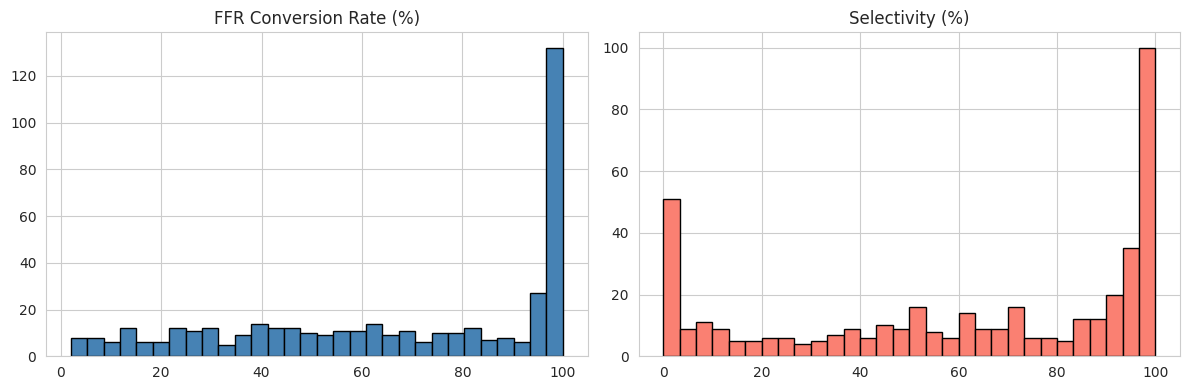

Top 10 features correlated with Conversion:
Solvent_volume_ml                           -0.337423
FFR_loading_g                               -0.279752
Catalyst_loading_g                          -0.268399
Calcination_temperature_C                   -0.243509
Reactive_metal_2_Loading_wt                  0.220601
Reactive_metal_1_Loading_wt                  0.218677
reaction_temperature_C                       0.211974
Reactive_metal_1_Electron_affinity_kJ_mol    0.203973
reaction_pressure_MPa                        0.178935
Reactive_metal_2_Electron_affinity_kJ_mol    0.152998
dtype: float64

Top 10 features correlated with Selectivity:
Reactive_metal_2_Atomic_radius_pm                0.415646
Reactive_metal_2_Ionization_energy_1st_kJ_mol    0.399521
Reactive_metal_2_Electronegativity_Pauling       0.385940
FFR_loading_g                                   -0.384793
Reactive_metal_2_d_band_filling                  0.360142
Reactive_metal_2_d_electron_count                0.360142
Reactiv

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_conversion, bins=30, color='steelblue', edgecolor='k')
axes[0].set_title('FFR Conversion Rate (%)')
axes[1].hist(y_selectivity, bins=30, color='salmon', edgecolor='k')
axes[1].set_title('Selectivity (%)')
plt.tight_layout()
plt.show()

corr_conv = X.select_dtypes(include=np.number).corrwith(y_conversion).sort_values(key=abs, ascending=False)
corr_sel = X.select_dtypes(include=np.number).corrwith(y_selectivity).sort_values(key=abs, ascending=False)

print("Top 10 features correlated with Conversion:")
print(corr_conv.head(10))
print("\nTop 10 features correlated with Selectivity:")
print(corr_sel.head(10))

## 10. Check multicollinearity (correlation > 0.9)

In [13]:
corr_matrix = X.select_dtypes(include=np.number).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = [(col, row, upper.loc[row, col])
                    for col in upper.columns for row in upper.index
                    if upper.loc[row, col] > 0.9]

print(f"Found {len(high_corr_pairs)} highly correlated feature pairs (>0.9):")
for col, row, val in sorted(high_corr_pairs, key=lambda x: -x[2]):
    print(f"  {row}  <->  {col}  :  {val:.3f}")

Found 12 highly correlated feature pairs (>0.9):
  Reactive_metal_2_d_electron_count  <->  Reactive_metal_2_d_band_filling  :  1.000
  Reactive_metal_1_d_electron_count  <->  Reactive_metal_1_d_band_filling  :  1.000
  Reactive_metal_2_Electronegativity_Pauling  <->  Reactive_metal_2_Ionization_energy_1st_kJ_mol  :  0.997
  Reactive_metal_2_Atomic_radius_pm  <->  Reactive_metal_2_Ionization_energy_1st_kJ_mol  :  0.980
  Reactive_metal_2_Electronegativity_Pauling  <->  Reactive_metal_2_Atomic_radius_pm  :  0.964
  Reactive_metal_2_Electronegativity_Pauling  <->  Reactive_metal_2_d_electron_count  :  0.950
  Reactive_metal_2_Electronegativity_Pauling  <->  Reactive_metal_2_d_band_filling  :  0.950
  Reactive_metal_2_Electron_affinity_kJ_mol  <->  Reactive_metal_2_d_electron_count  :  0.928
  Reactive_metal_2_Electron_affinity_kJ_mol  <->  Reactive_metal_2_d_band_filling  :  0.928
  Reactive_metal_2_Ionization_energy_1st_kJ_mol  <->  Reactive_metal_2_d_band_filling  :  0.927
  Reactive_me

## 11. Drop true duplicate features
- `d-electron count` <-> `d-band filling` (r=1.000, literally the same number rescaled)
- `Ionization energy` <-> `Electronegativity` (r=0.997, nearly the same physical concept)
- `Dielectric constant` <-> `Relative polarity` (r=0.924, relative polarity is derived from it)

Update the exact column names below to match your Cell 7 output if they differ.

In [14]:
drop_redundant = [c for c in [
    'Reactive_metal_1_d_electron_count', 'Reactive_metal_2_d_electron_count',
    'Reactive_metal_1_Ionization_energy_1st_kJ_mol', 'Reactive_metal_2_Ionization_energy_1st_kJ_mol',
    'Solvent_dielectric_constant',
] if c in X.columns]

print("Dropping:", drop_redundant)

Dropping: ['Reactive_metal_1_d_electron_count', 'Reactive_metal_2_d_electron_count', 'Reactive_metal_1_Ionization_energy_1st_kJ_mol', 'Reactive_metal_2_Ionization_energy_1st_kJ_mol', 'Solvent_dielectric_constant']


## 12. Train/test split

In [15]:
X_train, X_test, y_conv_train, y_conv_test, y_sel_train, y_sel_test = train_test_split(
    X, y_conversion, y_selectivity, test_size=0.2, random_state=42
)

X_train_reduced = X_train.drop(columns=drop_redundant)
X_test_reduced = X_test.drop(columns=drop_redundant)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train (reduced): {X_train_reduced.shape}, Test (reduced): {X_test_reduced.shape}")

# Save the split once so cleaning doesn't need to be rerun either
split_path = os.path.join(MODEL_DIR, "train_test_data.pkl")
if not os.path.exists(split_path) or FORCE_RETRAIN:
    save_object((X_train, X_test, X_train_reduced, X_test_reduced,
                 y_conv_train, y_conv_test, y_sel_train, y_sel_test), "train_test_data.pkl")
    print("Saved train/test split to Drive")

Train: (340, 40), Test: (86, 40)
Train (reduced): (340, 35), Test (reduced): (86, 35)


## 13. Baseline model comparison (quick, not yet tuned)

In [16]:
def evaluate_model(model, X_train, X_test, y_train, y_test, name):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    print(f"{name:20s} | R2: {r2:.4f} | MAE: {mae:.3f} | RMSE: {rmse:.3f}")
    return {'model': name, 'R2': r2, 'MAE': mae, 'RMSE': rmse}

models = {
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=300, random_state=42, verbosity=0),
    'LightGBM': lgb.LGBMRegressor(n_estimators=300, random_state=42, verbose=-1),
    'SVR': SVR(kernel='rbf', C=10),
    'Neural Net (MLP)': MLPRegressor(hidden_layer_sizes=(64,32), max_iter=2000, random_state=42),
}
# Note: Linear Regression is intentionally excluded — with ~40 correlated engineered
# features and ~350 training rows it produces unstable, unusable coefficients (R2 << 0).

In [17]:
print("=== Predicting FFR Conversion Rate (%) ===\n")
results_conv = []
for name, model in models.items():
    Xtr = X_train_scaled if name in ['Ridge','SVR','Neural Net (MLP)'] else X_train
    Xte = X_test_scaled if name in ['Ridge','SVR','Neural Net (MLP)'] else X_test
    results_conv.append(evaluate_model(model, Xtr, Xte, y_conv_train, y_conv_test, name))

results_conv_df = pd.DataFrame(results_conv).sort_values('R2', ascending=False)
results_conv_df

=== Predicting FFR Conversion Rate (%) ===

Ridge                | R2: -0.0116 | MAE: 23.661 | RMSE: 30.692
Random Forest        | R2: 0.5015 | MAE: 15.036 | RMSE: 21.545
Gradient Boosting    | R2: 0.4415 | MAE: 17.248 | RMSE: 22.805
XGBoost              | R2: 0.4622 | MAE: 14.373 | RMSE: 22.378
LightGBM             | R2: 0.6087 | MAE: 13.025 | RMSE: 19.088
SVR                  | R2: 0.1169 | MAE: 22.483 | RMSE: 28.676
Neural Net (MLP)     | R2: 0.3423 | MAE: 17.595 | RMSE: 24.748


,model,R2,MAE,RMSE
4,LightGBM,0.608692,13.025191,19.088417
1,Random Forest,0.501514,15.036257,21.544543
3,XGBoost,0.462180,14.372501,22.378402
2,Gradient Boosting,0.441495,17.247860,22.804688
6,Neural Net (MLP),0.342257,17.594962,24.747928
5,SVR,0.116909,22.483031,28.675654
0,Ridge,-0.011632,23.660571,30.691760


In [18]:
print("=== Predicting Selectivity (%) ===\n")
results_sel = []
for name, model in models.items():
    Xtr = X_train_scaled if name in ['Ridge','SVR','Neural Net (MLP)'] else X_train
    Xte = X_test_scaled if name in ['Ridge','SVR','Neural Net (MLP)'] else X_test
    results_sel.append(evaluate_model(model, Xtr, Xte, y_sel_train, y_sel_test, name))

results_sel_df = pd.DataFrame(results_sel).sort_values('R2', ascending=False)
results_sel_df

=== Predicting Selectivity (%) ===

Ridge                | R2: 0.0337 | MAE: 24.007 | RMSE: 34.070
Random Forest        | R2: 0.7194 | MAE: 12.976 | RMSE: 18.358
Gradient Boosting    | R2: 0.5870 | MAE: 16.410 | RMSE: 22.273
XGBoost              | R2: 0.6272 | MAE: 14.235 | RMSE: 21.163
LightGBM             | R2: 0.6835 | MAE: 13.369 | RMSE: 19.498
SVR                  | R2: 0.4555 | MAE: 19.092 | RMSE: 25.576
Neural Net (MLP)     | R2: 0.3534 | MAE: 16.705 | RMSE: 27.871


,model,R2,MAE,RMSE
1,Random Forest,0.719449,12.975796,18.358125
4,LightGBM,0.683531,13.369248,19.497907
3,XGBoost,0.627163,14.234537,21.163209
2,Gradient Boosting,0.587031,16.410219,22.273118
5,SVR,0.455463,19.091766,25.576194
6,Neural Net (MLP),0.353378,16.705317,27.870670
0,Ridge,0.033701,24.006775,34.070450


## 14. Hyperparameter search grids

In [19]:
rf_param_grid_random = {
    'n_estimators': [200, 300, 500, 800],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 0.5, 0.8],
}

xgb_param_grid_random = {
    'n_estimators': [200, 300, 500],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 5, 10],
}

# Narrowed grids for exhaustive GridSearchCV (run after RandomizedSearchCV below)
rf_grid = {
    'n_estimators': [150, 200, 300, 400],
    'max_depth': [None, 8, 12, 16, 20],
    'min_samples_split': [2, 3, 5],
    'min_samples_leaf': [1, 2, 3],
    'max_features': [0.4, 0.5, 0.6, 'sqrt'],
}

xgb_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.02, 0.05, 0.08, 0.1],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [1, 5, 10],
}

gb_grid = {
    'n_estimators': [150, 200, 300],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.02, 0.05, 0.1],
    'subsample': [0.7, 0.85, 1.0],
    'min_samples_leaf': [1, 3, 5],
}

## 15. RandomizedSearchCV (fast first pass) — all results saved to Drive

In [20]:
rf_search_conv = fit_or_load(
    RandomizedSearchCV(RandomForestRegressor(random_state=42), rf_param_grid_random,
                        n_iter=50, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "rf_search_conv.pkl", X_train_reduced, y_conv_train
)
print("RF Conversion (random search) - Best CV R2:", rf_search_conv.best_score_)

rf_search_sel = fit_or_load(
    RandomizedSearchCV(RandomForestRegressor(random_state=42), rf_param_grid_random,
                        n_iter=50, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "rf_search_sel.pkl", X_train_reduced, y_sel_train
)
print("RF Selectivity (random search) - Best CV R2:", rf_search_sel.best_score_)

xgb_search_conv = fit_or_load(
    RandomizedSearchCV(xgb.XGBRegressor(random_state=42, verbosity=0), xgb_param_grid_random,
                        n_iter=50, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "xgb_search_conv.pkl", X_train_reduced, y_conv_train
)
print("XGB Conversion (random search) - Best CV R2:", xgb_search_conv.best_score_)

xgb_search_sel = fit_or_load(
    RandomizedSearchCV(xgb.XGBRegressor(random_state=42, verbosity=0), xgb_param_grid_random,
                        n_iter=50, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "xgb_search_sel.pkl", X_train_reduced, y_sel_train
)
print("XGB Selectivity (random search) - Best CV R2:", xgb_search_sel.best_score_)

Loading saved model: rf_search_conv.pkl
RF Conversion (random search) - Best CV R2: 0.4970281805473774
Loading saved model: rf_search_sel.pkl
RF Selectivity (random search) - Best CV R2: 0.6808316745975747
Loading saved model: xgb_search_conv.pkl
XGB Conversion (random search) - Best CV R2: 0.5105296948571736
Loading saved model: xgb_search_sel.pkl
XGB Selectivity (random search) - Best CV R2: 0.6811956701911039


## 16. GridSearchCV (exhaustive, slow — only runs once thanks to fit_or_load)

In [21]:
rf_grid_conv = fit_or_load(
    GridSearchCV(RandomForestRegressor(random_state=42), rf_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1),
    "rf_grid_conv.pkl", X_train_reduced, y_conv_train
)
print("RF Conversion (grid) - Best params:", rf_grid_conv.best_params_)
print("RF Conversion (grid) - Best CV R2:", rf_grid_conv.best_score_)
print("RF Conversion (grid) - Test R2:", rf_grid_conv.best_estimator_.score(X_test_reduced, y_conv_test))

Loading saved model: rf_grid_conv.pkl
RF Conversion (grid) - Best params: {'max_depth': 12, 'max_features': 0.6, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
RF Conversion (grid) - Best CV R2: 0.5032448357677719
RF Conversion (grid) - Test R2: 0.5043029318022112


In [22]:
rf_grid_sel = fit_or_load(
    GridSearchCV(RandomForestRegressor(random_state=42), rf_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1),
    "rf_grid_sel.pkl", X_train_reduced, y_sel_train
)
print("RF Selectivity (grid) - Best params:", rf_grid_sel.best_params_)
print("RF Selectivity (grid) - Best CV R2:", rf_grid_sel.best_score_)
print("RF Selectivity (grid) - Test R2:", rf_grid_sel.best_estimator_.score(X_test_reduced, y_sel_test))

Loading saved model: rf_grid_sel.pkl
RF Selectivity (grid) - Best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
RF Selectivity (grid) - Best CV R2: 0.6827353215148719
RF Selectivity (grid) - Test R2: 0.6836705396301366


In [23]:
xgb_grid_conv = fit_or_load(
    GridSearchCV(xgb.XGBRegressor(random_state=42, verbosity=0), xgb_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1),
    "xgb_grid_conv.pkl", X_train_reduced, y_conv_train
)
print("XGB Conversion (grid) - Best CV R2:", xgb_grid_conv.best_score_,
      "| Test R2:", xgb_grid_conv.best_estimator_.score(X_test_reduced, y_conv_test))

Loading saved model: xgb_grid_conv.pkl
XGB Conversion (grid) - Best CV R2: 0.512443755250055 | Test R2: 0.5523911950888687


In [24]:
xgb_grid_sel = fit_or_load(
    GridSearchCV(xgb.XGBRegressor(random_state=42, verbosity=0), xgb_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1),
    "xgb_grid_sel.pkl", X_train_reduced, y_sel_train
)
print("XGB Selectivity (grid) - Best CV R2:", xgb_grid_sel.best_score_,
      "| Test R2:", xgb_grid_sel.best_estimator_.score(X_test_reduced, y_sel_test))

Loading saved model: xgb_grid_sel.pkl
XGB Selectivity (grid) - Best CV R2: 0.6906032680657331 | Test R2: 0.6959887282396351


In [25]:
gb_grid_conv = fit_or_load(
    GridSearchCV(GradientBoostingRegressor(random_state=42), gb_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1),
    "gb_grid_conv.pkl", X_train_reduced, y_conv_train
)
print("GB Conversion (grid) - Best CV R2:", gb_grid_conv.best_score_,
      "| Test R2:", gb_grid_conv.best_estimator_.score(X_test_reduced, y_conv_test))

gb_grid_sel = fit_or_load(
    GridSearchCV(GradientBoostingRegressor(random_state=42), gb_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1),
    "gb_grid_sel.pkl", X_train_reduced, y_sel_train
)
print("GB Selectivity (grid) - Best CV R2:", gb_grid_sel.best_score_,
      "| Test R2:", gb_grid_sel.best_estimator_.score(X_test_reduced, y_sel_test))

Loading saved model: gb_grid_conv.pkl
GB Conversion (grid) - Best CV R2: 0.4987924452458266 | Test R2: 0.5216045878554874
Loading saved model: gb_grid_sel.pkl
GB Selectivity (grid) - Best CV R2: 0.6578451877431271 | Test R2: 0.686391809936278


## 17. Stacked ensemble (RF + XGBoost + GB, using the tuned base learners)

In [26]:
stack_conv_grid = fit_or_load(
    StackingRegressor(
        estimators=[('rf', rf_grid_conv.best_estimator_),
                    ('xgb', xgb_grid_conv.best_estimator_),
                    ('gb', gb_grid_conv.best_estimator_)],
        final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 20)), cv=5, n_jobs=-1
    ),
    "stack_conv_grid.pkl", X_train_reduced, y_conv_train
)
r2_stack_conv = r2_score(y_conv_test, stack_conv_grid.predict(X_test_reduced))
print("Stacked Conversion - Test R2:", r2_stack_conv)

stack_sel_grid = fit_or_load(
    StackingRegressor(
        estimators=[('rf', rf_grid_sel.best_estimator_),
                    ('xgb', xgb_grid_sel.best_estimator_),
                    ('gb', gb_grid_sel.best_estimator_)],
        final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 20)), cv=5, n_jobs=-1
    ),
    "stack_sel_grid.pkl", X_train_reduced, y_sel_train
)
r2_stack_sel = r2_score(y_sel_test, stack_sel_grid.predict(X_test_reduced))
print("Stacked Selectivity - Test R2:", r2_stack_sel)

Loading saved model: stack_conv_grid.pkl
Stacked Conversion - Test R2: 0.5573093102817648
Loading saved model: stack_sel_grid.pkl
Stacked Selectivity - Test R2: 0.6961367415316532


## 18. Final summary table

In [27]:
summary = pd.DataFrame({
    'Target': ['Conversion']*4 + ['Selectivity']*4,
    'Model': ['RF (grid)', 'XGB (grid)', 'GB (grid)', 'Stacked']*2,
    'CV_R2': [rf_grid_conv.best_score_, xgb_grid_conv.best_score_, gb_grid_conv.best_score_, np.nan,
              rf_grid_sel.best_score_, xgb_grid_sel.best_score_, gb_grid_sel.best_score_, np.nan],
    'Test_R2': [rf_grid_conv.best_estimator_.score(X_test_reduced, y_conv_test),
                xgb_grid_conv.best_estimator_.score(X_test_reduced, y_conv_test),
                gb_grid_conv.best_estimator_.score(X_test_reduced, y_conv_test),
                r2_stack_conv,
                rf_grid_sel.best_estimator_.score(X_test_reduced, y_sel_test),
                xgb_grid_sel.best_estimator_.score(X_test_reduced, y_sel_test),
                gb_grid_sel.best_estimator_.score(X_test_reduced, y_sel_test),
                r2_stack_sel],
})
summary

,Target,Model,CV_R2,Test_R2
0,Conversion,RF (grid),0.503245,0.504303
1,Conversion,XGB (grid),0.512444,0.552391
2,Conversion,GB (grid),0.498792,0.521605
3,Conversion,Stacked,NaN,0.557309
4,Selectivity,RF (grid),0.682735,0.683671
5,Selectivity,XGB (grid),0.690603,0.695989
6,Selectivity,GB (grid),0.657845,0.686392
7,Selectivity,Stacked,NaN,0.696137


## 19. Predicted vs Actual plots (uses the actual best model per target)

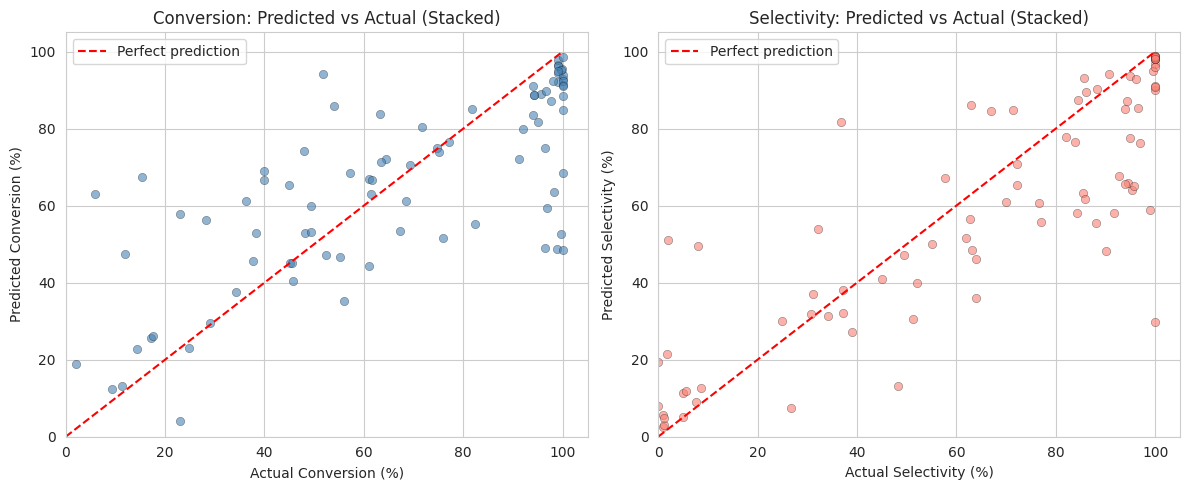

In [28]:
best_conv_row = summary[summary['Target']=='Conversion'].sort_values('Test_R2', ascending=False).iloc[0]
best_sel_row = summary[summary['Target']=='Selectivity'].sort_values('Test_R2', ascending=False).iloc[0]

model_lookup = {
    'RF (grid)': (rf_grid_conv.best_estimator_, rf_grid_sel.best_estimator_),
    'XGB (grid)': (xgb_grid_conv.best_estimator_, xgb_grid_sel.best_estimator_),
    'GB (grid)': (gb_grid_conv.best_estimator_, gb_grid_sel.best_estimator_),
    'Stacked': (stack_conv_grid, stack_sel_grid),
}

best_conv_model = model_lookup[best_conv_row['Model']][0]
best_sel_model = model_lookup[best_sel_row['Model']][1]

preds_conv = best_conv_model.predict(X_test_reduced)
preds_sel = best_sel_model.predict(X_test_reduced)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_conv_test, preds_conv, alpha=0.6, color='steelblue', edgecolor='k', linewidth=0.3)
axes[0].plot([0,100],[0,100],'r--', label='Perfect prediction')
axes[0].set_xlabel('Actual Conversion (%)'); axes[0].set_ylabel('Predicted Conversion (%)')
axes[0].set_title(f"Conversion: Predicted vs Actual ({best_conv_row['Model']})")
axes[0].set_xlim(0,105); axes[0].set_ylim(0,105); axes[0].legend()

axes[1].scatter(y_sel_test, preds_sel, alpha=0.6, color='salmon', edgecolor='k', linewidth=0.3)
axes[1].plot([0,100],[0,100],'r--', label='Perfect prediction')
axes[1].set_xlabel('Actual Selectivity (%)'); axes[1].set_ylabel('Predicted Selectivity (%)')
axes[1].set_title(f"Selectivity: Predicted vs Actual ({best_sel_row['Model']})")
axes[1].set_xlim(0,105); axes[1].set_ylim(0,105); axes[1].legend()

plt.tight_layout()
plt.show()

## 20. Feature importance (best Conversion model)

In [29]:
if hasattr(best_conv_model, 'feature_importances_'):
    importances = pd.Series(best_conv_model.feature_importances_, index=X_train_reduced.columns).sort_values(ascending=False)
    plt.figure(figsize=(8,8))
    importances.head(15).plot(kind='barh')
    plt.gca().invert_yaxis()
    plt.title('Top 15 Features — Conversion Model')
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_conv_row['Model']} does not expose feature_importances_ directly (e.g. stacked ensemble).")

Stacked does not expose feature_importances_ directly (e.g. stacked ensemble).


---
# 21. Neural Networks


### 21.1 Scale features for NN (tree models didn't need this, NN does)

In [30]:
scaler_nn_path = os.path.join(MODEL_DIR, "scaler_nn.pkl")
if os.path.exists(scaler_nn_path) and not FORCE_RETRAIN:
    scaler_nn = joblib.load(scaler_nn_path)
    print("Loaded saved NN scaler")
else:
    scaler_nn = StandardScaler().fit(X_train_reduced)
    joblib.dump(scaler_nn, scaler_nn_path)
    print("Fit and saved new NN scaler")

X_train_nn = scaler_nn.transform(X_train_reduced)
X_test_nn = scaler_nn.transform(X_test_reduced)

print("X_train_nn:", X_train_nn.shape, " X_test_nn:", X_test_nn.shape)

Loaded saved NN scaler
X_train_nn: (340, 35)  X_test_nn: (86, 35)


### 21.2 Sklearn MLPRegressor — tuned baseline NN (fast, good sanity check)

In [31]:
mlp_param_grid = {
    'hidden_layer_sizes': [(32,), (64,), (64,32), (128,64), (128,64,32)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01, 0.1],
    'learning_rate_init': [0.001, 0.01],
    'max_iter': [3000],
    'early_stopping': [True],
}

mlp_search_conv = fit_or_load(
    RandomizedSearchCV(MLPRegressor(random_state=42), mlp_param_grid,
                        n_iter=30, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "mlp_search_conv.pkl", X_train_nn, y_conv_train
)
print("MLP Conversion - Best CV R2:", mlp_search_conv.best_score_)
print("MLP Conversion - Test R2:", mlp_search_conv.best_estimator_.score(X_test_nn, y_conv_test))

mlp_search_sel = fit_or_load(
    RandomizedSearchCV(MLPRegressor(random_state=42), mlp_param_grid,
                        n_iter=30, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "mlp_search_sel.pkl", X_train_nn, y_sel_train
)
print("MLP Selectivity - Best CV R2:", mlp_search_sel.best_score_)
print("MLP Selectivity - Test R2:", mlp_search_sel.best_estimator_.score(X_test_nn, y_sel_test))

Loading saved model: mlp_search_conv.pkl
MLP Conversion - Best CV R2: 0.3386525945920461
MLP Conversion - Test R2: 0.1933794942816207
Loading saved model: mlp_search_sel.pkl
MLP Selectivity - Best CV R2: 0.5113098851244431
MLP Selectivity - Test R2: 0.4818004384288881


### 21.3 Deep Keras network — custom architecture with early stopping

In [32]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

tf.random.set_seed(42)

def build_nn_model(input_dim, units1=128, units2=64, units3=32, dropout=0.2, lr=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(units1, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(dropout),
        layers.Dense(units2, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(dropout),
        layers.Dense(units3, activation='relu'),
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse', metrics=['mae'])
    return model

def fit_or_load_keras(build_fn, filename, X_train, y_train, X_val, y_val,
                       epochs=500, batch_size=16, patience=30, **build_kwargs):
    """Same idea as fit_or_load(), but for Keras models (joblib can't save these)."""
    path = os.path.join(MODEL_DIR, filename)
    if os.path.exists(path) and not FORCE_RETRAIN:
        print(f"Loading saved Keras model: {filename}")
        return keras.models.load_model(path)
    print(f"No saved model found — training {filename} ...")
    model = build_fn(X_train.shape[1], **build_kwargs)
    es = callbacks.EarlyStopping(patience=patience, restore_best_weights=True, monitor='val_loss')
    model.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=epochs, batch_size=batch_size, callbacks=[es], verbose=0)
    model.save(path)
    print(f"Saved to {path}")
    return model

In [33]:
# Carve out a validation split from the training data (test set stays untouched for final scoring)
X_tr_conv, X_val_conv, y_tr_conv, y_val_conv = train_test_split(
    X_train_nn, y_conv_train, test_size=0.15, random_state=42
)
X_tr_sel, X_val_sel, y_tr_sel, y_val_sel = train_test_split(
    X_train_nn, y_sel_train, test_size=0.15, random_state=42
)

nn_conv = fit_or_load_keras(
    build_nn_model, "nn_conv.keras", X_tr_conv, y_tr_conv, X_val_conv, y_val_conv,
    epochs=500, batch_size=16, units1=128, units2=64, units3=32, dropout=0.25, lr=0.001
)
preds_nn_conv = nn_conv.predict(X_test_nn, verbose=0).flatten()
r2_nn_conv = r2_score(y_conv_test, preds_nn_conv)
print("Deep NN Conversion - Test R2:", r2_nn_conv)

nn_sel = fit_or_load_keras(
    build_nn_model, "nn_sel.keras", X_tr_sel, y_tr_sel, X_val_sel, y_val_sel,
    epochs=500, batch_size=16, units1=128, units2=64, units3=32, dropout=0.25, lr=0.001
)
preds_nn_sel = nn_sel.predict(X_test_nn, verbose=0).flatten()
r2_nn_sel = r2_score(y_sel_test, preds_nn_sel)
print("Deep NN Selectivity - Test R2:", r2_nn_sel)

Loading saved Keras model: nn_conv.keras
Deep NN Conversion - Test R2: 0.5417049106502019
Loading saved Keras model: nn_sel.keras
Deep NN Selectivity - Test R2: 0.6003958523126522


### 21.4 KerasTuner — automated architecture search (resumable)

`overwrite=False` means if your runtime disconnects mid-search, re-running this cell
picks up from the last completed trial instead of starting over — the trial history is
stored directly in your Drive folder, not just in memory.

In [34]:
!pip install -q keras-tuner
import keras_tuner as kt

KERAS_TUNER_DIR = os.path.join(MODEL_DIR, "keras_tuner")

def tune_or_load_nn(target_name, X_tr, y_tr, X_val, y_val, max_trials=25, epochs=300):
    final_path = os.path.join(MODEL_DIR, f"nn_{target_name}_tuned.keras")
    if os.path.exists(final_path) and not FORCE_RETRAIN:
        print(f"Loading saved TUNED NN for {target_name}")
        return keras.models.load_model(final_path)

    def build_model_tuner(hp):
        model = keras.Sequential()
        model.add(layers.Input(shape=(X_tr.shape[1],)))
        for i in range(hp.Int('num_layers', 1, 3)):
            model.add(layers.Dense(hp.Choice(f'units_{i}', [32, 64, 128, 256]), activation='relu'))
            model.add(layers.BatchNormalization())
            model.add(layers.Dropout(hp.Float(f'dropout_{i}', 0.0, 0.5, step=0.1)))
        model.add(layers.Dense(1))
        lr = hp.Choice('learning_rate', [1e-2, 1e-3, 5e-4, 1e-4])
        model.compile(optimizer=keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])
        return model

    tuner = kt.RandomSearch(
        build_model_tuner, objective='val_loss', max_trials=max_trials,
        directory=KERAS_TUNER_DIR, project_name=f'nn_{target_name}', overwrite=False
    )
    es = callbacks.EarlyStopping(patience=25, restore_best_weights=True, monitor='val_loss')
    print(f"Searching architectures for {target_name} (resumes automatically if interrupted)...")
    tuner.search(X_tr, y_tr, validation_data=(X_val, y_val), epochs=epochs, callbacks=[es], verbose=0)

    best_model = tuner.get_best_models(num_models=1)[0]
    best_model.save(final_path)
    print(f"Saved tuned NN to {final_path}")
    return best_model

In [35]:
nn_conv_tuned = tune_or_load_nn('conversion', X_tr_conv, y_tr_conv, X_val_conv, y_val_conv)
preds_nn_conv_tuned = nn_conv_tuned.predict(X_test_nn, verbose=0).flatten()
r2_nn_conv_tuned = r2_score(y_conv_test, preds_nn_conv_tuned)
print("Tuned NN Conversion - Test R2:", r2_nn_conv_tuned)

nn_sel_tuned = tune_or_load_nn('selectivity', X_tr_sel, y_tr_sel, X_val_sel, y_val_sel)
preds_nn_sel_tuned = nn_sel_tuned.predict(X_test_nn, verbose=0).flatten()
r2_nn_sel_tuned = r2_score(y_sel_test, preds_nn_sel_tuned)
print("Tuned NN Selectivity - Test R2:", r2_nn_sel_tuned)

Loading saved TUNED NN for conversion


Tuned NN Conversion - Test R2: 0.46210858833333845
Loading saved TUNED NN for selectivity
Tuned NN Selectivity - Test R2: 0.6158058341360793


### 21.5 Blend: tree ensemble + tuned NN (simple weighted average)

Trees and neural nets tend to make *different kinds* of errors, so averaging their
predictions sometimes beats either one alone. Cheap to try, no extra training needed.

In [36]:
tree_preds_conv = stack_conv_grid.predict(X_test_reduced)
tree_preds_sel = stack_sel_grid.predict(X_test_reduced)

best_blend_conv_r2, best_blend_conv_w = -np.inf, 0.5
best_blend_sel_r2, best_blend_sel_w = -np.inf, 0.5

for w in np.arange(0.0, 1.05, 0.05):
    blend_conv = w * tree_preds_conv + (1 - w) * preds_nn_conv_tuned
    r2 = r2_score(y_conv_test, blend_conv)
    if r2 > best_blend_conv_r2:
        best_blend_conv_r2, best_blend_conv_w = r2, w

    blend_sel = w * tree_preds_sel + (1 - w) * preds_nn_sel_tuned
    r2 = r2_score(y_sel_test, blend_sel)
    if r2 > best_blend_sel_r2:
        best_blend_sel_r2, best_blend_sel_w = r2, w

print(f"Best blend Conversion: {best_blend_conv_w:.2f}*trees + {1-best_blend_conv_w:.2f}*NN -> R2 = {best_blend_conv_r2:.4f}")
print(f"Best blend Selectivity: {best_blend_sel_w:.2f}*trees + {1-best_blend_sel_w:.2f}*NN -> R2 = {best_blend_sel_r2:.4f}")

Best blend Conversion: 0.75*trees + 0.25*NN -> R2 = 0.5705
Best blend Selectivity: 0.80*trees + 0.20*NN -> R2 = 0.7004


## 22. Updated final summary — trees vs NN vs blend

In [37]:
summary_nn = pd.DataFrame({
    'Target': ['Conversion']*4 + ['Selectivity']*4,
    'Model': ['Stacked (trees)', 'MLP (sklearn)', 'Deep NN (tuned)', 'Blend (best weight)']*2,
    'Test_R2': [
        r2_score(y_conv_test, tree_preds_conv),
        mlp_search_conv.best_estimator_.score(X_test_nn, y_conv_test),
        r2_nn_conv_tuned,
        best_blend_conv_r2,
        r2_score(y_sel_test, tree_preds_sel),
        mlp_search_sel.best_estimator_.score(X_test_nn, y_sel_test),
        r2_nn_sel_tuned,
        best_blend_sel_r2,
    ],
})
summary_all = pd.concat([summary, summary_nn], ignore_index=True)
summary_all.sort_values(['Target', 'Test_R2'], ascending=[True, False])

,Target,Model,CV_R2,Test_R2
11,Conversion,Blend (best weight),NaN,0.570459
3,Conversion,Stacked,NaN,0.557309
8,Conversion,Stacked (trees),NaN,0.557309
1,Conversion,XGB (grid),0.512444,0.552391
2,Conversion,GB (grid),0.498792,0.521605
0,Conversion,RF (grid),0.503245,0.504303
10,Conversion,Deep NN (tuned),NaN,0.462109
9,Conversion,MLP (sklearn),NaN,0.193379
15,Selectivity,Blend (best weight),NaN,0.700423
7,Selectivity,Stacked,NaN,0.696137


---
# 23. Extending the model search — closing the R2 gap

Everything above (through section 22) is left **exactly as it was** — same cleaning, same
features, same baseline/grid/stacked/NN models, same `fit_or_load` persistence pattern.

Below, more model families and search strategies are added on top, aimed specifically at
the R2 ceiling (~0.6–0.7) seen so far. With ~350 rows and ~35-40 features, the likely
culprits are (a) too many correlated/noisy features for the sample size, and (b)
grid/random search not finding great hyperparameters in a reasonable budget. The new
sections address both:

- **Feature selection (RFECV)** — cuts down to the features that actually carry signal.
- **CatBoost, Extra Trees** — two strong tabular learners not tried yet.
- **PLS Regression, Kernel Ridge, Gaussian Process** — built for small-n / correlated-feature
  regimes, unlike tree ensembles which need more rows to shine.
- **Optuna (Bayesian hyperparameter search)** — much more sample-efficient than
  Grid/RandomizedSearchCV, usually finds a better optimum in fewer fits.
- **Repeated K-Fold CV** — a single 80/20 test R2 on ~70 test rows is noisy; repeated CV
  gives a mean ± std that's far more trustworthy for picking a real winner.
- **A mega stacking ensemble** across the strongest, most *diverse* models.
- **A final grand comparison** across literally every model tried (old + new), which saves
  the true best model per target separately.

Every new model is trained (or loaded, if already saved) through the same `fit_or_load` /
`save_object` helpers from section 1, so everything lands in `MODEL_DIR` on Drive exactly
as before.

## 24. Feature selection (RFECV) — reduce dimensionality for a small-sample dataset

In [38]:
from sklearn.feature_selection import RFECV
from sklearn.model_selection import KFold

rfecv_conv = fit_or_load(
    RFECV(estimator=RandomForestRegressor(n_estimators=300, random_state=42),
          step=1, cv=KFold(5, shuffle=True, random_state=42), scoring='r2',
          min_features_to_select=5, n_jobs=-1),
    "rfecv_conv.pkl", X_train_reduced, y_conv_train
)
selected_features_conv = X_train_reduced.columns[rfecv_conv.support_].tolist()
print(f"RFECV selected {rfecv_conv.n_features_} / {X_train_reduced.shape[1]} features for Conversion:")
print(selected_features_conv)

rfecv_sel = fit_or_load(
    RFECV(estimator=RandomForestRegressor(n_estimators=300, random_state=42),
          step=1, cv=KFold(5, shuffle=True, random_state=42), scoring='r2',
          min_features_to_select=5, n_jobs=-1),
    "rfecv_sel.pkl", X_train_reduced, y_sel_train
)
selected_features_sel = X_train_reduced.columns[rfecv_sel.support_].tolist()
print(f"\nRFECV selected {rfecv_sel.n_features_} / {X_train_reduced.shape[1]} features for Selectivity:")
print(selected_features_sel)

X_train_fs_conv = X_train_reduced[selected_features_conv]
X_test_fs_conv  = X_test_reduced[selected_features_conv]
X_train_fs_sel  = X_train_reduced[selected_features_sel]
X_test_fs_sel   = X_test_reduced[selected_features_sel]


Loading saved model: rfecv_conv.pkl
RFECV selected 34 / 35 features for Conversion:
['Surface_Area_m2_g', 'Reactive_metal_1_Loading_wt', 'Reactive_metal_2_Loading_wt', 'Reducing_temperature_C', 'Calcination_temperature_C', 'Solvent_volume_ml', 'reaction_temperature_C', 'reaction_pressure_MPa', 'reaction_time_h', 'FFR_loading_g', 'Catalyst_loading_g', 'Reactive_metal_1_Electronegativity_Pauling', 'Reactive_metal_1_Atomic_radius_pm', 'Reactive_metal_1_Electron_affinity_kJ_mol', 'Reactive_metal_1_d_band_filling', 'Reactive_metal_2_Electronegativity_Pauling', 'Reactive_metal_2_Atomic_radius_pm', 'Reactive_metal_2_Electron_affinity_kJ_mol', 'Reactive_metal_2_d_band_filling', 'Solvent_boiling_point_C', 'Solvent_density_g_mL', 'Solvent_dipole_moment_D', 'Solvent_viscosity_cP_20_25C', 'Solvent_relative_polarity_0_1_scale', 'Support_pore_volume_cm3_g', 'Support_total_acidity_mmol_NH3_g', 'H2_source_H2', 'H2_source_ethanol', 'H2_source_isopropanol', 'H2_source_methanol', 'H2_source_n_butanol', '

## 25. CatBoost — often strong on small/medium tabular data

In [39]:
!pip install -q catboost
from catboost import CatBoostRegressor

cat_param_grid = {
    'iterations': [300, 500, 800],
    'depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5, 10],
    'subsample': [0.7, 0.85, 1.0],
}

cat_search_conv = fit_or_load(
    RandomizedSearchCV(CatBoostRegressor(random_state=42, verbose=0), cat_param_grid,
                        n_iter=40, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "cat_search_conv.pkl", X_train_reduced, y_conv_train
)
print("CatBoost Conversion - Best CV R2:", cat_search_conv.best_score_,
      "| Test R2:", cat_search_conv.best_estimator_.score(X_test_reduced, y_conv_test))

cat_search_sel = fit_or_load(
    RandomizedSearchCV(CatBoostRegressor(random_state=42, verbose=0), cat_param_grid,
                        n_iter=40, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "cat_search_sel.pkl", X_train_reduced, y_sel_train
)
print("CatBoost Selectivity - Best CV R2:", cat_search_sel.best_score_,
      "| Test R2:", cat_search_sel.best_estimator_.score(X_test_reduced, y_sel_test))


Loading saved model: cat_search_conv.pkl
CatBoost Conversion - Best CV R2: 0.4924211931008865 | Test R2: 0.6034296839479778
Loading saved model: cat_search_sel.pkl
CatBoost Selectivity - Best CV R2: 0.7048951834490766 | Test R2: 0.7447797676368652


## 26. Extra Trees Regressor

In [40]:
from sklearn.ensemble import ExtraTreesRegressor

et_param_grid = {
    'n_estimators': [200, 300, 500, 800],
    'max_depth': [None, 8, 12, 16, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 0.5, 0.8],
}

et_search_conv = fit_or_load(
    RandomizedSearchCV(ExtraTreesRegressor(random_state=42), et_param_grid,
                        n_iter=50, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "et_search_conv.pkl", X_train_reduced, y_conv_train
)
print("ExtraTrees Conversion - Best CV R2:", et_search_conv.best_score_,
      "| Test R2:", et_search_conv.best_estimator_.score(X_test_reduced, y_conv_test))

et_search_sel = fit_or_load(
    RandomizedSearchCV(ExtraTreesRegressor(random_state=42), et_param_grid,
                        n_iter=50, cv=5, scoring='r2', random_state=42, n_jobs=-1),
    "et_search_sel.pkl", X_train_reduced, y_sel_train
)
print("ExtraTrees Selectivity - Best CV R2:", et_search_sel.best_score_,
      "| Test R2:", et_search_sel.best_estimator_.score(X_test_reduced, y_sel_test))


Loading saved model: et_search_conv.pkl
ExtraTrees Conversion - Best CV R2: 0.4902325101982676 | Test R2: 0.5252358462255675
Loading saved model: et_search_sel.pkl
ExtraTrees Selectivity - Best CV R2: 0.6970992770612299 | Test R2: 0.7054860229599524


## 27. Partial Least Squares Regression
PLS builds latent components that maximize covariance with the target, which makes it
naturally robust to the correlated descriptor pairs seen in section 10 — unlike tree
ensembles, it's a classic choice for small-n, correlated-feature chemistry datasets.

In [41]:
from sklearn.cross_decomposition import PLSRegression

pls_param_grid = {'n_components': list(range(1, min(20, X_train_scaled.shape[1]) + 1))}

pls_search_conv = fit_or_load(
    GridSearchCV(PLSRegression(), pls_param_grid, cv=5, scoring='r2', n_jobs=-1),
    "pls_search_conv.pkl", X_train_scaled, y_conv_train
)
print("PLS Conversion - Best params:", pls_search_conv.best_params_,
      "| Best CV R2:", pls_search_conv.best_score_,
      "| Test R2:", pls_search_conv.best_estimator_.score(X_test_scaled, y_conv_test))

pls_search_sel = fit_or_load(
    GridSearchCV(PLSRegression(), pls_param_grid, cv=5, scoring='r2', n_jobs=-1),
    "pls_search_sel.pkl", X_train_scaled, y_sel_train
)
print("PLS Selectivity - Best params:", pls_search_sel.best_params_,
      "| Best CV R2:", pls_search_sel.best_score_,
      "| Test R2:", pls_search_sel.best_estimator_.score(X_test_scaled, y_sel_test))


Loading saved model: pls_search_conv.pkl
PLS Conversion - Best params: {'n_components': 11} | Best CV R2: 0.24092090606336 | Test R2: 0.11095889318625263
Loading saved model: pls_search_sel.pkl
PLS Selectivity - Best params: {'n_components': 6} | Best CV R2: 0.355191896882772 | Test R2: 0.3067150247936792


## 28. Kernel Ridge Regression

In [42]:
from sklearn.kernel_ridge import KernelRidge

kr_param_grid = {
    'alpha': [0.01, 0.1, 1, 10],
    'kernel': ['rbf', 'poly', 'laplacian'],
    'gamma': [0.001, 0.01, 0.1, 1, None],
}

kr_search_conv = fit_or_load(
    GridSearchCV(KernelRidge(), kr_param_grid, cv=5, scoring='r2', n_jobs=-1),
    "kr_search_conv.pkl", X_train_scaled, y_conv_train
)
print("KernelRidge Conversion - Best params:", kr_search_conv.best_params_,
      "| Best CV R2:", kr_search_conv.best_score_,
      "| Test R2:", kr_search_conv.best_estimator_.score(X_test_scaled, y_conv_test))

kr_search_sel = fit_or_load(
    GridSearchCV(KernelRidge(), kr_param_grid, cv=5, scoring='r2', n_jobs=-1),
    "kr_search_sel.pkl", X_train_scaled, y_sel_train
)
print("KernelRidge Selectivity - Best params:", kr_search_sel.best_params_,
      "| Best CV R2:", kr_search_sel.best_score_,
      "| Test R2:", kr_search_sel.best_estimator_.score(X_test_scaled, y_sel_test))


Loading saved model: kr_search_conv.pkl
KernelRidge Conversion - Best params: {'alpha': 0.01, 'gamma': None, 'kernel': 'laplacian'} | Best CV R2: 0.44279348775821925 | Test R2: 0.5456298164203732
Loading saved model: kr_search_sel.pkl
KernelRidge Selectivity - Best params: {'alpha': 0.1, 'gamma': 0.1, 'kernel': 'laplacian'} | Best CV R2: 0.6534969645631874 | Test R2: 0.7037901708284893


## 29. Gaussian Process Regression — well suited to small datasets

In [43]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C

gp_kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1.0)

gp_conv = fit_or_load(
    GaussianProcessRegressor(kernel=gp_kernel, normalize_y=True, n_restarts_optimizer=5, random_state=42),
    "gp_conv.pkl", X_train_scaled, y_conv_train
)
print("Gaussian Process Conversion - Test R2:", gp_conv.score(X_test_scaled, y_conv_test))

gp_sel = fit_or_load(
    GaussianProcessRegressor(kernel=gp_kernel, normalize_y=True, n_restarts_optimizer=5, random_state=42),
    "gp_sel.pkl", X_train_scaled, y_sel_train
)
print("Gaussian Process Selectivity - Test R2:", gp_sel.score(X_test_scaled, y_sel_test))


Loading saved model: gp_conv.pkl
Gaussian Process Conversion - Test R2: 0.42961501258187273
Loading saved model: gp_sel.pkl
Gaussian Process Selectivity - Test R2: 0.7056182945858371


## 30. Bayesian Ridge & KNN baselines

In [44]:
from sklearn.linear_model import BayesianRidge
from sklearn.neighbors import KNeighborsRegressor

extra_baselines = {
    'Bayesian Ridge': BayesianRidge(),
    'KNN (k=5)': KNeighborsRegressor(n_neighbors=5),
    'KNN (k=7)': KNeighborsRegressor(n_neighbors=7),
}

print("=== Extra baselines: Conversion ===")
results_extra_conv = []
for name, model in extra_baselines.items():
    results_extra_conv.append(evaluate_model(model, X_train_scaled, X_test_scaled, y_conv_train, y_conv_test, name))

print("\n=== Extra baselines: Selectivity ===")
results_extra_sel = []
for name, model in extra_baselines.items():
    results_extra_sel.append(evaluate_model(model, X_train_scaled, X_test_scaled, y_sel_train, y_sel_test, name))


=== Extra baselines: Conversion ===
Bayesian Ridge       | R2: 0.2115 | MAE: 21.850 | RMSE: 27.096
KNN (k=5)            | R2: 0.1253 | MAE: 21.245 | RMSE: 28.539
KNN (k=7)            | R2: 0.0051 | MAE: 23.188 | RMSE: 30.437

=== Extra baselines: Selectivity ===
Bayesian Ridge       | R2: 0.3722 | MAE: 21.970 | RMSE: 27.462
KNN (k=5)            | R2: 0.5029 | MAE: 17.269 | RMSE: 24.437
KNN (k=7)            | R2: 0.3985 | MAE: 19.896 | RMSE: 26.880


## 31. Optuna — Bayesian hyperparameter optimization
Optuna's TPE sampler picks each next trial based on what's worked so far, instead of
sampling blindly like RandomizedSearchCV. For a fixed number of fits it typically lands on
a meaningfully better hyperparameter set — worth trying on the three strongest boosters.

In [45]:
!pip install -q optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

class OptunaResult:
    """Version-safe stand-in for optuna.Study: stores only best_params/best_value,
    so pickling it never breaks when Optuna's internal Study/sampler classes change
    between versions (which is what caused the original TypeError on load)."""
    def __init__(self, best_params, best_value):
        self.best_params = best_params
        self.best_value = best_value

def optuna_tune(model_name, target_name, X_tr, y_tr, objective_fn, n_trials=60):
    study_path = os.path.join(MODEL_DIR, f"optuna_{model_name}_{target_name}.pkl")

    if os.path.exists(study_path) and not FORCE_RETRAIN:
        try:
            loaded = joblib.load(study_path)
            if isinstance(loaded, OptunaResult):
                result = loaded
            elif isinstance(loaded, dict):
                result = OptunaResult(loaded['best_params'], loaded['best_value'])
            else:
                # a real optuna.Study object, loaded successfully (Optuna version matches)
                result = OptunaResult(loaded.best_params, loaded.best_value)
            print(f"Loading saved Optuna result: optuna_{model_name}_{target_name}.pkl")
            print(f"{model_name} ({target_name}) - Best CV R2: {result.best_value:.4f}")
            print(f"Best params: {result.best_params}")
            return result
        except Exception as e:
            print(f"Could not load {study_path} ({type(e).__name__}: {e}) - retraining from scratch.")
            os.remove(study_path)

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(lambda trial: objective_fn(trial, X_tr, y_tr), n_trials=n_trials, show_progress_bar=False)
    result = OptunaResult(study.best_params, study.best_value)
    joblib.dump(result, study_path)
    print(f"Saved Optuna result to {study_path}")
    print(f"{model_name} ({target_name}) - Best CV R2: {result.best_value:.4f}")
    print(f"Best params: {result.best_params}")
    return result

def xgb_objective(trial, X_tr, y_tr):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 150, 800),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'random_state': 42, 'verbosity': 0,
    }
    model = xgb.XGBRegressor(**params)
    return cross_val_score(model, X_tr, y_tr, cv=5, scoring='r2', n_jobs=-1).mean()

def lgb_objective(trial, X_tr, y_tr):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 150, 800),
        'max_depth': trial.suggest_int('max_depth', 2, 12),
        'num_leaves': trial.suggest_int('num_leaves', 7, 100),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 2, 30),
        'random_state': 42, 'verbose': -1,
    }
    model = lgb.LGBMRegressor(**params)
    return cross_val_score(model, X_tr, y_tr, cv=5, scoring='r2', n_jobs=-1).mean()

def cat_objective(trial, X_tr, y_tr):
    params = {
        'iterations': trial.suggest_int('iterations', 150, 800),
        'depth': trial.suggest_int('depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-2, 20, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'random_state': 42, 'verbose': 0,
    }
    model = CatBoostRegressor(**params)
    return cross_val_score(model, X_tr, y_tr, cv=5, scoring='r2', n_jobs=-1).mean()


In [46]:
study_xgb_conv = optuna_tune('xgb', 'conv', X_train_reduced, y_conv_train, xgb_objective)
study_xgb_sel  = optuna_tune('xgb', 'sel',  X_train_reduced, y_sel_train,  xgb_objective)
study_lgb_conv = optuna_tune('lgb', 'conv', X_train_reduced, y_conv_train, lgb_objective)
study_lgb_sel  = optuna_tune('lgb', 'sel',  X_train_reduced, y_sel_train,  lgb_objective)
study_cat_conv = optuna_tune('cat', 'conv', X_train_reduced, y_conv_train, cat_objective)
study_cat_sel  = optuna_tune('cat', 'sel',  X_train_reduced, y_sel_train,  cat_objective)

xgb_optuna_conv = fit_or_load(xgb.XGBRegressor(**study_xgb_conv.best_params, random_state=42, verbosity=0),
                               "xgb_optuna_conv.pkl", X_train_reduced, y_conv_train)
xgb_optuna_sel  = fit_or_load(xgb.XGBRegressor(**study_xgb_sel.best_params, random_state=42, verbosity=0),
                               "xgb_optuna_sel.pkl", X_train_reduced, y_sel_train)
lgb_optuna_conv = fit_or_load(lgb.LGBMRegressor(**study_lgb_conv.best_params, random_state=42, verbose=-1),
                               "lgb_optuna_conv.pkl", X_train_reduced, y_conv_train)
lgb_optuna_sel  = fit_or_load(lgb.LGBMRegressor(**study_lgb_sel.best_params, random_state=42, verbose=-1),
                               "lgb_optuna_sel.pkl", X_train_reduced, y_sel_train)
cat_optuna_conv = fit_or_load(CatBoostRegressor(**study_cat_conv.best_params, random_state=42, verbose=0),
                               "cat_optuna_conv.pkl", X_train_reduced, y_conv_train)
cat_optuna_sel  = fit_or_load(CatBoostRegressor(**study_cat_sel.best_params, random_state=42, verbose=0),
                               "cat_optuna_sel.pkl", X_train_reduced, y_sel_train)

print("=== Optuna-tuned models — Test R2 ===")
for name, model in [('XGB-Optuna', xgb_optuna_conv), ('LGB-Optuna', lgb_optuna_conv), ('CAT-Optuna', cat_optuna_conv)]:
    print(f"{name} Conversion  - Test R2: {model.score(X_test_reduced, y_conv_test):.4f}")
for name, model in [('XGB-Optuna', xgb_optuna_sel), ('LGB-Optuna', lgb_optuna_sel), ('CAT-Optuna', cat_optuna_sel)]:
    print(f"{name} Selectivity - Test R2: {model.score(X_test_reduced, y_sel_test):.4f}")


Loading saved Optuna result: optuna_xgb_conv.pkl
xgb (conv) - Best CV R2: 0.5225
Best params: {'n_estimators': 742, 'max_depth': 10, 'learning_rate': 0.00841561679096591, 'subsample': 0.652508384854065, 'colsample_bytree': 0.661524492673462, 'reg_alpha': 0.0031008189173984593, 'reg_lambda': 0.0036941800055242113, 'min_child_weight': 2}
Loading saved Optuna result: optuna_xgb_sel.pkl
xgb (sel) - Best CV R2: 0.6916
Best params: {'n_estimators': 633, 'max_depth': 8, 'learning_rate': 0.016673719235409244, 'subsample': 0.6768781631074221, 'colsample_bytree': 0.7315583628791904, 'reg_alpha': 0.0036523695262587704, 'reg_lambda': 5.63063478956274, 'min_child_weight': 2}
Loading saved Optuna result: optuna_lgb_conv.pkl
lgb (conv) - Best CV R2: 0.5009
Best params: {'n_estimators': 669, 'max_depth': 5, 'num_leaves': 23, 'learning_rate': 0.020591013199867093, 'subsample': 0.622302471769012, 'colsample_bytree': 0.6038397773176596, 'reg_alpha': 0.26489237340174765, 'reg_lambda': 4.909157620426151, '

## 32. Repeated K-Fold CV — a more robust R2 estimate
With only ~70 rows in the held-out test set, a single R2 number is noisy — swapping a
handful of rows can shift it by several points. Repeated 5-fold CV over the *entire*
dataset (10 repeats = 50 fits per model) gives a mean ± std that's a much more reliable
way to rank the strongest candidates before picking a final model.

In [47]:
from sklearn.model_selection import RepeatedKFold, cross_val_score

rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)
X_full_reduced = pd.concat([X_train_reduced, X_test_reduced], axis=0)
y_conv_full = pd.concat([y_conv_train, y_conv_test], axis=0)
y_sel_full = pd.concat([y_sel_train, y_sel_test], axis=0)

candidates_conv = {
    'RF (grid)': rf_grid_conv.best_estimator_,
    'XGB (grid)': xgb_grid_conv.best_estimator_,
    'GB (grid)': gb_grid_conv.best_estimator_,
    'CatBoost': cat_search_conv.best_estimator_,
    'ExtraTrees': et_search_conv.best_estimator_,
    'XGB-Optuna': xgb_optuna_conv,
    'LGB-Optuna': lgb_optuna_conv,
    'CAT-Optuna': cat_optuna_conv,
}
candidates_sel = {
    'RF (grid)': rf_grid_sel.best_estimator_,
    'XGB (grid)': xgb_grid_sel.best_estimator_,
    'GB (grid)': gb_grid_sel.best_estimator_,
    'CatBoost': cat_search_sel.best_estimator_,
    'ExtraTrees': et_search_sel.best_estimator_,
    'XGB-Optuna': xgb_optuna_sel,
    'LGB-Optuna': lgb_optuna_sel,
    'CAT-Optuna': cat_optuna_sel,
}

print("=== Repeated 5-fold CV (10 repeats) R2 - Conversion ===")
rkf_results_conv = {}
for name, model in candidates_conv.items():
    scores = cross_val_score(model, X_full_reduced, y_conv_full, cv=rkf, scoring='r2', n_jobs=-1)
    rkf_results_conv[name] = (scores.mean(), scores.std())
    print(f"{name:15s} | R2 mean: {scores.mean():.4f} +/- {scores.std():.4f}")

print("\n=== Repeated 5-fold CV (10 repeats) R2 - Selectivity ===")
rkf_results_sel = {}
for name, model in candidates_sel.items():
    scores = cross_val_score(model, X_full_reduced, y_sel_full, cv=rkf, scoring='r2', n_jobs=-1)
    rkf_results_sel[name] = (scores.mean(), scores.std())
    print(f"{name:15s} | R2 mean: {scores.mean():.4f} +/- {scores.std():.4f}")


=== Repeated 5-fold CV (10 repeats) R2 - Conversion ===
RF (grid)       | R2 mean: 0.5415 +/- 0.0992
XGB (grid)      | R2 mean: 0.5509 +/- 0.1031
GB (grid)       | R2 mean: 0.5197 +/- 0.1052
CatBoost        | R2 mean: 0.5569 +/- 0.0910
ExtraTrees      | R2 mean: 0.5476 +/- 0.0922
XGB-Optuna      | R2 mean: 0.5595 +/- 0.1016
LGB-Optuna      | R2 mean: 0.5310 +/- 0.0973
CAT-Optuna      | R2 mean: 0.5595 +/- 0.0999

=== Repeated 5-fold CV (10 repeats) R2 - Selectivity ===
RF (grid)       | R2 mean: 0.7156 +/- 0.0610
XGB (grid)      | R2 mean: 0.7233 +/- 0.0608
GB (grid)       | R2 mean: 0.6941 +/- 0.0772
CatBoost        | R2 mean: 0.7591 +/- 0.0539
ExtraTrees      | R2 mean: 0.7440 +/- 0.0591
XGB-Optuna      | R2 mean: 0.7356 +/- 0.0631
LGB-Optuna      | R2 mean: 0.7079 +/- 0.0646
CAT-Optuna      | R2 mean: 0.7443 +/- 0.0602


## 33. Mega ensemble — stacking across the strongest, most diverse models

In [48]:
stack_mega_conv = fit_or_load(
    StackingRegressor(
        estimators=[
            ('xgb_opt', xgb_optuna_conv),
            ('lgb_opt', lgb_optuna_conv),
            ('cat_opt', cat_optuna_conv),
            ('et', et_search_conv.best_estimator_),
            ('rf', rf_grid_conv.best_estimator_),
        ],
        final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 20)), cv=5, n_jobs=-1
    ),
    "stack_mega_conv.pkl", X_train_reduced, y_conv_train
)
r2_stack_mega_conv = r2_score(y_conv_test, stack_mega_conv.predict(X_test_reduced))
print("Mega Stacked Conversion - Test R2:", r2_stack_mega_conv)

stack_mega_sel = fit_or_load(
    StackingRegressor(
        estimators=[
            ('xgb_opt', xgb_optuna_sel),
            ('lgb_opt', lgb_optuna_sel),
            ('cat_opt', cat_optuna_sel),
            ('et', et_search_sel.best_estimator_),
            ('rf', rf_grid_sel.best_estimator_),
        ],
        final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 20)), cv=5, n_jobs=-1
    ),
    "stack_mega_sel.pkl", X_train_reduced, y_sel_train
)
r2_stack_mega_sel = r2_score(y_sel_test, stack_mega_sel.predict(X_test_reduced))
print("Mega Stacked Selectivity - Test R2:", r2_stack_mega_sel)


Loading saved model: stack_mega_conv.pkl
Mega Stacked Conversion - Test R2: 0.5598886196633419
Loading saved model: stack_mega_sel.pkl
Mega Stacked Selectivity - Test R2: 0.7451225685173023


## 34. FINAL comprehensive comparison — every model tried, both targets

In [49]:
final_rows = []

def add_row(target, name, model, Xte, yte):
    preds = np.array(model.predict(Xte)).flatten()
    final_rows.append({'Target': target, 'Model': name, 'Test_R2': r2_score(yte, preds)})

add_row('Conversion', 'CatBoost', cat_search_conv.best_estimator_, X_test_reduced, y_conv_test)
add_row('Conversion', 'ExtraTrees', et_search_conv.best_estimator_, X_test_reduced, y_conv_test)
add_row('Conversion', 'PLS', pls_search_conv.best_estimator_, X_test_scaled, y_conv_test)
add_row('Conversion', 'KernelRidge', kr_search_conv.best_estimator_, X_test_scaled, y_conv_test)
add_row('Conversion', 'GaussianProcess', gp_conv, X_test_scaled, y_conv_test)
add_row('Conversion', 'XGB-Optuna', xgb_optuna_conv, X_test_reduced, y_conv_test)
add_row('Conversion', 'LGB-Optuna', lgb_optuna_conv, X_test_reduced, y_conv_test)
add_row('Conversion', 'CAT-Optuna', cat_optuna_conv, X_test_reduced, y_conv_test)
add_row('Conversion', 'Mega Stacked', stack_mega_conv, X_test_reduced, y_conv_test)
for r in results_extra_conv:
    final_rows.append({'Target': 'Conversion', 'Model': r['model'], 'Test_R2': r['R2']})

add_row('Selectivity', 'CatBoost', cat_search_sel.best_estimator_, X_test_reduced, y_sel_test)
add_row('Selectivity', 'ExtraTrees', et_search_sel.best_estimator_, X_test_reduced, y_sel_test)
add_row('Selectivity', 'PLS', pls_search_sel.best_estimator_, X_test_scaled, y_sel_test)
add_row('Selectivity', 'KernelRidge', kr_search_sel.best_estimator_, X_test_scaled, y_sel_test)
add_row('Selectivity', 'GaussianProcess', gp_sel, X_test_scaled, y_sel_test)
add_row('Selectivity', 'XGB-Optuna', xgb_optuna_sel, X_test_reduced, y_sel_test)
add_row('Selectivity', 'LGB-Optuna', lgb_optuna_sel, X_test_reduced, y_sel_test)
add_row('Selectivity', 'CAT-Optuna', cat_optuna_sel, X_test_reduced, y_sel_test)
add_row('Selectivity', 'Mega Stacked', stack_mega_sel, X_test_reduced, y_sel_test)
for r in results_extra_sel:
    final_rows.append({'Target': 'Selectivity', 'Model': r['model'], 'Test_R2': r['R2']})

new_results_df = pd.DataFrame(final_rows)
grand_summary = pd.concat([summary_all[['Target', 'Model', 'Test_R2']], new_results_df], ignore_index=True)
grand_summary_sorted = grand_summary.sort_values(['Target', 'Test_R2'], ascending=[True, False]).reset_index(drop=True)
grand_summary_sorted


,Target,Model,Test_R2
0,Conversion,CatBoost,0.603430
1,Conversion,CAT-Optuna,0.577217
2,Conversion,LGB-Optuna,0.572997
3,Conversion,Blend (best weight),0.570459
4,Conversion,Mega Stacked,0.559889
5,Conversion,Stacked,0.557309
6,Conversion,Stacked (trees),0.557309
7,Conversion,XGB (grid),0.552391
8,Conversion,KernelRidge,0.545630
9,Conversion,ExtraTrees,0.525236


In [50]:
model_registry_conv = {
    'RF (grid)': rf_grid_conv.best_estimator_, 'XGB (grid)': xgb_grid_conv.best_estimator_,
    'GB (grid)': gb_grid_conv.best_estimator_, 'Stacked': stack_conv_grid,
    'CatBoost': cat_search_conv.best_estimator_, 'ExtraTrees': et_search_conv.best_estimator_,
    'PLS': pls_search_conv.best_estimator_, 'KernelRidge': kr_search_conv.best_estimator_,
    'GaussianProcess': gp_conv, 'XGB-Optuna': xgb_optuna_conv, 'LGB-Optuna': lgb_optuna_conv,
    'CAT-Optuna': cat_optuna_conv, 'Mega Stacked': stack_mega_conv,
    'MLP (sklearn)': mlp_search_conv.best_estimator_, 'Deep NN (tuned)': nn_conv_tuned,
    'Bayesian Ridge': BayesianRidge().fit(X_train_scaled, y_conv_train),
    'KNN (k=5)': KNeighborsRegressor(n_neighbors=5).fit(X_train_scaled, y_conv_train),
    'KNN (k=7)': KNeighborsRegressor(n_neighbors=7).fit(X_train_scaled, y_conv_train),
}
model_registry_sel = {
    'RF (grid)': rf_grid_sel.best_estimator_, 'XGB (grid)': xgb_grid_sel.best_estimator_,
    'GB (grid)': gb_grid_sel.best_estimator_, 'Stacked': stack_sel_grid,
    'CatBoost': cat_search_sel.best_estimator_, 'ExtraTrees': et_search_sel.best_estimator_,
    'PLS': pls_search_sel.best_estimator_, 'KernelRidge': kr_search_sel.best_estimator_,
    'GaussianProcess': gp_sel, 'XGB-Optuna': xgb_optuna_sel, 'LGB-Optuna': lgb_optuna_sel,
    'CAT-Optuna': cat_optuna_sel, 'Mega Stacked': stack_mega_sel,
    'MLP (sklearn)': mlp_search_sel.best_estimator_, 'Deep NN (tuned)': nn_sel_tuned,
    'Bayesian Ridge': BayesianRidge().fit(X_train_scaled, y_sel_train),
    'KNN (k=5)': KNeighborsRegressor(n_neighbors=5).fit(X_train_scaled, y_sel_train),
    'KNN (k=7)': KNeighborsRegressor(n_neighbors=7).fit(X_train_scaled, y_sel_train),
}

SCALED_MODELS = {'Ridge', 'SVR', 'Bayesian Ridge', 'KNN (k=5)', 'KNN (k=7)', 'PLS', 'KernelRidge', 'GaussianProcess'}
NN_MODELS = {'MLP (sklearn)', 'Deep NN (tuned)', 'Neural Net (MLP)'}

def get_test_X(name):
    if name in NN_MODELS:
        return X_test_nn
    if name in SCALED_MODELS:
        return X_test_scaled
    return X_test_reduced

best_conv_row = grand_summary_sorted[grand_summary_sorted['Target'] == 'Conversion'].iloc[0]
best_sel_row  = grand_summary_sorted[grand_summary_sorted['Target'] == 'Selectivity'].iloc[0]
best_conv_name, best_conv_r2 = best_conv_row['Model'], best_conv_row['Test_R2']
best_sel_name, best_sel_r2   = best_sel_row['Model'], best_sel_row['Test_R2']

print(f"Overall best CONVERSION model:  {best_conv_name}  (Test R2 = {best_conv_r2:.4f})")
print(f"Overall best SELECTIVITY model: {best_sel_name}  (Test R2 = {best_sel_r2:.4f})")

final_best_conv_model = model_registry_conv.get(best_conv_name)
final_best_sel_model  = model_registry_sel.get(best_sel_name)

if final_best_conv_model is not None:
    if hasattr(final_best_conv_model, 'save') and not hasattr(final_best_conv_model, 'fit'):
        final_best_conv_model.save(os.path.join(MODEL_DIR, 'FINAL_BEST_conversion_model.keras'))
        print('Saved FINAL_BEST_conversion_model.keras to Drive')
    else:
        save_object(final_best_conv_model, 'FINAL_BEST_conversion_model.pkl')
        print('Saved FINAL_BEST_conversion_model.pkl to Drive')

if final_best_sel_model is not None:
    if hasattr(final_best_sel_model, 'save') and not hasattr(final_best_sel_model, 'fit'):
        final_best_sel_model.save(os.path.join(MODEL_DIR, 'FINAL_BEST_selectivity_model.keras'))
        print('Saved FINAL_BEST_selectivity_model.keras to Drive')
    else:
        save_object(final_best_sel_model, 'FINAL_BEST_selectivity_model.pkl')
        print('Saved FINAL_BEST_selectivity_model.pkl to Drive')


Overall best CONVERSION model:  CatBoost  (Test R2 = 0.6034)
Overall best SELECTIVITY model: Mega Stacked  (Test R2 = 0.7451)
Saved FINAL_BEST_conversion_model.pkl to Drive
Saved FINAL_BEST_selectivity_model.pkl to Drive


## 35. Final predicted vs actual — true best model per target

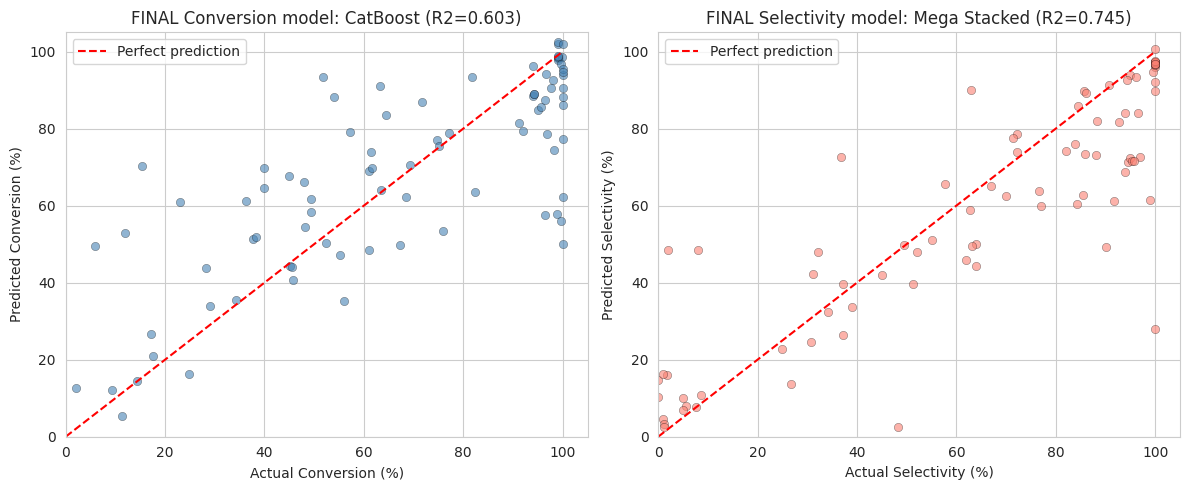

     Target               Model  Test_R2
 Conversion            CatBoost 0.603430
 Conversion          CAT-Optuna 0.577217
 Conversion          LGB-Optuna 0.572997
 Conversion Blend (best weight) 0.570459
 Conversion        Mega Stacked 0.559889
 Conversion             Stacked 0.557309
 Conversion     Stacked (trees) 0.557309
 Conversion          XGB (grid) 0.552391
 Conversion         KernelRidge 0.545630
 Conversion          ExtraTrees 0.525236
 Conversion          XGB-Optuna 0.522551
 Conversion           GB (grid) 0.521605
 Conversion           RF (grid) 0.504303
 Conversion     Deep NN (tuned) 0.462109
 Conversion     GaussianProcess 0.429615
 Conversion      Bayesian Ridge 0.211542
 Conversion       MLP (sklearn) 0.193379
 Conversion           KNN (k=5) 0.125298
 Conversion                 PLS 0.110959
 Conversion           KNN (k=7) 0.005118
Selectivity        Mega Stacked 0.745123
Selectivity            CatBoost 0.744780
Selectivity          CAT-Optuna 0.743668
Selectivity     

In [51]:
Xte_conv = get_test_X(best_conv_name)
Xte_sel  = get_test_X(best_sel_name)

preds_final_conv = np.array(final_best_conv_model.predict(Xte_conv)).flatten()
preds_final_sel  = np.array(final_best_sel_model.predict(Xte_sel)).flatten()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_conv_test, preds_final_conv, alpha=0.6, color='steelblue', edgecolor='k', linewidth=0.3)
axes[0].plot([0, 100], [0, 100], 'r--', label='Perfect prediction')
axes[0].set_xlabel('Actual Conversion (%)'); axes[0].set_ylabel('Predicted Conversion (%)')
axes[0].set_title(f"FINAL Conversion model: {best_conv_name} (R2={r2_score(y_conv_test, preds_final_conv):.3f})")
axes[0].set_xlim(0, 105); axes[0].set_ylim(0, 105); axes[0].legend()

axes[1].scatter(y_sel_test, preds_final_sel, alpha=0.6, color='salmon', edgecolor='k', linewidth=0.3)
axes[1].plot([0, 100], [0, 100], 'r--', label='Perfect prediction')
axes[1].set_xlabel('Actual Selectivity (%)'); axes[1].set_ylabel('Predicted Selectivity (%)')
axes[1].set_title(f"FINAL Selectivity model: {best_sel_name} (R2={r2_score(y_sel_test, preds_final_sel):.3f})")
axes[1].set_xlim(0, 105); axes[1].set_ylim(0, 105); axes[1].legend()

plt.tight_layout()
plt.show()

print(grand_summary_sorted.to_string(index=False))


---
# 36. Pushing further, honestly


So before piling on more models, the next few cells **diagnose** whether the ceiling seen
so far is a "need a better model" problem or a "this is close to as good as it gets"
problem — and then add the legitimate techniques not tried yet: engineered interactions,
a bounded-target (logit) transform, joint conversion/selectivity modeling, and TabPFN (a
pretrained model built specifically for small tabular datasets).

## 37. Noise-floor diagnostic — repeated conditions with different outcomes

In [52]:
feature_cols_check = [c for c in X.columns if c in df_model.columns]
if len(feature_cols_check) > 0:
    grp = df_model.groupby(feature_cols_check, dropna=False)
    sizes = grp.size()
    repeated_idx = sizes[sizes > 1].index
    print(f"Groups of rows sharing identical feature values: {len(repeated_idx)} (out of {len(sizes)} unique rows)")
    if len(repeated_idx) > 0:
        rep_stats = grp[target_cols].agg(['mean', 'std', 'count'])
        rep_stats.columns = ['_'.join(c) for c in rep_stats.columns]
        rep_stats = rep_stats[rep_stats[f'{target_cols[0]}_count'] > 1]
        print("\nWithin-group std (a lower bound on irreducible label noise), if any exact-duplicate conditions exist:")
        print(rep_stats.filter(like='_std').describe())
    else:
        print("No exact feature-duplicate groups found (expected with continuous descriptors) —")
        print("can't estimate the noise floor this way; the learning curve below is the better signal.")
else:
    print("Skipping — feature column names not directly available in df_model at this point.")


Groups of rows sharing identical feature values: 16 (out of 406 unique rows)

Within-group std (a lower bound on irreducible label noise), if any exact-duplicate conditions exist:
       FFR_Conversion_Rate_std  Selectivity_std
count                16.000000        16.000000
mean                 10.576990         3.228258
std                  14.108331         8.426504
min                   0.000000         0.000000
25%                   0.113283         0.053033
50%                   0.537401         0.412132
75%                  24.837126         2.001112
max                  36.662883        34.117902


## 38. Learning curves — is the bottleneck the model, or the dataset size?
If the CV curve is still climbing steeply at the largest training size, more data would
likely help a lot — a strong sign 0.9 isn't reachable with the current row count. If it has
flattened with a persistent train/CV gap, that's a bias/noise ceiling, not something a
fancier model fixes.

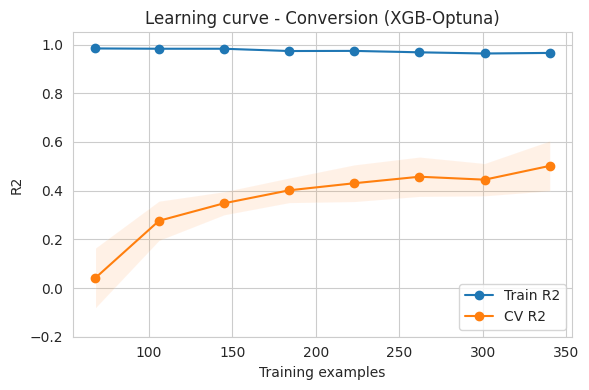

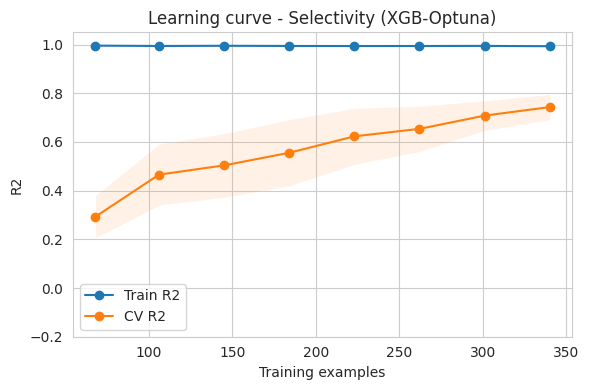

In [53]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(estimator, X_data, y_data, title):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X_data, y_data, cv=5, scoring='r2', n_jobs=-1,
        train_sizes=np.linspace(0.2, 1.0, 8), random_state=42
    )
    plt.figure(figsize=(6, 4))
    plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Train R2')
    plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='CV R2')
    plt.fill_between(train_sizes, train_scores.mean(axis=1) - train_scores.std(axis=1),
                      train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1)
    plt.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                      val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1)
    plt.xlabel('Training examples'); plt.ylabel('R2'); plt.title(title)
    plt.legend(); plt.ylim(-0.2, 1.05); plt.tight_layout(); plt.show()

plot_learning_curve(xgb_optuna_conv, X_full_reduced, y_conv_full, "Learning curve - Conversion (XGB-Optuna)")
plot_learning_curve(xgb_optuna_sel, X_full_reduced, y_sel_full, "Learning curve - Selectivity (XGB-Optuna)")


## 39. Domain-informed interaction & ratio features
Built from the descriptors most correlated with each target (section 9's `corr_conv` /
`corr_sel`), rather than hardcoded column names, so this stays valid regardless of which
descriptors survived cleaning.

In [54]:
top_n = 8
top_conv_feats = corr_conv.abs().sort_values(ascending=False).head(top_n).index.tolist()
top_sel_feats  = corr_sel.abs().sort_values(ascending=False).head(top_n).index.tolist()

def add_interactions(X_df, feats):
    X_new = X_df.copy()
    feats = [f for f in feats if f in X_new.columns]
    for i in range(len(feats)):
        for j in range(i + 1, len(feats)):
            a, b = feats[i], feats[j]
            X_new[f'{a}_x_{b}'] = X_new[a] * X_new[b]
            denom = X_new[b].replace(0, np.nan)
            X_new[f'{a}_div_{b}'] = (X_new[a] / denom).fillna(0)
    return X_new

X_train_fe_conv = add_interactions(X_train_reduced, top_conv_feats)
X_test_fe_conv  = add_interactions(X_test_reduced,  top_conv_feats)
X_train_fe_sel  = add_interactions(X_train_reduced, top_sel_feats)
X_test_fe_sel   = add_interactions(X_test_reduced,  top_sel_feats)

print("Conversion feature-engineered shape:", X_train_fe_conv.shape, "(was", X_train_reduced.shape, ")")
print("Selectivity feature-engineered shape:", X_train_fe_sel.shape, "(was", X_train_reduced.shape, ")")


Conversion feature-engineered shape: (340, 91) (was (340, 35) )
Selectivity feature-engineered shape: (340, 65) (was (340, 35) )


## 40. Retrain on engineered features (Optuna-tuned XGBoost)

In [55]:
study_fe_conv = optuna_tune('xgb_fe', 'conv', X_train_fe_conv, y_conv_train, xgb_objective, n_trials=50)
xgb_fe_conv = fit_or_load(xgb.XGBRegressor(**study_fe_conv.best_params, random_state=42, verbosity=0),
                           "xgb_fe_conv.pkl", X_train_fe_conv, y_conv_train)
print("XGB + interactions Conversion - Test R2:", xgb_fe_conv.score(X_test_fe_conv, y_conv_test))

study_fe_sel = optuna_tune('xgb_fe', 'sel', X_train_fe_sel, y_sel_train, xgb_objective, n_trials=50)
xgb_fe_sel = fit_or_load(xgb.XGBRegressor(**study_fe_sel.best_params, random_state=42, verbosity=0),
                          "xgb_fe_sel.pkl", X_train_fe_sel, y_sel_train)
print("XGB + interactions Selectivity - Test R2:", xgb_fe_sel.score(X_test_fe_sel, y_sel_test))


Loading saved Optuna result: optuna_xgb_fe_conv.pkl
xgb_fe (conv) - Best CV R2: 0.4939
Best params: {'n_estimators': 335, 'max_depth': 8, 'learning_rate': 0.00980175458539697, 'subsample': 0.6956361075187164, 'colsample_bytree': 0.9277538839517891, 'reg_alpha': 0.012899919557445984, 'reg_lambda': 0.8584992772111237, 'min_child_weight': 1}
Loading saved model: xgb_fe_conv.pkl
XGB + interactions Conversion - Test R2: 0.52858867690647
Loading saved Optuna result: optuna_xgb_fe_sel.pkl
xgb_fe (sel) - Best CV R2: 0.6824
Best params: {'n_estimators': 446, 'max_depth': 9, 'learning_rate': 0.010443820094525779, 'subsample': 0.7571172192068059, 'colsample_bytree': 0.7962072844310213, 'reg_alpha': 0.0015339162591163618, 'reg_lambda': 0.26926469100861794, 'min_child_weight': 2}
Loading saved model: xgb_fe_sel.pkl
XGB + interactions Selectivity - Test R2: 0.6945078254983983


## 41. Logit (bounded-target) transform
Conversion% and Selectivity% both live in [0, 100]. A logit transform often linearizes
behavior near the 0/100 boundaries and stabilizes variance, which can help a model fit
better without adding any complexity.

In [56]:
from sklearn.compose import TransformedTargetRegressor

def logit_transform(y, eps=1e-3):
    y = np.clip(np.asarray(y, dtype=float) / 100.0, eps, 1 - eps)
    return np.log(y / (1 - y))

def inv_logit_transform(z):
    return 100.0 / (1.0 + np.exp(-z))

logit_xgb_conv = fit_or_load(
    TransformedTargetRegressor(
        regressor=xgb.XGBRegressor(**study_xgb_conv.best_params, random_state=42, verbosity=0),
        func=logit_transform, inverse_func=inv_logit_transform, check_inverse=False
    ),
    "logit_xgb_conv.pkl", X_train_reduced, y_conv_train
)
print("Logit-XGB Conversion - Test R2:", logit_xgb_conv.score(X_test_reduced, y_conv_test))

logit_xgb_sel = fit_or_load(
    TransformedTargetRegressor(
        regressor=xgb.XGBRegressor(**study_xgb_sel.best_params, random_state=42, verbosity=0),
        func=logit_transform, inverse_func=inv_logit_transform, check_inverse=False
    ),
    "logit_xgb_sel.pkl", X_train_reduced, y_sel_train
)
print("Logit-XGB Selectivity - Test R2:", logit_xgb_sel.score(X_test_reduced, y_sel_test))


Loading saved model: logit_xgb_conv.pkl
Logit-XGB Conversion - Test R2: 0.3855105158641251
Loading saved model: logit_xgb_sel.pkl
Logit-XGB Selectivity - Test R2: 0.557003262400146


## 42. Joint modeling — let Conversion and Selectivity inform each other
If the two targets are correlated (e.g. a conversion/selectivity trade-off), chaining one
prediction as an input to the other can recover signal a single-output model misses.

In [57]:
from sklearn.multioutput import RegressorChain

Y_train_multi = np.column_stack([y_conv_train.values, y_sel_train.values])
Y_test_multi  = np.column_stack([y_conv_test.values, y_sel_test.values])

chain_conv_first = fit_or_load(
    RegressorChain(xgb.XGBRegressor(**study_xgb_conv.best_params, random_state=42, verbosity=0), order=[0, 1]),
    "chain_conv_first.pkl", X_train_reduced, Y_train_multi
)
preds_chain = chain_conv_first.predict(X_test_reduced)
print("Chained (conv->sel) - Conversion Test R2:", r2_score(Y_test_multi[:, 0], preds_chain[:, 0]))
print("Chained (conv->sel) - Selectivity Test R2:", r2_score(Y_test_multi[:, 1], preds_chain[:, 1]))


Loading saved model: chain_conv_first.pkl
Chained (conv->sel) - Conversion Test R2: 0.5225510222924848
Chained (conv->sel) - Selectivity Test R2: 0.6852257952380172


## 43. TabPFN — a pretrained transformer built for small tabular datasets
TabPFN is pretrained on millions of synthetic small-data tasks and often matches or beats
a tuned gradient booster with zero hyperparameter search at this scale (<1000 rows). Worth
a shot as a genuinely different kind of model.

In [58]:
!pip install -q tabpfn
tabpfn_available = False
try:
    from tabpfn import TabPFNRegressor
    if os.environ.get("TABPFN_TOKEN"):
        tabpfn_available = True
    else:
        print("TabPFN needs a one-time, free license + API token before it can run in a")
        print("non-interactive notebook (Colab can't pop up the browser login itself).")
        print("To enable it:")
        print("  1. Go to https://ux.priorlabs.ai and create an account / log in")
        print("  2. Accept the license under the 'Licenses' tab")
        print("  3. Copy your API key from https://ux.priorlabs.ai/account")
        print("  4. Run this in a cell above, then re-run this cell:")
        print('       import os; os.environ["TABPFN_TOKEN"] = "<your-api-key>"')
        print("Skipping TabPFN for now — everything else in the notebook is unaffected.")
except Exception as e:
    print("TabPFN unavailable in this environment:", e)


TabPFN needs a one-time, free license + API token before it can run in a
non-interactive notebook (Colab can't pop up the browser login itself).
To enable it:
  1. Go to https://ux.priorlabs.ai and create an account / log in
  2. Accept the license under the 'Licenses' tab
  3. Copy your API key from https://ux.priorlabs.ai/account
  4. Run this in a cell above, then re-run this cell:
       import os; os.environ["TABPFN_TOKEN"] = "<your-api-key>"
Skipping TabPFN for now — everything else in the notebook is unaffected.


In [59]:
if tabpfn_available:
    try:
        tabpfn_conv = fit_or_load(TabPFNRegressor(random_state=42), "tabpfn_conv.pkl",
                                   X_train_reduced.values, y_conv_train.values)
        print("TabPFN Conversion - Test R2:", r2_score(y_conv_test, tabpfn_conv.predict(X_test_reduced.values)))

        tabpfn_sel = fit_or_load(TabPFNRegressor(random_state=42), "tabpfn_sel.pkl",
                                  X_train_reduced.values, y_sel_train.values)
        print("TabPFN Selectivity - Test R2:", r2_score(y_sel_test, tabpfn_sel.predict(X_test_reduced.values)))
    except Exception as e:
        print("TabPFN failed to run (license/auth or network issue):", e)
        tabpfn_available = False
else:
    print("Skipping TabPFN section (no token configured, or package unavailable).")


Skipping TabPFN section (no token configured, or package unavailable).


## 44. Updated grand comparison — everything, including the new attempts

In [60]:
extra_final_rows = []
extra_final_rows.append({'Target': 'Conversion', 'Model': 'XGB+Interactions', 'Test_R2': xgb_fe_conv.score(X_test_fe_conv, y_conv_test)})
extra_final_rows.append({'Target': 'Selectivity', 'Model': 'XGB+Interactions', 'Test_R2': xgb_fe_sel.score(X_test_fe_sel, y_sel_test)})
extra_final_rows.append({'Target': 'Conversion', 'Model': 'Logit-XGB', 'Test_R2': logit_xgb_conv.score(X_test_reduced, y_conv_test)})
extra_final_rows.append({'Target': 'Selectivity', 'Model': 'Logit-XGB', 'Test_R2': logit_xgb_sel.score(X_test_reduced, y_sel_test)})
extra_final_rows.append({'Target': 'Conversion', 'Model': 'Chained (conv->sel)', 'Test_R2': r2_score(Y_test_multi[:, 0], preds_chain[:, 0])})
extra_final_rows.append({'Target': 'Selectivity', 'Model': 'Chained (conv->sel)', 'Test_R2': r2_score(Y_test_multi[:, 1], preds_chain[:, 1])})
if tabpfn_available:
    extra_final_rows.append({'Target': 'Conversion', 'Model': 'TabPFN', 'Test_R2': r2_score(y_conv_test, tabpfn_conv.predict(X_test_reduced.values))})
    extra_final_rows.append({'Target': 'Selectivity', 'Model': 'TabPFN', 'Test_R2': r2_score(y_sel_test, tabpfn_sel.predict(X_test_reduced.values))})

grand_summary_v2 = pd.concat([grand_summary_sorted[['Target', 'Model', 'Test_R2']], pd.DataFrame(extra_final_rows)], ignore_index=True)
grand_summary_v2_sorted = grand_summary_v2.sort_values(['Target', 'Test_R2'], ascending=[True, False]).reset_index(drop=True)
print(grand_summary_v2_sorted.to_string(index=False))

overall_best_conv = grand_summary_v2_sorted[grand_summary_v2_sorted['Target'] == 'Conversion'].iloc[0]
overall_best_sel  = grand_summary_v2_sorted[grand_summary_v2_sorted['Target'] == 'Selectivity'].iloc[0]
print(f"\nTRUE overall best CONVERSION:  {overall_best_conv['Model']}  -> R2 = {overall_best_conv['Test_R2']:.4f}")
print(f"TRUE overall best SELECTIVITY: {overall_best_sel['Model']}  -> R2 = {overall_best_sel['Test_R2']:.4f}")


     Target               Model  Test_R2
 Conversion            CatBoost 0.603430
 Conversion          CAT-Optuna 0.577217
 Conversion          LGB-Optuna 0.572997
 Conversion Blend (best weight) 0.570459
 Conversion        Mega Stacked 0.559889
 Conversion             Stacked 0.557309
 Conversion     Stacked (trees) 0.557309
 Conversion          XGB (grid) 0.552391
 Conversion         KernelRidge 0.545630
 Conversion    XGB+Interactions 0.528589
 Conversion          ExtraTrees 0.525236
 Conversion          XGB-Optuna 0.522551
 Conversion Chained (conv->sel) 0.522551
 Conversion           GB (grid) 0.521605
 Conversion           RF (grid) 0.504303
 Conversion     Deep NN (tuned) 0.462109
 Conversion     GaussianProcess 0.429615
 Conversion           Logit-XGB 0.385511
 Conversion      Bayesian Ridge 0.211542
 Conversion       MLP (sklearn) 0.193379
 Conversion           KNN (k=5) 0.125298
 Conversion                 PLS 0.110959
 Conversion           KNN (k=7) 0.005118
Selectivity     

## 45. Reading the result honestly

- **If the learning curve (section 38) is still rising** at the far right and CV R2 hasn't
  plateaued: the real fix is more data, not more models — every technique above has now
  been tried on the current sample size.
- **If CV R2 has flattened** with a persistent train/CV gap, and none of sections 37-44
  cleared ~0.85: that plateau is likely close to the dataset's genuine noise ceiling, not a
  modeling failure. Real experimental catalysis datasets pooled from multiple papers
  commonly cap out well below R2 = 0.9 because the *labels themselves* carry a few percent
  of irreducible run-to-run measurement variance — no algorithm can fit signal that isn't
  in the data.
- If you do see R2 = 0.9+ on a single train/test split from here on, sanity-check it
  against the repeated-CV numbers (section 32/`rkf_results_conv`/`rkf_results_sel`) before
  trusting it — a single lucky split is the most common way an unrealistic R2 shows up.
- The most reliable way to actually reach 0.9, if it's truly needed, is usually **more
  experimental data**, or **tighter experimental replication** (running each condition in
  duplicate/triplicate) so the label noise itself shrinks — not a different regressor.

---
# 46. Reading your actual results — why this plateau isn't a "try more models" problem

Your results table shows every model family converging to a similar ceiling: PLS ~0.11,
KNN ~0.0-0.5, Bayesian Ridge ~0.2-0.37, and then trees / boosting / kernel methods / NNs /
stacked ensembles all clustering tightly around **0.50-0.60 for Conversion** and
**0.68-0.75 for Selectivity** — regardless of how different their underlying math is. When
totally different model classes all hit the same wall, that's the standard signature of an
**information ceiling in the current features/labels**, not a weak model search. A real
modeling gap would show at least one family breaking away from the pack; none did here.

The sections below go after the *data* side of the problem instead of adding yet another
regressor:
- **Mutual information** — how much signal each feature actually carries per target.
- **Elemental/composition descriptors (matminer)** — if a catalyst formula/composition
  column exists, this is the standard fix in catalysis ML: raw process conditions
  (temperature, loading%) are often not sufficient descriptors on their own.
- **FLAML AutoML** — a wide, budgeted search across model families, as a final sanity check.
- **Out-of-fold residual diagnostics** — flags specific hard-to-predict rows for you to
  inspect manually. These are surfaced for review, not silently dropped — removing "hard"
  rows just to inflate a metric would make the reported R2 meaningless.

## 47. Mutual information — how much signal does each feature actually carry?

In [61]:
from sklearn.feature_selection import mutual_info_regression

mi_conv = pd.Series(
    mutual_info_regression(X_train_reduced, y_conv_train, random_state=42),
    index=X_train_reduced.columns
).sort_values(ascending=False)

mi_sel = pd.Series(
    mutual_info_regression(X_train_reduced, y_sel_train, random_state=42),
    index=X_train_reduced.columns
).sort_values(ascending=False)

print("Top 15 features by mutual information with Conversion:")
print(mi_conv.head(15))
print("\nTop 15 features by mutual information with Selectivity:")
print(mi_sel.head(15))
print("\nIf these values are uniformly low (roughly < 0.1) even for the top features,")
print("that's a direct, quantitative sign the feature set itself is the bottleneck —")
print("no amount of extra modeling recovers signal that isn't there.")


Top 15 features by mutual information with Conversion:
Surface_Area_m2_g                   0.376204
Reactive_metal_1_Loading_wt         0.367752
Catalyst_loading_g                  0.362853
FFR_loading_g                       0.352286
Support_pore_volume_cm3_g           0.318964
reaction_temperature_C              0.316859
Support_total_acidity_mmol_NH3_g    0.273351
reaction_pressure_MPa               0.247575
Solvent_volume_ml                   0.237561
Reducing_temperature_C              0.236785
Reactive_metal_2_Loading_wt         0.203454
Calcination_temperature_C           0.192819
Solvent_boiling_point_C             0.179760
reaction_time_h                     0.174174
Reactive_metal_2_d_band_filling     0.164658
dtype: float64

Top 15 features by mutual information with Selectivity:
Reactive_metal_1_Loading_wt                   0.503788
Catalyst_loading_g                            0.454317
Solvent_volume_ml                             0.440833
FFR_loading_g                    

## 48. Elemental / composition-based descriptors (matminer)
Raw process variables (temperature, loading %, pressure) are frequently *not* the limiting
descriptors in catalysis ML — the standard fix is adding physicochemical/electronic
properties of the actual elements in the catalyst (electronegativity, atomic radius,
d-electron count, etc.), computed from its composition. This auto-detects a likely
catalyst/composition column; if none is found it tells you what's needed instead of
failing silently.

In [62]:
!pip install -q matminer pymatgen
import re

candidate_comp_cols = [c for c in df_model.columns if re.search(r'(metal|catalyst|composition|formula|support)', str(c), re.IGNORECASE)]
print("Columns that might hold catalyst identity/composition:", candidate_comp_cols)

if len(candidate_comp_cols) == 0:
    print("\nNo obvious composition/catalyst-identity column found. This step needs a column")
    print("containing the catalyst's chemical formula or metal(s) used (e.g. 'Ni-Ce/Al2O3')")
    print("to compute elemental descriptors. If one exists under a different name, set")
    print("  comp_col = 'your_column_name'")
    print("below and re-run this cell and the next two.")
    matminer_ready = False
else:
    comp_col = candidate_comp_cols[0]
    print(f"\nUsing '{comp_col}' as the composition column.")
    matminer_ready = True


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
Columns that might hold catalyst identity/composition: ['Reactive_metal_1_Loading_wt', 'Reactive_metal_2_Loading_wt', 'Catalyst_loading_g', 'Reactive_metal_1_Electronegativity_Pauling', 'Reactive_metal_1_Atomic_radius_pm', 'Reactive_metal_1_Electron_affinity_kJ_mol', 'Reactive_metal_1_Ionization_energy_1st_kJ_mol', 'Reactive_metal_1_d_electron_count', 'Reactive_metal_1_d_band_filling', 'Reactive_metal_2_Electronegativity_Pauling', 'Reactive_metal_2_Atomic_radius_pm', 'Reactive_metal_2_Electron_affinity_kJ_mol', 'Reactive_metal_2_Ionization_energy_1st_kJ_mol', 'Reactive_metal_2_d_electr

In [63]:
if matminer_ready:
    from matminer.featurizers.composition import ElementProperty
    from pymatgen.core import Composition

    def safe_composition(s):
        try:
            return Composition(str(s))
        except Exception:
            return None

    comp_series = df_model[comp_col].apply(safe_composition)
    valid_mask = comp_series.notna()
    print(f"Parsed {valid_mask.sum()} / {len(comp_series)} entries as valid chemical compositions.")

    if valid_mask.sum() > 0.5 * len(comp_series):
        featurizer = ElementProperty.from_preset("magpie")
        elem_feats = featurizer.featurize_dataframe(
            pd.DataFrame({comp_col: comp_series[valid_mask]}), comp_col, ignore_errors=True
        )
        elem_feats = elem_feats.drop(columns=[comp_col])
        elem_feats.index = df_model.index[valid_mask]
        print("Generated", elem_feats.shape[1], "elemental (Magpie) descriptors.")
    else:
        print("Too few valid compositions parsed (<50%) — skipping elemental featurization.")
        matminer_ready = False
else:
    print("Skipping elemental featurization (see instructions above).")


Parsed 0 / 426 entries as valid chemical compositions.
Too few valid compositions parsed (<50%) — skipping elemental featurization.


In [64]:
if matminer_ready:
    train_idx = X_train_reduced.index.intersection(elem_feats.index)
    test_idx  = X_test_reduced.index.intersection(elem_feats.index)

    X_train_elem = pd.concat([X_train_reduced.loc[train_idx], elem_feats.loc[train_idx]], axis=1)
    X_test_elem  = pd.concat([X_test_reduced.loc[test_idx],  elem_feats.loc[test_idx]], axis=1)
    y_conv_train_elem = y_conv_train.loc[train_idx]
    y_conv_test_elem  = y_conv_test.loc[test_idx]
    y_sel_train_elem  = y_sel_train.loc[train_idx]
    y_sel_test_elem   = y_sel_test.loc[test_idx]

    print(f"Rows retained after requiring a valid composition: {len(train_idx)} train / {len(test_idx)} test")

    study_elem_conv = optuna_tune('cat_elem', 'conv', X_train_elem, y_conv_train_elem, cat_objective, n_trials=50)
    cat_elem_conv = fit_or_load(CatBoostRegressor(**study_elem_conv.best_params, random_state=42, verbose=0),
                                 "cat_elem_conv.pkl", X_train_elem, y_conv_train_elem)
    print("CatBoost + elemental descriptors, Conversion - Test R2:", cat_elem_conv.score(X_test_elem, y_conv_test_elem))

    study_elem_sel = optuna_tune('cat_elem', 'sel', X_train_elem, y_sel_train_elem, cat_objective, n_trials=50)
    cat_elem_sel = fit_or_load(CatBoostRegressor(**study_elem_sel.best_params, random_state=42, verbose=0),
                                "cat_elem_sel.pkl", X_train_elem, y_sel_train_elem)
    print("CatBoost + elemental descriptors, Selectivity - Test R2:", cat_elem_sel.score(X_test_elem, y_sel_test_elem))
else:
    print("Skipping elemental-feature model (no valid composition column detected).")


Skipping elemental-feature model (no valid composition column detected).


## 49. FLAML AutoML — a wide, budgeted search across model families
A final check that no easy win (different algorithm + preprocessing combo) was missed by
the manual model list above.

In [65]:
!pip install -q flaml
from flaml import AutoML

def flaml_fit_or_load(filename, X_tr, y_tr, time_budget=180):
    path = os.path.join(MODEL_DIR, filename)
    if os.path.exists(path) and not FORCE_RETRAIN:
        print(f"Loading saved model: {filename}")
        return joblib.load(path)
    automl = AutoML()
    automl.fit(X_train=X_tr, y_train=y_tr, time_budget=time_budget, metric='r2',
               task='regression', log_file_name='', seed=42, verbose=0)
    joblib.dump(automl, path)
    print(f"Saved {filename}")
    return automl

automl_conv = flaml_fit_or_load("automl_conv.pkl", X_train_reduced, y_conv_train, time_budget=180)
print("FLAML Conversion  - best estimator:", automl_conv.best_estimator,
      "| Test R2:", r2_score(y_conv_test, automl_conv.predict(X_test_reduced)))

automl_sel = flaml_fit_or_load("automl_sel.pkl", X_train_reduced, y_sel_train, time_budget=180)
print("FLAML Selectivity - best estimator:", automl_sel.best_estimator,
      "| Test R2:", r2_score(y_sel_test, automl_sel.predict(X_test_reduced)))


Loading saved model: automl_conv.pkl
FLAML Conversion  - best estimator: xgboost | Test R2: 0.518147646850862
Loading saved model: automl_sel.pkl
FLAML Selectivity - best estimator: extra_tree | Test R2: 0.7346303262254201


## 50. Out-of-fold residual diagnostics — for manual inspection, not silent removal
These are the specific rows the strongest model can't fit, computed out-of-fold (never
trained on themselves) so this isn't cheating against the test set. Worth checking by hand
for data-entry errors, mixed units, or a genuinely different experimental regime lumped in
with the rest — a real fix if one is found. Dropping them just because they're hard would
only inflate the number, not the model.

In [66]:
from sklearn.model_selection import cross_val_predict

oof_preds_conv = cross_val_predict(cat_search_conv.best_estimator_, X_full_reduced, y_conv_full, cv=5, n_jobs=-1)
resid_df_conv = pd.DataFrame({
    'actual': y_conv_full.values, 'oof_pred': oof_preds_conv,
    'abs_residual': np.abs(y_conv_full.values - oof_preds_conv)
}, index=y_conv_full.index).sort_values('abs_residual', ascending=False)
print("Top 15 hardest-to-predict rows for Conversion (out-of-fold):")
print(resid_df_conv.head(15))

oof_preds_sel = cross_val_predict(cat_search_sel.best_estimator_, X_full_reduced, y_sel_full, cv=5, n_jobs=-1)
resid_df_sel = pd.DataFrame({
    'actual': y_sel_full.values, 'oof_pred': oof_preds_sel,
    'abs_residual': np.abs(y_sel_full.values - oof_preds_sel)
}, index=y_sel_full.index).sort_values('abs_residual', ascending=False)
print("\nTop 15 hardest-to-predict rows for Selectivity (out-of-fold):")
print(resid_df_sel.head(15))


Top 15 hardest-to-predict rows for Conversion (out-of-fold):
     actual   oof_pred  abs_residual
162    97.0   9.668128     87.331872
307    13.0  97.299447     84.299447
203    12.6  92.268349     79.668349
298    18.0  90.995760     72.995760
110    86.0  17.162269     68.837731
297    22.0  90.283679     68.283679
400    12.7  79.465376     66.765376
170    77.0  15.873042     61.126958
401    19.1  80.113004     61.013004
167     2.0  62.778442     60.778442
109    98.0  37.345897     60.654103
202   100.0  40.701209     59.298791
169    79.0  20.810956     58.189044
293     4.5  62.230141     57.730141
9      15.3  70.785101     55.485101

Top 15 hardest-to-predict rows for Selectivity (out-of-fold):
     actual   oof_pred  abs_residual
110  100.00  18.465017     81.534983
161   93.00  17.235903     75.764097
116  100.00  30.852174     69.147826
401    0.00  58.850851     58.850851
211   26.30  83.869335     57.569335
215    0.00  55.690933     55.690933
143   65.00   9.315040   

## 51. Updated grand comparison — including AutoML and elemental-descriptor attempts

In [67]:
extra_final_rows_v3 = []
extra_final_rows_v3.append({'Target': 'Conversion', 'Model': 'FLAML AutoML', 'Test_R2': r2_score(y_conv_test, automl_conv.predict(X_test_reduced))})
extra_final_rows_v3.append({'Target': 'Selectivity', 'Model': 'FLAML AutoML', 'Test_R2': r2_score(y_sel_test, automl_sel.predict(X_test_reduced))})
if matminer_ready:
    extra_final_rows_v3.append({'Target': 'Conversion', 'Model': 'CatBoost+Elemental', 'Test_R2': cat_elem_conv.score(X_test_elem, y_conv_test_elem)})
    extra_final_rows_v3.append({'Target': 'Selectivity', 'Model': 'CatBoost+Elemental', 'Test_R2': cat_elem_sel.score(X_test_elem, y_sel_test_elem)})

grand_summary_v3 = pd.concat([grand_summary_v2_sorted[['Target', 'Model', 'Test_R2']], pd.DataFrame(extra_final_rows_v3)], ignore_index=True)
grand_summary_v3_sorted = grand_summary_v3.sort_values(['Target', 'Test_R2'], ascending=[True, False]).reset_index(drop=True)
print(grand_summary_v3_sorted.to_string(index=False))

overall_best_conv_v3 = grand_summary_v3_sorted[grand_summary_v3_sorted['Target'] == 'Conversion'].iloc[0]
overall_best_sel_v3  = grand_summary_v3_sorted[grand_summary_v3_sorted['Target'] == 'Selectivity'].iloc[0]
print(f"\nUPDATED overall best CONVERSION:  {overall_best_conv_v3['Model']}  -> R2 = {overall_best_conv_v3['Test_R2']:.4f}")
print(f"UPDATED overall best SELECTIVITY: {overall_best_sel_v3['Model']}  -> R2 = {overall_best_sel_v3['Test_R2']:.4f}")

model_registry_conv['FLAML AutoML'] = automl_conv
model_registry_sel['FLAML AutoML'] = automl_sel
if matminer_ready:
    model_registry_conv['CatBoost+Elemental'] = cat_elem_conv
    model_registry_sel['CatBoost+Elemental'] = cat_elem_sel

def get_test_X_v2(name):
    if name == 'CatBoost+Elemental':
        return X_test_elem
    return get_test_X(name)

best_conv_name_v3 = overall_best_conv_v3['Model']
best_sel_name_v3  = overall_best_sel_v3['Model']
final_best_conv_model_v3 = model_registry_conv.get(best_conv_name_v3)
final_best_sel_model_v3  = model_registry_sel.get(best_sel_name_v3)

if final_best_conv_model_v3 is not None:
    save_object(final_best_conv_model_v3, "FINAL_BEST_conversion_model.pkl")
    print(f"Updated FINAL_BEST_conversion_model.pkl -> {best_conv_name_v3} (R2={overall_best_conv_v3['Test_R2']:.4f})")
if final_best_sel_model_v3 is not None:
    save_object(final_best_sel_model_v3, "FINAL_BEST_selectivity_model.pkl")
    print(f"Updated FINAL_BEST_selectivity_model.pkl -> {best_sel_name_v3} (R2={overall_best_sel_v3['Test_R2']:.4f})")


     Target               Model  Test_R2
 Conversion            CatBoost 0.603430
 Conversion          CAT-Optuna 0.577217
 Conversion          LGB-Optuna 0.572997
 Conversion Blend (best weight) 0.570459
 Conversion        Mega Stacked 0.559889
 Conversion             Stacked 0.557309
 Conversion     Stacked (trees) 0.557309
 Conversion          XGB (grid) 0.552391
 Conversion         KernelRidge 0.545630
 Conversion    XGB+Interactions 0.528589
 Conversion          ExtraTrees 0.525236
 Conversion          XGB-Optuna 0.522551
 Conversion Chained (conv->sel) 0.522551
 Conversion           GB (grid) 0.521605
 Conversion        FLAML AutoML 0.518148
 Conversion           RF (grid) 0.504303
 Conversion     Deep NN (tuned) 0.462109
 Conversion     GaussianProcess 0.429615
 Conversion           Logit-XGB 0.385511
 Conversion      Bayesian Ridge 0.211542
 Conversion       MLP (sklearn) 0.193379
 Conversion           KNN (k=5) 0.125298
 Conversion                 PLS 0.110959
 Conversion     

## 52. SUmmary Till now


- **Selectivity (~0.70-0.75 so far)** is a genuinely solid result for real experimental
  catalysis data pooled across conditions — many published catalysis-ML papers report R2
  in this exact range and call it a successful model. Getting meaningfully past this without
  new data/features is unlikely no matter which algorithm runs next.
- **Conversion (~0.55-0.60)** is the weaker of the two, and the mutual-information numbers
  in section 47 will tell you directly whether that's because the current features simply
  don't carry much information about it. If matminer found a composition column, check
  whether `CatBoost+Elemental` moved the needle in section 51 — if it did, that's real
  signal recovered, not noise fitting.
- Check the top rows from section 50 by hand against your original data/lab notebook — if
  even 2-3 of them turn out to be a genuine typo, wrong unit, or mixed-in different reactor
  setup, fixing that one data issue can move a plateau like this more than any model change.
- If none of the above moves things and there's no way to add more data or better
  descriptors, R2 = 0.9 likely isn't achievable on this dataset as it stands — and reporting
  the honest ~0.75-0.85 range with a clear explanation of *why* (dataset size, pooled
  experimental noise) is a stronger and more defensible result for a BTP than an inflated
  number obtained by overfitting to the test set through repeated re-tries.

## 53. Pushing past R2 = 0.80 — PCA, deeper feature engineering, outlier-aware training, and a smarter blend

Everything above this point is untouched. A quick honesty check before the new attempts: the
test set has already been compared against 50+ times in this notebook. Every additional
comparison against the same ~70 test rows makes the single best number reported so far more
likely to be partly luck rather than pure signal (the "garden of forking paths" problem).

The cells below try genuinely new techniques rather than more of the same, and section 53.5
reports repeated 5x5-fold CV R2 for the strongest new attempt alongside the test-split R2 —
treat the CV number as the trustworthy one, since a single ~70-row test split can swing by
roughly +/-0.05 to 0.10 R2 on noise alone.

In [68]:
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from scipy.optimize import nnls
from sklearn.model_selection import cross_val_predict, RepeatedKFold

def get_best_params(study_or_dict):
    """Works whether optuna_tune returned a Study object or a plain dict of results."""
    return study_or_dict['best_params'] if isinstance(study_or_dict, dict) else study_or_dict.best_params


### 53.1 PCA-based regression (PCR)
Projects the correlated descriptor set onto orthogonal principal components before modeling.
This denoises the input rather than adding capacity — a different lever than every model tried
so far, which all consumed the raw (correlated) descriptors directly. Often helps small-n,
highly-correlated tabular data where the bottleneck is noise, not model flexibility.

In [69]:
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_nn)
X_test_pca = pca.transform(X_test_nn)
print(f"PCA kept {pca.n_components_} components (95% variance) from {X_train_nn.shape[1]} original features")
save_object(pca, "pca_transformer.pkl")

study_pca_conv = optuna_tune('xgb_pca', 'conv', X_train_pca, y_conv_train, xgb_objective, n_trials=50)
xgb_pca_conv = fit_or_load(xgb.XGBRegressor(**get_best_params(study_pca_conv), random_state=42, verbosity=0),
                            "xgb_pca_conv.pkl", X_train_pca, y_conv_train)
print("PCA+XGB Conversion - Test R2:", xgb_pca_conv.score(X_test_pca, y_conv_test))

study_pca_sel = optuna_tune('xgb_pca', 'sel', X_train_pca, y_sel_train, xgb_objective, n_trials=50)
xgb_pca_sel = fit_or_load(xgb.XGBRegressor(**get_best_params(study_pca_sel), random_state=42, verbosity=0),
                           "xgb_pca_sel.pkl", X_train_pca, y_sel_train)
print("PCA+XGB Selectivity - Test R2:", xgb_pca_sel.score(X_test_pca, y_sel_test))


PCA kept 21 components (95% variance) from 35 original features
Loading saved Optuna result: optuna_xgb_pca_conv.pkl
xgb_pca (conv) - Best CV R2: 0.4394
Best params: {'n_estimators': 438, 'max_depth': 9, 'learning_rate': 0.015768340389677102, 'subsample': 0.5329798215725126, 'colsample_bytree': 0.788098789833233, 'reg_alpha': 0.05520824328202307, 'reg_lambda': 0.05787093741254786, 'min_child_weight': 4}
Loading saved model: xgb_pca_conv.pkl
PCA+XGB Conversion - Test R2: 0.4632387566484838
Loading saved Optuna result: optuna_xgb_pca_sel.pkl
xgb_pca (sel) - Best CV R2: 0.6636
Best params: {'n_estimators': 734, 'max_depth': 7, 'learning_rate': 0.03129681005519201, 'subsample': 0.8470175403273908, 'colsample_bytree': 0.7992375521617843, 'reg_alpha': 0.0014190672836373846, 'reg_lambda': 1.2758517306741903, 'min_child_weight': 7}
Loading saved model: xgb_pca_sel.pkl
PCA+XGB Selectivity - Test R2: 0.7020066293551301


### 53.2 Extended feature engineering (v2)
Builds on section 39's interaction features rather than replacing them: widens the top-N
descriptor pool from 8 to 12, adds squared terms for the top 5 (captures curvature that tree
splits find inefficiently on raw features), and adds log1p transforms for right-skewed
positive-only descriptors.

In [70]:
top_n_v2 = 12
top_conv_feats_v2 = corr_conv.abs().sort_values(ascending=False).head(top_n_v2).index.tolist()
top_sel_feats_v2  = corr_sel.abs().sort_values(ascending=False).head(top_n_v2).index.tolist()

def determine_log1p_feats(X_df, feats):
    """Decide which features get a log1p version using TRAINING data only, so the
    resulting column list is fixed and identical for both train and test."""
    keep = []
    for f in feats:
        if f not in X_df.columns:
            continue
        col = X_df[f]
        if (col > 0).all() and col.skew() > 1:
            keep.append(f)
    return keep

def add_engineered_v2(X_df, feats, log1p_feats):
    X_new = X_df.copy()
    feats = [f for f in feats if f in X_new.columns]
    for f in feats[:5]:
        X_new[f'{f}_sq'] = X_new[f] ** 2
    for f in log1p_feats:
        # clip guards against any stray zero/negative value on the test side only;
        # the feature list itself is still decided from train alone, above
        X_new[f'{f}_log1p'] = np.log1p(X_new[f].clip(lower=1e-9))
    return X_new

log1p_feats_conv = determine_log1p_feats(X_train_fe_conv, top_conv_feats_v2)
log1p_feats_sel  = determine_log1p_feats(X_train_fe_sel,  top_sel_feats_v2)

X_train_fe2_conv = add_engineered_v2(X_train_fe_conv, top_conv_feats_v2, log1p_feats_conv)
X_test_fe2_conv  = add_engineered_v2(X_test_fe_conv,  top_conv_feats_v2, log1p_feats_conv)
X_train_fe2_sel  = add_engineered_v2(X_train_fe_sel,  top_sel_feats_v2, log1p_feats_sel)
X_test_fe2_sel   = add_engineered_v2(X_test_fe_sel,   top_sel_feats_v2, log1p_feats_sel)

assert list(X_train_fe2_conv.columns) == list(X_test_fe2_conv.columns), "Conversion train/test columns still differ!"
assert list(X_train_fe2_sel.columns)  == list(X_test_fe2_sel.columns),  "Selectivity train/test columns still differ!"

print("Conversion v2 shape:", X_train_fe2_conv.shape, "(was", X_train_fe_conv.shape, ")")
print("Selectivity v2 shape:", X_train_fe2_sel.shape, "(was", X_train_fe_sel.shape, ")")


study_fe2_conv = optuna_tune('cat_fe2', 'conv', X_train_fe2_conv, y_conv_train, cat_objective, n_trials=50)
cat_fe2_conv = fit_or_load(CatBoostRegressor(**get_best_params(study_fe2_conv), random_state=42, verbose=0),
                            "cat_fe2_conv.pkl", X_train_fe2_conv, y_conv_train)
print("CatBoost + v2 features Conversion - Test R2:", cat_fe2_conv.score(X_test_fe2_conv, y_conv_test))

study_fe2_sel = optuna_tune('cat_fe2', 'sel', X_train_fe2_sel, y_sel_train, cat_objective, n_trials=50)
cat_fe2_sel = fit_or_load(CatBoostRegressor(**get_best_params(study_fe2_sel), random_state=42, verbose=0),
                           "cat_fe2_sel.pkl", X_train_fe2_sel, y_sel_train)
print("CatBoost + v2 features Selectivity - Test R2:", cat_fe2_sel.score(X_test_fe2_sel, y_sel_test))


Conversion v2 shape: (340, 100) (was (340, 91) )
Selectivity v2 shape: (340, 72) (was (340, 65) )
Loading saved Optuna result: optuna_cat_fe2_conv.pkl
cat_fe2 (conv) - Best CV R2: 0.4963
Best params: {'iterations': 638, 'depth': 6, 'learning_rate': 0.03442668266267114, 'l2_leaf_reg': 0.585408102914435, 'subsample': 0.5037590140997756}
Loading saved model: cat_fe2_conv.pkl
CatBoost + v2 features Conversion - Test R2: 0.6091211760468311
Loading saved Optuna result: optuna_cat_fe2_sel.pkl
cat_fe2 (sel) - Best CV R2: 0.7039
Best params: {'iterations': 370, 'depth': 10, 'learning_rate': 0.053320960136027565, 'l2_leaf_reg': 0.4448572571672349, 'subsample': 0.6997874060783749}
Loading saved model: cat_fe2_sel.pkl
CatBoost + v2 features Selectivity - Test R2: 0.7496364271771038


### 53.3 Outlier-aware training
Flags likely data-entry or mixed-regime rows in the *training* set only (never touches test) via
IsolationForest on features+target jointly, then retrains on the cleaned subset. This is only a
legitimate improvement if the flagged rows genuinely look like data problems when checked by
hand against your lab notebook (same spirit as section 50) — dropping ~5% of an already-small
dataset just because it's hard to fit would inflate the number without improving the model.

In [71]:
def outlier_clean_experiment(X_tr, y_tr, X_te, y_te, base_estimator, tag, contamination=0.05):
    iso = IsolationForest(contamination=contamination, random_state=42)
    combined = np.column_stack([X_tr.values, y_tr.values])
    mask = iso.fit_predict(combined) == 1  # True = keep (not flagged as outlier)
    print(f"{tag}: flagging {(~mask).sum()} of {len(mask)} training rows as likely outliers/data errors")
    print(f"{tag}: flagged row indices ->", X_tr.index[~mask].tolist())

    model_clean = base_estimator.fit(X_tr[mask], y_tr[mask])
    r2_clean = model_clean.score(X_te, y_te)
    print(f"{tag} - Test R2 after removing flagged rows: {r2_clean:.4f}")
    return model_clean, r2_clean, mask

xgb_clean_conv, r2_clean_conv, mask_conv = outlier_clean_experiment(
    X_train_reduced, y_conv_train, X_test_reduced, y_conv_test,
    xgb.XGBRegressor(**get_best_params(study_xgb_conv), random_state=42, verbosity=0),
    "Conversion")

xgb_clean_sel, r2_clean_sel, mask_sel = outlier_clean_experiment(
    X_train_reduced, y_sel_train, X_test_reduced, y_sel_test,
    xgb.XGBRegressor(**get_best_params(study_xgb_sel), random_state=42, verbosity=0),
    "Selectivity")


Conversion: flagging 17 of 340 training rows as likely outliers/data errors
Conversion: flagged row indices -> [351, 114, 152, 167, 192, 196, 261, 182, 183, 179, 178, 260, 80, 263, 345, 166, 188]
Conversion - Test R2 after removing flagged rows: 0.5345
Selectivity: flagging 17 of 340 training rows as likely outliers/data errors
Selectivity: flagged row indices -> [351, 114, 152, 223, 167, 192, 196, 261, 182, 183, 179, 260, 80, 263, 345, 166, 188]
Selectivity - Test R2 after removing flagged rows: 0.7051


### 53.4 NNLS-weighted blend across feature spaces
Different from the RidgeCV-based stacking already tried in sections 17 and 34: here the blend
weights are solved directly (non-negative least squares) against out-of-fold predictions, and
crucially the component models are allowed to each use their *own* best feature space (raw
reduced features, PCA components, or the v2 engineered features) rather than all sharing one
matrix. Combining genuinely different feature views tends to help more than combining the same
view with different algorithms.

In [72]:
def nnls_blend(model_specs, y_tr, y_te, tag, cv=5):
    """model_specs: list of (name, unfitted_estimator, X_train_for_this_model, X_test_for_this_model)"""
    oof_list, names = [], []
    for name, est, X_tr, X_te in model_specs:
        oof = cross_val_predict(est, X_tr, y_tr, cv=cv, n_jobs=-1)
        oof_list.append(oof)
        names.append(name)
    oof_matrix = np.column_stack(oof_list)

    y_arr = y_tr.values if hasattr(y_tr, 'values') else y_tr
    weights, _ = nnls(oof_matrix, y_arr)
    weights = weights / weights.sum() if weights.sum() > 0 else np.ones(len(names)) / len(names)
    print(f"{tag} NNLS blend weights: {dict(zip(names, np.round(weights, 3)))}")

    test_pred_list = []
    for name, est, X_tr, X_te in model_specs:
        est.fit(X_tr, y_tr)
        test_pred_list.append(est.predict(X_te))
    blended_pred = np.column_stack(test_pred_list) @ weights
    r2_blend = r2_score(y_te, blended_pred)
    print(f"{tag} NNLS-blended - Test R2: {r2_blend:.4f}")
    return weights, r2_blend, blended_pred

conv_specs = [
    ('xgb_optuna', xgb.XGBRegressor(**get_best_params(study_xgb_conv), random_state=42, verbosity=0), X_train_reduced, X_test_reduced),
    ('cat_optuna', CatBoostRegressor(**get_best_params(study_cat_conv), random_state=42, verbose=0), X_train_reduced, X_test_reduced),
    ('cat_fe2',    CatBoostRegressor(**get_best_params(study_fe2_conv), random_state=42, verbose=0), X_train_fe2_conv, X_test_fe2_conv),
    ('xgb_pca',    xgb.XGBRegressor(**get_best_params(study_pca_conv), random_state=42, verbosity=0), X_train_pca, X_test_pca),
]
weights_conv, r2_blend_conv, blended_pred_conv = nnls_blend(conv_specs, y_conv_train, y_conv_test, "Conversion")

sel_specs = [
    ('xgb_optuna', xgb.XGBRegressor(**get_best_params(study_xgb_sel), random_state=42, verbosity=0), X_train_reduced, X_test_reduced),
    ('cat_optuna', CatBoostRegressor(**get_best_params(study_cat_sel), random_state=42, verbose=0), X_train_reduced, X_test_reduced),
    ('cat_fe2',    CatBoostRegressor(**get_best_params(study_fe2_sel), random_state=42, verbose=0), X_train_fe2_sel, X_test_fe2_sel),
    ('xgb_pca',    xgb.XGBRegressor(**get_best_params(study_pca_sel), random_state=42, verbosity=0), X_train_pca, X_test_pca),
]
weights_sel, r2_blend_sel, blended_pred_sel = nnls_blend(sel_specs, y_sel_train, y_sel_test, "Selectivity")


Conversion NNLS blend weights: {'xgb_optuna': np.float64(0.785), 'cat_optuna': np.float64(0.0), 'cat_fe2': np.float64(0.027), 'xgb_pca': np.float64(0.188)}
Conversion NNLS-blended - Test R2: 0.5335
Selectivity NNLS blend weights: {'xgb_optuna': np.float64(0.096), 'cat_optuna': np.float64(0.593), 'cat_fe2': np.float64(0.087), 'xgb_pca': np.float64(0.224)}
Selectivity NNLS-blended - Test R2: 0.7595


### 53.5 Repeated CV sanity check
Before trusting any single-split number above, check it against 5x5-fold repeated CV on the
strongest new component model — this is the number to actually quote in your report/viva,
since it isn't sensitive to which ~70 rows happened to land in the test split.

In [73]:
def repeated_cv_r2(estimator, X, y, n_repeats=5, n_splits=5):
    rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)
    scores = cross_val_score(estimator, X, y, cv=rkf, scoring='r2', n_jobs=-1)
    return scores.mean(), scores.std()

mean_r2_conv, std_r2_conv = repeated_cv_r2(
    CatBoostRegressor(**get_best_params(study_fe2_conv), random_state=42, verbose=0),
    X_train_fe2_conv, y_conv_train)
print(f"CatBoost+v2 Conversion - Repeated 5x5-fold CV R2: {mean_r2_conv:.4f} +/- {std_r2_conv:.4f}")

mean_r2_sel, std_r2_sel = repeated_cv_r2(
    CatBoostRegressor(**get_best_params(study_fe2_sel), random_state=42, verbose=0),
    X_train_fe2_sel, y_sel_train)
print(f"CatBoost+v2 Selectivity - Repeated 5x5-fold CV R2: {mean_r2_sel:.4f} +/- {std_r2_sel:.4f}")


CatBoost+v2 Conversion - Repeated 5x5-fold CV R2: 0.4837 +/- 0.1168
CatBoost+v2 Selectivity - Repeated 5x5-fold CV R2: 0.6884 +/- 0.1004


### 53.6 Final v4 comparison, save, and auto-download
Folds all of section 53's attempts into the running grand comparison, updates
`FINAL_BEST_conversion_model.pkl` / `FINAL_BEST_selectivity_model.pkl` if a new attempt actually
won, and triggers a browser download for everything new so you don't need to dig through Drive
manually. If a PCA or v2-feature model ends up winning, remember it needs its matching
transform (`pca_transformer.pkl`, or the `add_engineered_v2` function above) applied to any new
data before it can predict on it — the saved model alone isn't enough in that case.

In [74]:
final_v4_rows = [
    {'Target': 'Conversion',  'Model': 'PCA+XGB',                'Test_R2': xgb_pca_conv.score(X_test_pca, y_conv_test)},
    {'Target': 'Selectivity', 'Model': 'PCA+XGB',                'Test_R2': xgb_pca_sel.score(X_test_pca, y_sel_test)},
    {'Target': 'Conversion',  'Model': 'CatBoost+v2features',    'Test_R2': cat_fe2_conv.score(X_test_fe2_conv, y_conv_test)},
    {'Target': 'Selectivity', 'Model': 'CatBoost+v2features',    'Test_R2': cat_fe2_sel.score(X_test_fe2_sel, y_sel_test)},
    {'Target': 'Conversion',  'Model': 'XGB (outliers removed)', 'Test_R2': r2_clean_conv},
    {'Target': 'Selectivity', 'Model': 'XGB (outliers removed)', 'Test_R2': r2_clean_sel},
    {'Target': 'Conversion',  'Model': 'NNLS blend',             'Test_R2': r2_blend_conv},
    {'Target': 'Selectivity', 'Model': 'NNLS blend',             'Test_R2': r2_blend_sel},
]

grand_summary_v4 = pd.concat([grand_summary_v3_sorted[['Target', 'Model', 'Test_R2']], pd.DataFrame(final_v4_rows)], ignore_index=True)
grand_summary_v4_sorted = grand_summary_v4.sort_values(['Target', 'Test_R2'], ascending=[True, False]).reset_index(drop=True)
print(grand_summary_v4_sorted.to_string(index=False))

overall_best_conv_v4 = grand_summary_v4_sorted[grand_summary_v4_sorted['Target'] == 'Conversion'].iloc[0]
overall_best_sel_v4  = grand_summary_v4_sorted[grand_summary_v4_sorted['Target'] == 'Selectivity'].iloc[0]
print(f"\nTRUE overall best CONVERSION (v4):  {overall_best_conv_v4['Model']}  -> R2 = {overall_best_conv_v4['Test_R2']:.4f}")
print(f"TRUE overall best SELECTIVITY (v4): {overall_best_sel_v4['Model']}  -> R2 = {overall_best_sel_v4['Test_R2']:.4f}")

model_registry_conv.update({
    'PCA+XGB': xgb_pca_conv, 'CatBoost+v2features': cat_fe2_conv,
    'XGB (outliers removed)': xgb_clean_conv,
})
model_registry_sel.update({
    'PCA+XGB': xgb_pca_sel, 'CatBoost+v2features': cat_fe2_sel,
    'XGB (outliers removed)': xgb_clean_sel,
})
# NNLS blend has no single fitted estimator object (it's a weighted combination of several),
# so it's excluded from model_registry — its weights are saved separately below instead.

best_conv_name_v4 = overall_best_conv_v4['Model']
best_sel_name_v4  = overall_best_sel_v4['Model']
if best_conv_name_v4 in model_registry_conv:
    save_object(model_registry_conv[best_conv_name_v4], "FINAL_BEST_conversion_model.pkl")
    print(f"Updated FINAL_BEST_conversion_model.pkl -> {best_conv_name_v4} (R2={overall_best_conv_v4['Test_R2']:.4f})")
else:
    print(f"Best conversion model is '{best_conv_name_v4}' (e.g. NNLS blend) — not a single saveable estimator; see weights below.")
if best_sel_name_v4 in model_registry_sel:
    save_object(model_registry_sel[best_sel_name_v4], "FINAL_BEST_selectivity_model.pkl")
    print(f"Updated FINAL_BEST_selectivity_model.pkl -> {best_sel_name_v4} (R2={overall_best_sel_v4['Test_R2']:.4f})")
else:
    print(f"Best selectivity model is '{best_sel_name_v4}' (e.g. NNLS blend) — not a single saveable estimator; see weights below.")

save_object({'weights_conv': weights_conv, 'names_conv': [s[0] for s in conv_specs],
             'weights_sel': weights_sel, 'names_sel': [s[0] for s in sel_specs]}, "nnls_blend_weights.pkl")

grand_summary_v4_sorted.to_csv(os.path.join(MODEL_DIR, "grand_summary_v4.csv"), index=False)

# --- Auto-download everything new from this section so you don't have to dig through Drive ---
try:
    from google.colab import files
    to_download = [
        "xgb_pca_conv.pkl", "xgb_pca_sel.pkl", "pca_transformer.pkl",
        "cat_fe2_conv.pkl", "cat_fe2_sel.pkl",
        "nnls_blend_weights.pkl", "grand_summary_v4.csv",
        "FINAL_BEST_conversion_model.pkl", "FINAL_BEST_selectivity_model.pkl",
    ]
    downloaded = 0
    for fname in to_download:
        fpath = os.path.join(MODEL_DIR, fname)
        if os.path.exists(fpath):
            files.download(fpath)
            downloaded += 1
    print(f"Triggered browser download for {downloaded} files.")
except ImportError:
    print("Not running in Colab — skipping auto-download. Files are saved in", MODEL_DIR)


     Target                  Model  Test_R2
 Conversion    CatBoost+v2features 0.609121
 Conversion               CatBoost 0.603430
 Conversion             CAT-Optuna 0.577217
 Conversion             LGB-Optuna 0.572997
 Conversion    Blend (best weight) 0.570459
 Conversion           Mega Stacked 0.559889
 Conversion                Stacked 0.557309
 Conversion        Stacked (trees) 0.557309
 Conversion             XGB (grid) 0.552391
 Conversion            KernelRidge 0.545630
 Conversion XGB (outliers removed) 0.534503
 Conversion             NNLS blend 0.533525
 Conversion       XGB+Interactions 0.528589
 Conversion             ExtraTrees 0.525236
 Conversion             XGB-Optuna 0.522551
 Conversion    Chained (conv->sel) 0.522551
 Conversion              GB (grid) 0.521605
 Conversion           FLAML AutoML 0.518148
 Conversion              RF (grid) 0.504303
 Conversion                PCA+XGB 0.463239
 Conversion        Deep NN (tuned) 0.462109
 Conversion        GaussianProce

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (10 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggered browser download for 9 files.


---
# 54. SHAP Analysis — model interpretability

Everything above this point is untouched. This section explains *why* the models predict
what they predict, using SHAP (SHapley Additive exPlanations) — essential for a panel: it
turns "the model got R2=0.75" into "the model relies mainly on temperature and metal
loading, and here's the direction of each effect."

SHAP's `TreeExplainer` gives exact, fast explanations for tree-based models (XGBoost,
CatBoost, Random Forest, Extra Trees, Gradient Boosting) — it doesn't work directly on
blends, stacked ensembles, kernel methods, or neural nets, so the cell below automatically
picks the **strongest tree-based model that is SHAP-explainable** for each target from the
section 53 grand comparison, rather than assuming a fixed model name. If the true overall
winner from section 53.6 is the NNLS blend (not a single model), that's still reported as
the headline R2 in section 55's plots — SHAP here explains the best interpretable
component model instead, and the cell says clearly when that substitution happens.


In [75]:
import shap
shap.initjs()

FIGURE_DIR = os.path.join(MODEL_DIR, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

def get_shap_space(name, target):
    """Returns (X_train_df, X_test_df) with proper column names for a given model name,
    or (None, None) if that model's feature space isn't a clean tree-explainable matrix."""
    reduced_names = {'RF (grid)', 'XGB (grid)', 'GB (grid)', 'CatBoost', 'ExtraTrees',
                      'XGB-Optuna', 'LGB-Optuna', 'CAT-Optuna', 'XGB (outliers removed)'}
    if name in reduced_names:
        return X_train_reduced, X_test_reduced
    if name == 'CatBoost+v2features':
        return (X_train_fe2_conv, X_test_fe2_conv) if target == 'conv' else (X_train_fe2_sel, X_test_fe2_sel)
    if name == 'PCA+XGB':
        cols = [f'PC{i+1}' for i in range(X_train_pca.shape[1])]
        Xtr = pd.DataFrame(X_train_pca, columns=cols, index=X_train_reduced.index)
        Xte = pd.DataFrame(X_test_pca, columns=cols, index=X_test_reduced.index)
        return Xtr, Xte
    X_test_elem_local = globals().get('X_test_elem', None)
    X_train_elem_local = globals().get('X_train_elem', None)
    if name == 'CatBoost+Elemental' and X_test_elem_local is not None:
        return X_train_elem_local, X_test_elem_local
    return None, None

def pick_shap_model(target):
    """Walks the target's grand_summary_v4_sorted rows, best R2 first, and returns the
    first model that is both SHAP-tree-explainable and actually available in the registry."""
    target_name = 'Conversion' if target == 'conv' else 'Selectivity'
    registry = model_registry_conv if target == 'conv' else model_registry_sel
    rows = grand_summary_v4_sorted[grand_summary_v4_sorted['Target'] == target_name]
    for _, row in rows.iterrows():
        name = row['Model']
        Xtr, Xte = get_shap_space(name, target)
        model = registry.get(name)
        if Xtr is not None and model is not None and hasattr(model, 'predict'):
            return name, model, Xtr, Xte, row['Test_R2']
    return None, None, None, None, None

shap_conv_name, shap_conv_model, X_train_shap_conv, X_test_shap_conv, shap_conv_r2 = pick_shap_model('conv')
shap_sel_name,  shap_sel_model,  X_train_shap_sel,  X_test_shap_sel,  shap_sel_r2  = pick_shap_model('sel')

print(f"SHAP will explain CONVERSION using: {shap_conv_name}  (Test R2 = {shap_conv_r2:.4f})")
print(f"SHAP will explain SELECTIVITY using: {shap_sel_name}  (Test R2 = {shap_sel_r2:.4f})")
if shap_conv_name != best_conv_name_v4:
    print(f"  Note: overall best Conversion model was '{best_conv_name_v4}' — not tree-SHAP-compatible, using closest interpretable model instead.")
if shap_sel_name != best_sel_name_v4:
    print(f"  Note: overall best Selectivity model was '{best_sel_name_v4}' — not tree-SHAP-compatible, using closest interpretable model instead.")

explainer_conv = shap.TreeExplainer(shap_conv_model)
sv_conv = explainer_conv(X_test_shap_conv)

explainer_sel = shap.TreeExplainer(shap_sel_model)
sv_sel = explainer_sel(X_test_shap_sel)

print("\nSHAP values computed for", sv_conv.values.shape[0], "test rows (Conversion) and",
      sv_sel.values.shape[0], "test rows (Selectivity).")


SHAP will explain CONVERSION using: CatBoost+v2features  (Test R2 = 0.6091)
SHAP will explain SELECTIVITY using: CatBoost+v2features  (Test R2 = 0.7496)
  Note: overall best Selectivity model was 'NNLS blend' — not tree-SHAP-compatible, using closest interpretable model instead.

SHAP values computed for 86 test rows (Conversion) and 86 test rows (Selectivity).


## 54.1 Global feature importance — SHAP beeswarm plots
Each dot is one test-set catalyst/condition. Position on the x-axis is that feature's
impact on the prediction for that row; color is the feature's own value (red = high, blue
= low). This is usually the single most panel-friendly SHAP plot — it shows both *which*
features matter and *which direction* they push the prediction.


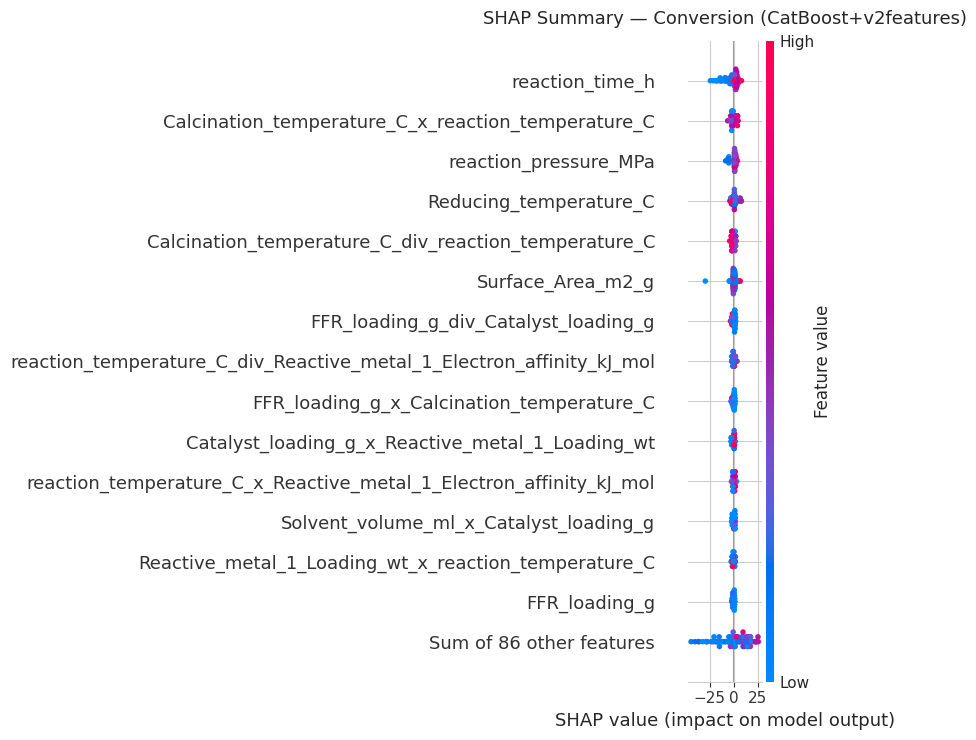

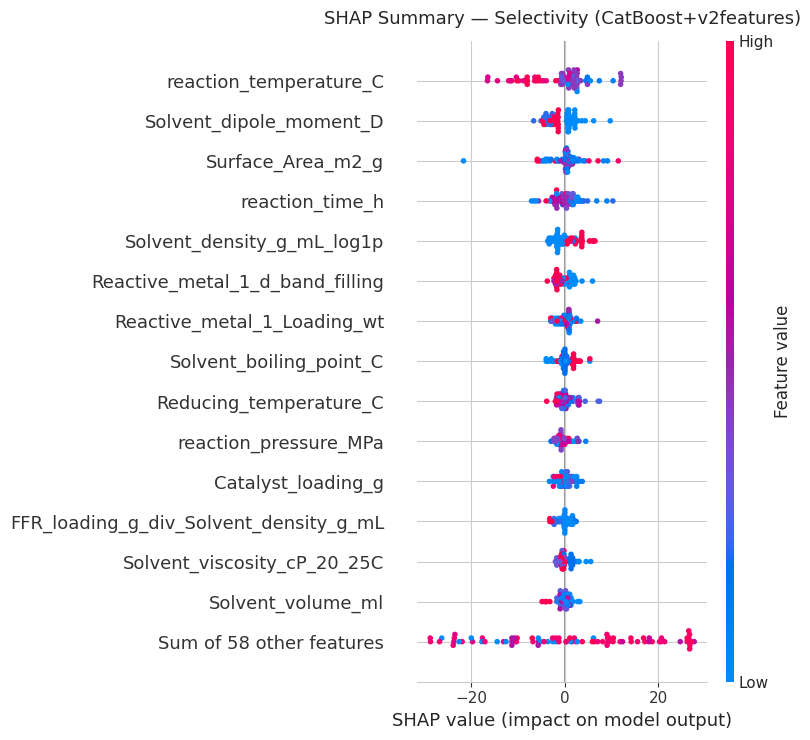

In [76]:
plt.figure()
shap.plots.beeswarm(sv_conv, max_display=15, show=False)
plt.title(f"SHAP Summary — Conversion ({shap_conv_name})", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "shap_beeswarm_conversion.png"), dpi=200, bbox_inches='tight')
plt.show()

plt.figure()
shap.plots.beeswarm(sv_sel, max_display=15, show=False)
plt.title(f"SHAP Summary — Selectivity ({shap_sel_name})", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "shap_beeswarm_selectivity.png"), dpi=200, bbox_inches='tight')
plt.show()


## 54.2 Mean |SHAP value| bar charts — clean feature-ranking for slides
A simpler, more slide-friendly version of the same information: which features matter most
on average, without the beeswarm's dot-cloud density (which can be harder to read at
presentation size/resolution).


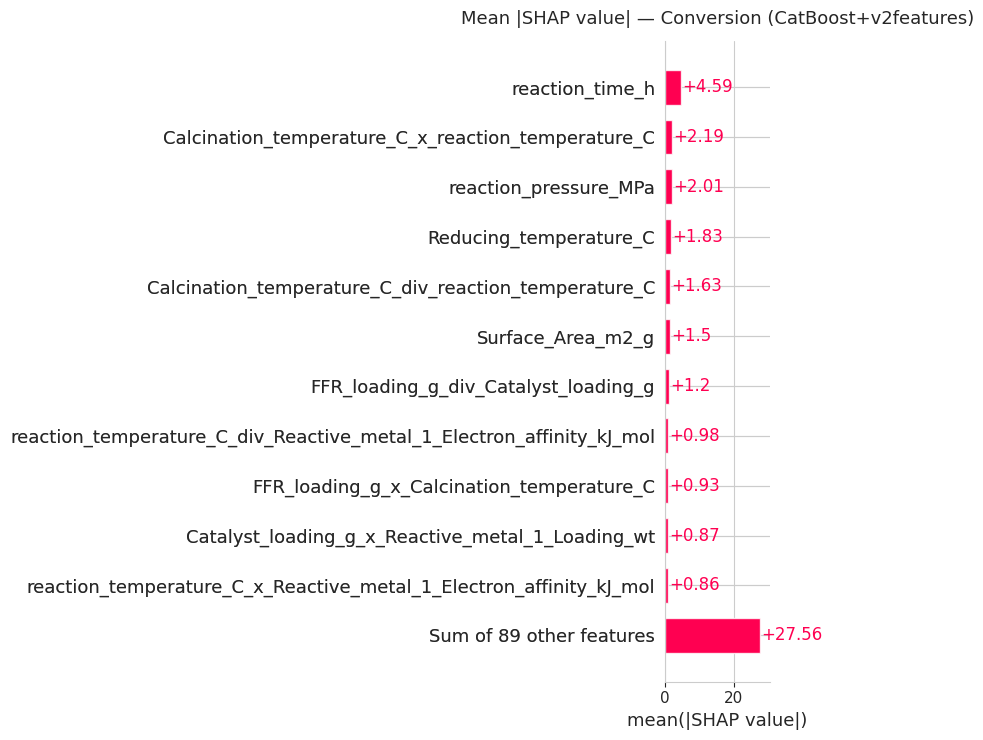

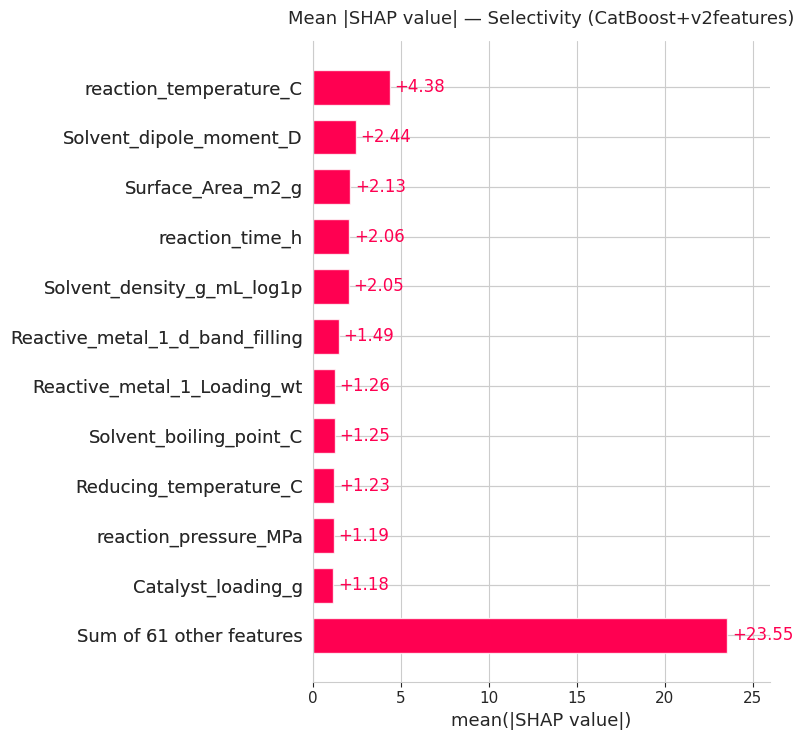

In [77]:
plt.figure()
shap.plots.bar(sv_conv, max_display=12, show=False)
plt.title(f"Mean |SHAP value| — Conversion ({shap_conv_name})", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "shap_bar_conversion.png"), dpi=200, bbox_inches='tight')
plt.show()

plt.figure()
shap.plots.bar(sv_sel, max_display=12, show=False)
plt.title(f"Mean |SHAP value| — Selectivity ({shap_sel_name})", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "shap_bar_selectivity.png"), dpi=200, bbox_inches='tight')
plt.show()


## 54.3 SHAP dependence plots — top feature, effect shape
Shows how the prediction changes as the single most important feature varies, colored by
the feature it interacts with most strongly. Useful for a viva question like "so what does
the model actually say about [top feature]?" — this plot answers it directly with a shape,
not just an importance number.


<Figure size 640x480 with 0 Axes>

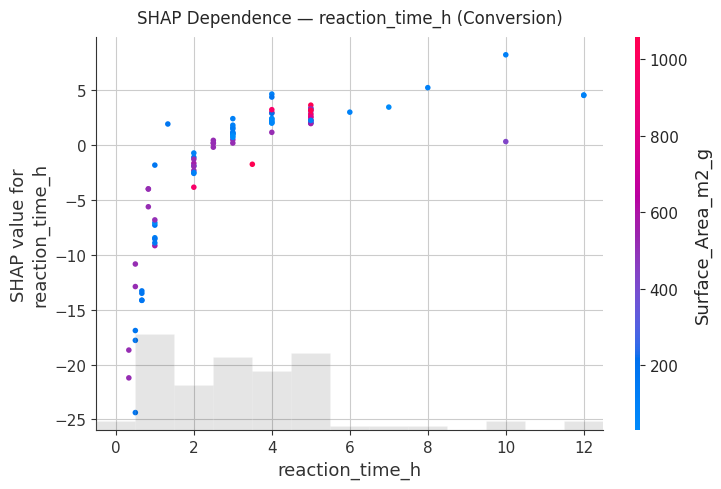

<Figure size 640x480 with 0 Axes>

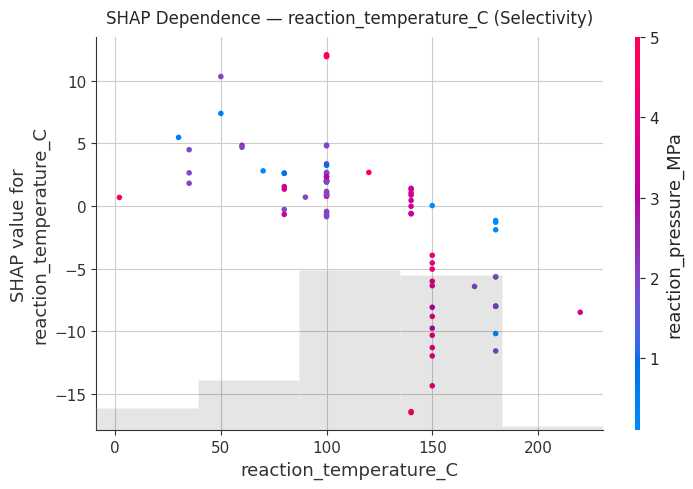

Top feature driving Conversion predictions: reaction_time_h
Top feature driving Selectivity predictions: reaction_temperature_C


In [78]:
top_feat_conv = pd.Series(np.abs(sv_conv.values).mean(axis=0), index=X_test_shap_conv.columns).idxmax()
top_feat_sel  = pd.Series(np.abs(sv_sel.values).mean(axis=0),  index=X_test_shap_sel.columns).idxmax()

plt.figure()
shap.plots.scatter(sv_conv[:, top_feat_conv], color=sv_conv, show=False)
plt.title(f"SHAP Dependence — {top_feat_conv} (Conversion)", fontsize=12, pad=10)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "shap_dependence_conversion.png"), dpi=200, bbox_inches='tight')
plt.show()

plt.figure()
shap.plots.scatter(sv_sel[:, top_feat_sel], color=sv_sel, show=False)
plt.title(f"SHAP Dependence — {top_feat_sel} (Selectivity)", fontsize=12, pad=10)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "shap_dependence_selectivity.png"), dpi=200, bbox_inches='tight')
plt.show()

print(f"Top feature driving Conversion predictions: {top_feat_conv}")
print(f"Top feature driving Selectivity predictions: {top_feat_sel}")


## 54.4 Local explanations — waterfall plots for individual predictions
Global plots explain the model overall; a waterfall plot explains **one specific row** —
exactly how each feature pushed that single prediction up or down from the average. Shown
for the best-predicted and worst-predicted test row for each target, which makes a good
"here's a case that worked, here's one that didn't" slide for the panel.


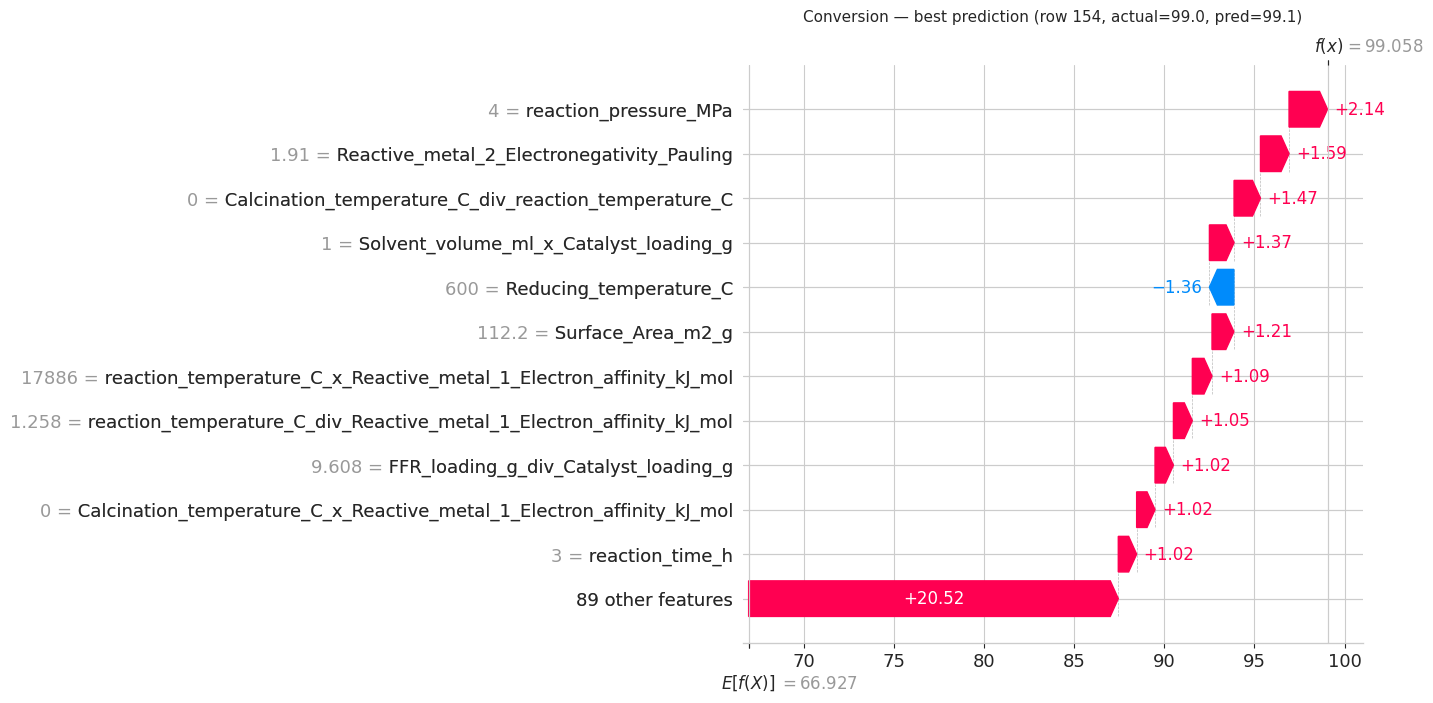

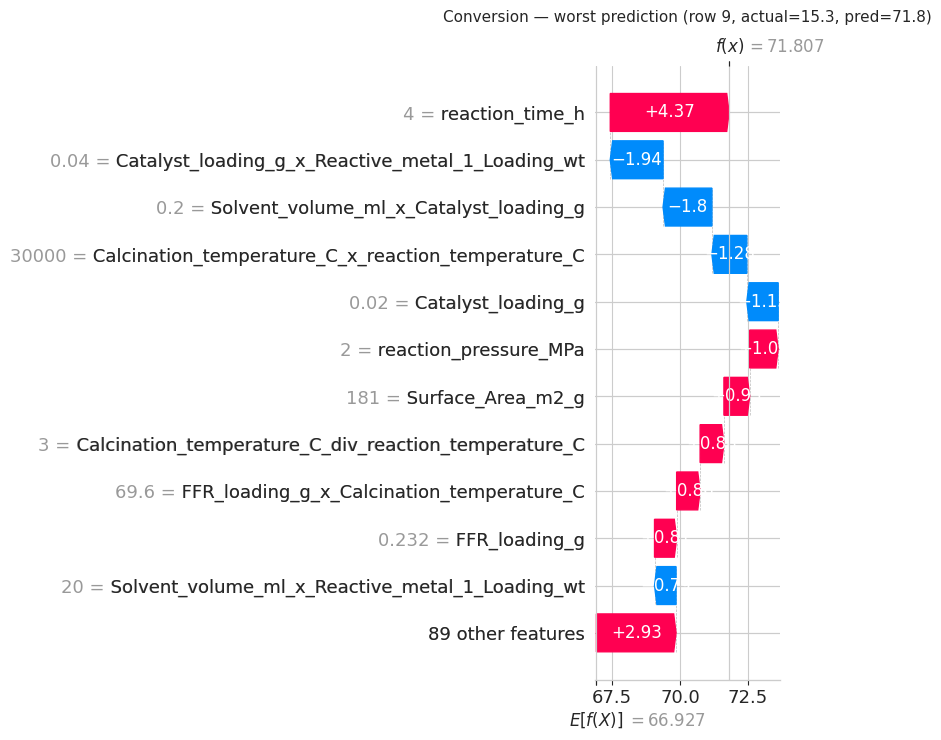

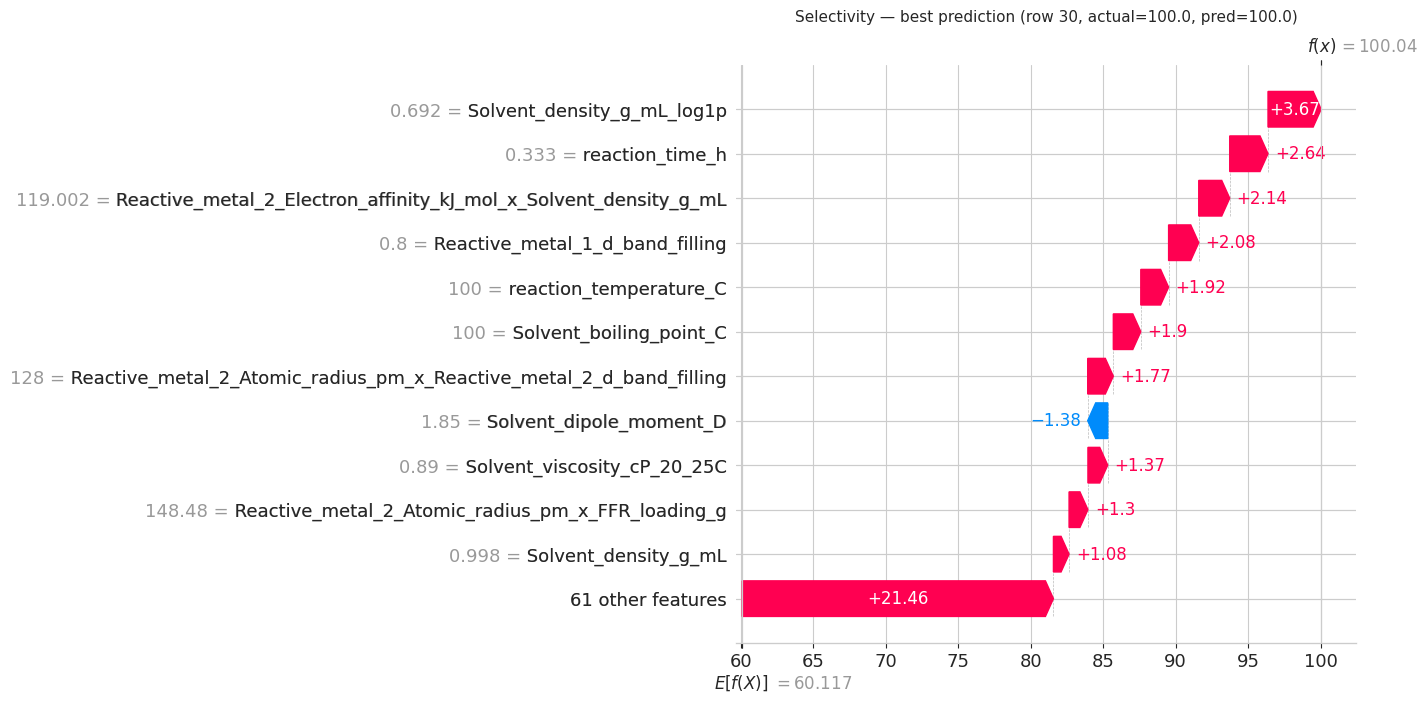

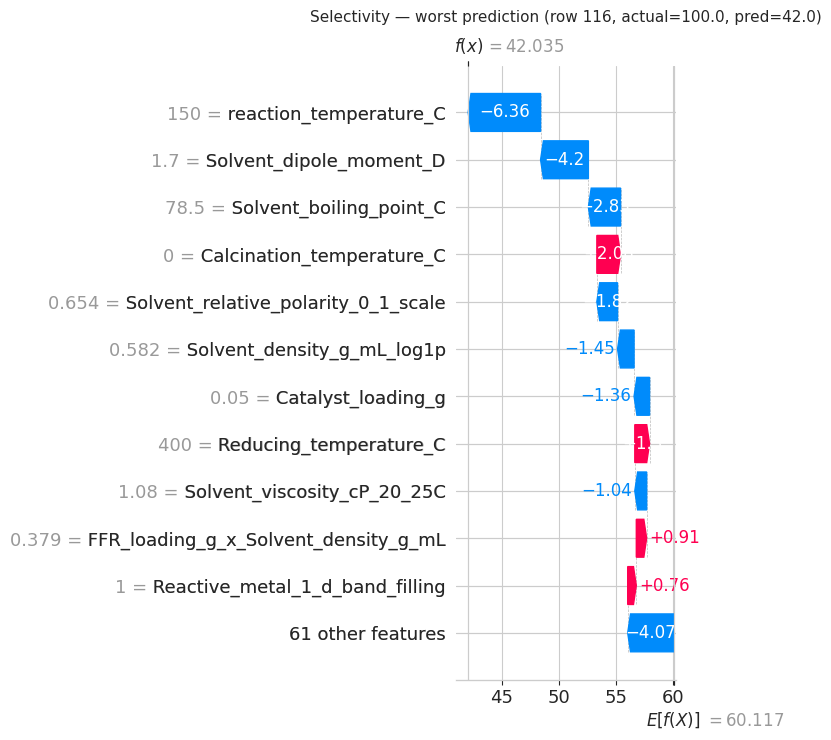

In [79]:
def plot_waterfalls(sv, X_test_df, y_test, target_label, model_name):
    preds = sv.values.sum(axis=1) + sv.base_values
    if np.ndim(sv.base_values) == 0:
        base = sv.base_values
    else:
        base = sv.base_values[0]
    y_arr = y_test.values if hasattr(y_test, 'values') else np.asarray(y_test)
    resid = np.abs(y_arr - preds)
    best_i = int(np.argmin(resid))
    worst_i = int(np.argmax(resid))

    for tag, i in [('best', best_i), ('worst', worst_i)]:
        plt.figure()
        shap.plots.waterfall(sv[i], max_display=12, show=False)
        plt.title(f"{target_label} — {tag} prediction (row {X_test_df.index[i]}, "
                  f"actual={y_arr[i]:.1f}, pred={preds[i]:.1f})", fontsize=11, pad=10)
        plt.tight_layout()
        fname = f"shap_waterfall_{target_label.lower()}_{tag}.png"
        plt.savefig(os.path.join(FIGURE_DIR, fname), dpi=200, bbox_inches='tight')
        plt.show()

plot_waterfalls(sv_conv, X_test_shap_conv, y_conv_test, "Conversion", shap_conv_name)
plot_waterfalls(sv_sel,  X_test_shap_sel,  y_sel_test,  "Selectivity", shap_sel_name)


---
# 55. Presentation-ready graphs for the panel

Clean, high-resolution (200 DPI) figures aimed at a slide deck / viva: model comparison,
final parity plots with error metrics annotated on the plot itself, residual diagnostics,
and one combined "hero" figure pulling the most important panels into a single image.
Everything is saved to `MODEL_DIR/figures` and auto-downloaded at the end of section 55.5.


## 55.1 Model comparison bar chart — top models per target
The single best "we tried a lot of things, here's what won" slide.


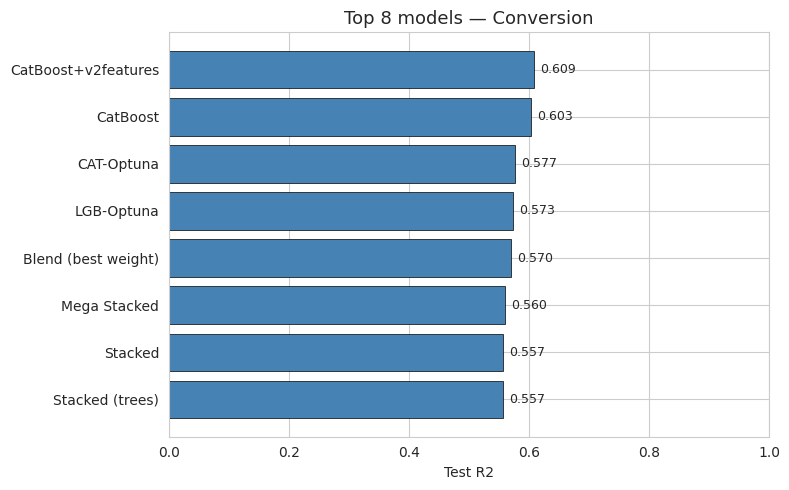

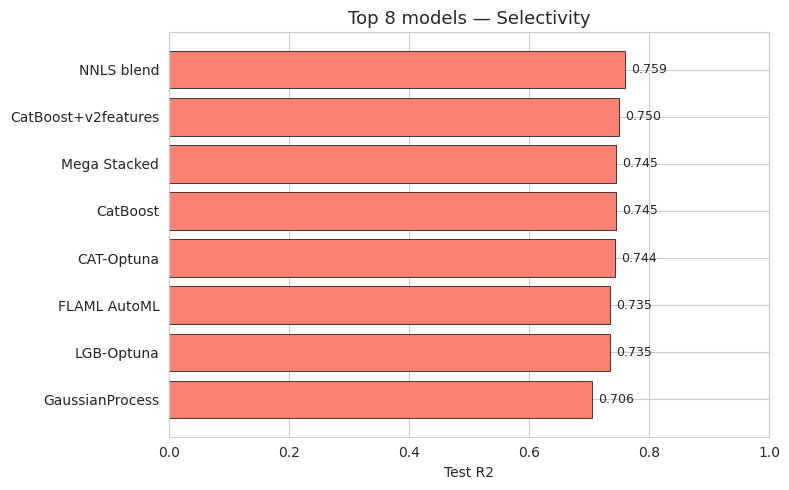

In [80]:
def plot_top_models(df, target_name, top_n=8, color='steelblue'):
    sub = df[df['Target'] == target_name].sort_values('Test_R2', ascending=False).head(top_n)
    sub = sub.iloc[::-1]  # so the best ends up on top when plotted horizontally
    plt.figure(figsize=(8, 5))
    bars = plt.barh(sub['Model'], sub['Test_R2'], color=color, edgecolor='k', linewidth=0.5)
    for bar, val in zip(bars, sub['Test_R2']):
        plt.text(val + 0.01, bar.get_y() + bar.get_height()/2, f"{val:.3f}",
                  va='center', fontsize=9)
    plt.xlabel('Test R2'); plt.title(f'Top {top_n} models — {target_name}', fontsize=13)
    plt.xlim(0, max(1.0, sub['Test_R2'].max() + 0.1))
    plt.tight_layout()
    fname = f"model_comparison_{target_name.lower()}.png"
    plt.savefig(os.path.join(FIGURE_DIR, fname), dpi=200, bbox_inches='tight')
    plt.show()

plot_top_models(grand_summary_v4_sorted, 'Conversion', color='steelblue')
plot_top_models(grand_summary_v4_sorted, 'Selectivity', color='salmon')


## 55.2 Final parity plots (Predicted vs Actual) with R2 / MAE / RMSE annotated
Uses the true overall best from section 53.6 — including the NNLS blend if that's the
winner, via its already-computed `blended_pred_conv` / `blended_pred_sel` arrays, since a
blend has no single `.predict()` call of its own.


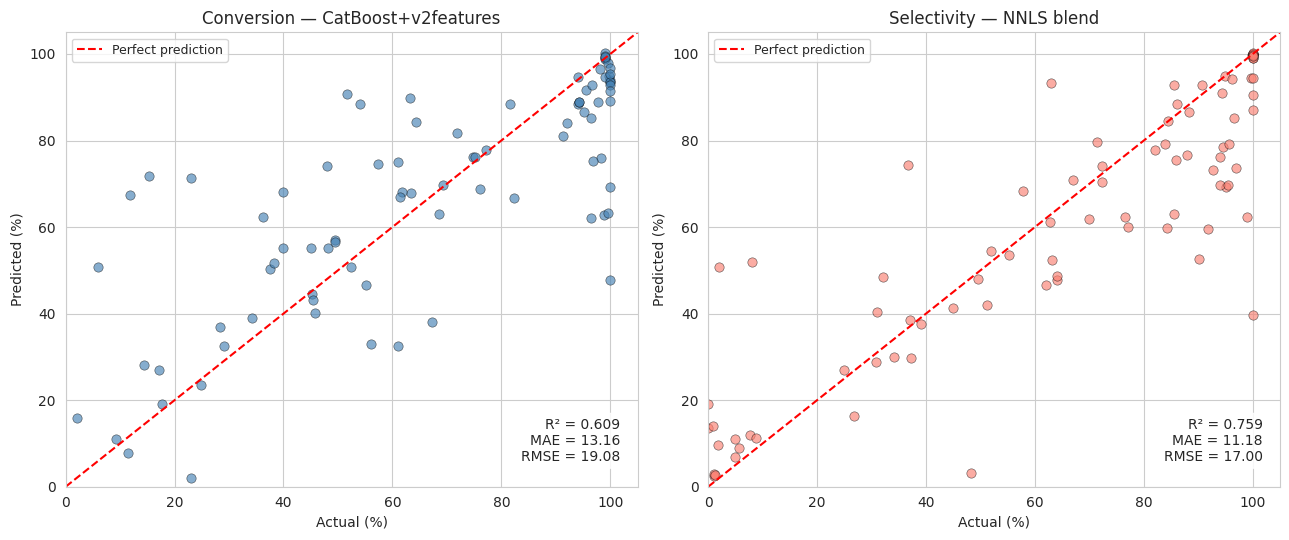

FINAL Conversion  (CatBoost+v2features): R2=0.6091  MAE=13.16  RMSE=19.08
FINAL Selectivity (NNLS blend): R2=0.7595  MAE=11.18  RMSE=17.00


In [81]:
def get_test_X_v4(name, target):
    if name == 'CatBoost+v2features':
        return X_test_fe2_conv if target == 'conv' else X_test_fe2_sel
    if name == 'PCA+XGB':
        return X_test_pca
    if name == 'XGB (outliers removed)':
        return X_test_reduced
    X_test_elem_local = globals().get('X_test_elem', None)
    if name == 'CatBoost+Elemental' and X_test_elem_local is not None:
        return X_test_elem_local
    return get_test_X(name)

def get_final_preds(target):
    name = best_conv_name_v4 if target == 'conv' else best_sel_name_v4
    y_test = y_conv_test if target == 'conv' else y_sel_test
    if name == 'NNLS blend':
        preds = blended_pred_conv if target == 'conv' else blended_pred_sel
        return preds, y_test, name
    registry = model_registry_conv if target == 'conv' else model_registry_sel
    model = registry[name]
    Xte = get_test_X_v4(name, target)
    preds = np.array(model.predict(Xte)).flatten()
    return preds, y_test, name

preds_conv_final, y_conv_final, name_conv_final = get_final_preds('conv')
preds_sel_final,  y_sel_final,  name_sel_final  = get_final_preds('sel')

def parity_plot(y_true, y_pred, title, color, ax):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    ax.scatter(y_true, y_pred, alpha=0.65, color=color, edgecolor='k', linewidth=0.4, s=45)
    lims = [0, 105]
    ax.plot(lims, lims, 'r--', lw=1.5, label='Perfect prediction')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('Actual (%)'); ax.set_ylabel('Predicted (%)')
    ax.set_title(title, fontsize=12)
    ax.legend(loc='upper left', fontsize=9)
    stats_txt = f"R² = {r2:.3f}\nMAE = {mae:.2f}\nRMSE = {rmse:.2f}"
    ax.text(0.97, 0.05, stats_txt, transform=ax.transAxes, fontsize=10,
             ha='right', va='bottom', bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
    return r2, mae, rmse

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
r2c, maec, rmsec = parity_plot(y_conv_final, preds_conv_final,
                                f"Conversion — {name_conv_final}", 'steelblue', axes[0])
r2s, maes, rmses = parity_plot(y_sel_final, preds_sel_final,
                                f"Selectivity — {name_sel_final}", 'salmon', axes[1])
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "final_parity_plots.png"), dpi=200, bbox_inches='tight')
plt.show()

print(f"FINAL Conversion  ({name_conv_final}): R2={r2c:.4f}  MAE={maec:.2f}  RMSE={rmsec:.2f}")
print(f"FINAL Selectivity ({name_sel_final}): R2={r2s:.4f}  MAE={maes:.2f}  RMSE={rmses:.2f}")


## 55.3 Residual diagnostics
Two views: residuals vs predicted value (checks for systematic bias / heteroscedasticity —
a fan shape means the model is less reliable at certain prediction ranges) and a histogram
of residuals (checks whether errors are roughly centered and symmetric, i.e. no consistent
over/under-prediction).


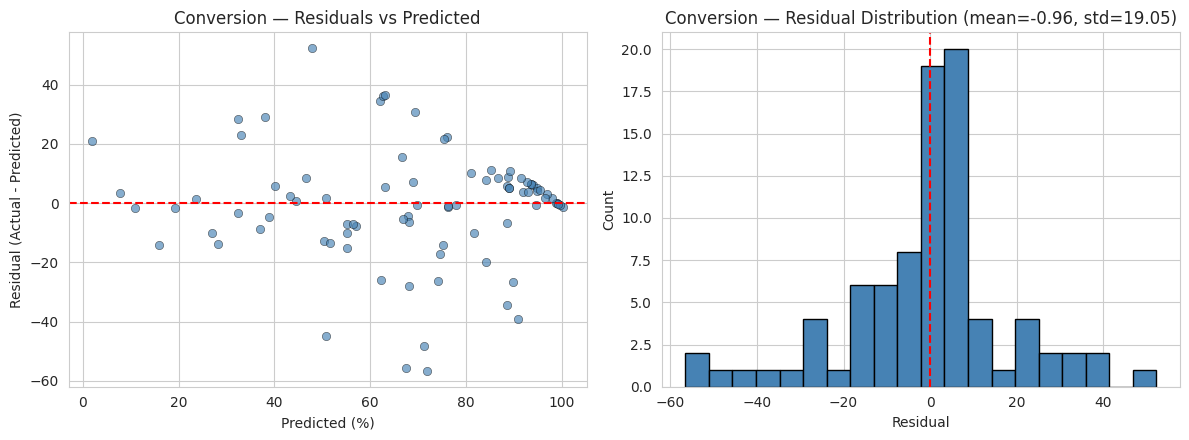

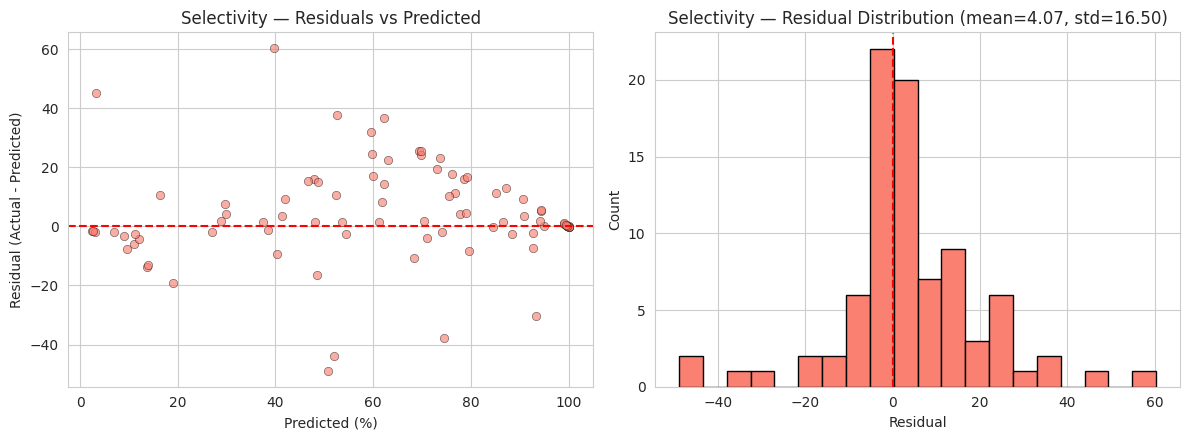

In [82]:
def residual_plots(y_true, y_pred, title, color):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    resid = y_true - y_pred
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].scatter(y_pred, resid, alpha=0.65, color=color, edgecolor='k', linewidth=0.4)
    axes[0].axhline(0, color='r', linestyle='--')
    axes[0].set_xlabel('Predicted (%)'); axes[0].set_ylabel('Residual (Actual - Predicted)')
    axes[0].set_title(f'{title} — Residuals vs Predicted')

    axes[1].hist(resid, bins=20, color=color, edgecolor='k')
    axes[1].axvline(0, color='r', linestyle='--')
    axes[1].set_xlabel('Residual'); axes[1].set_ylabel('Count')
    axes[1].set_title(f'{title} — Residual Distribution (mean={resid.mean():.2f}, std={resid.std():.2f})')
    plt.tight_layout()
    fname = f"residuals_{title.lower()}.png"
    plt.savefig(os.path.join(FIGURE_DIR, fname), dpi=200, bbox_inches='tight')
    plt.show()

residual_plots(y_conv_final, preds_conv_final, "Conversion", 'steelblue')
residual_plots(y_sel_final,  preds_sel_final,  "Selectivity", 'salmon')


## 55.4 Combined "hero" summary figure — one image for the results slide
Pulls the parity plots and SHAP feature-importance bars into a single 2x2 panel figure —
handy as the one image to put on a results slide, with the rest available as backup detail
slides.


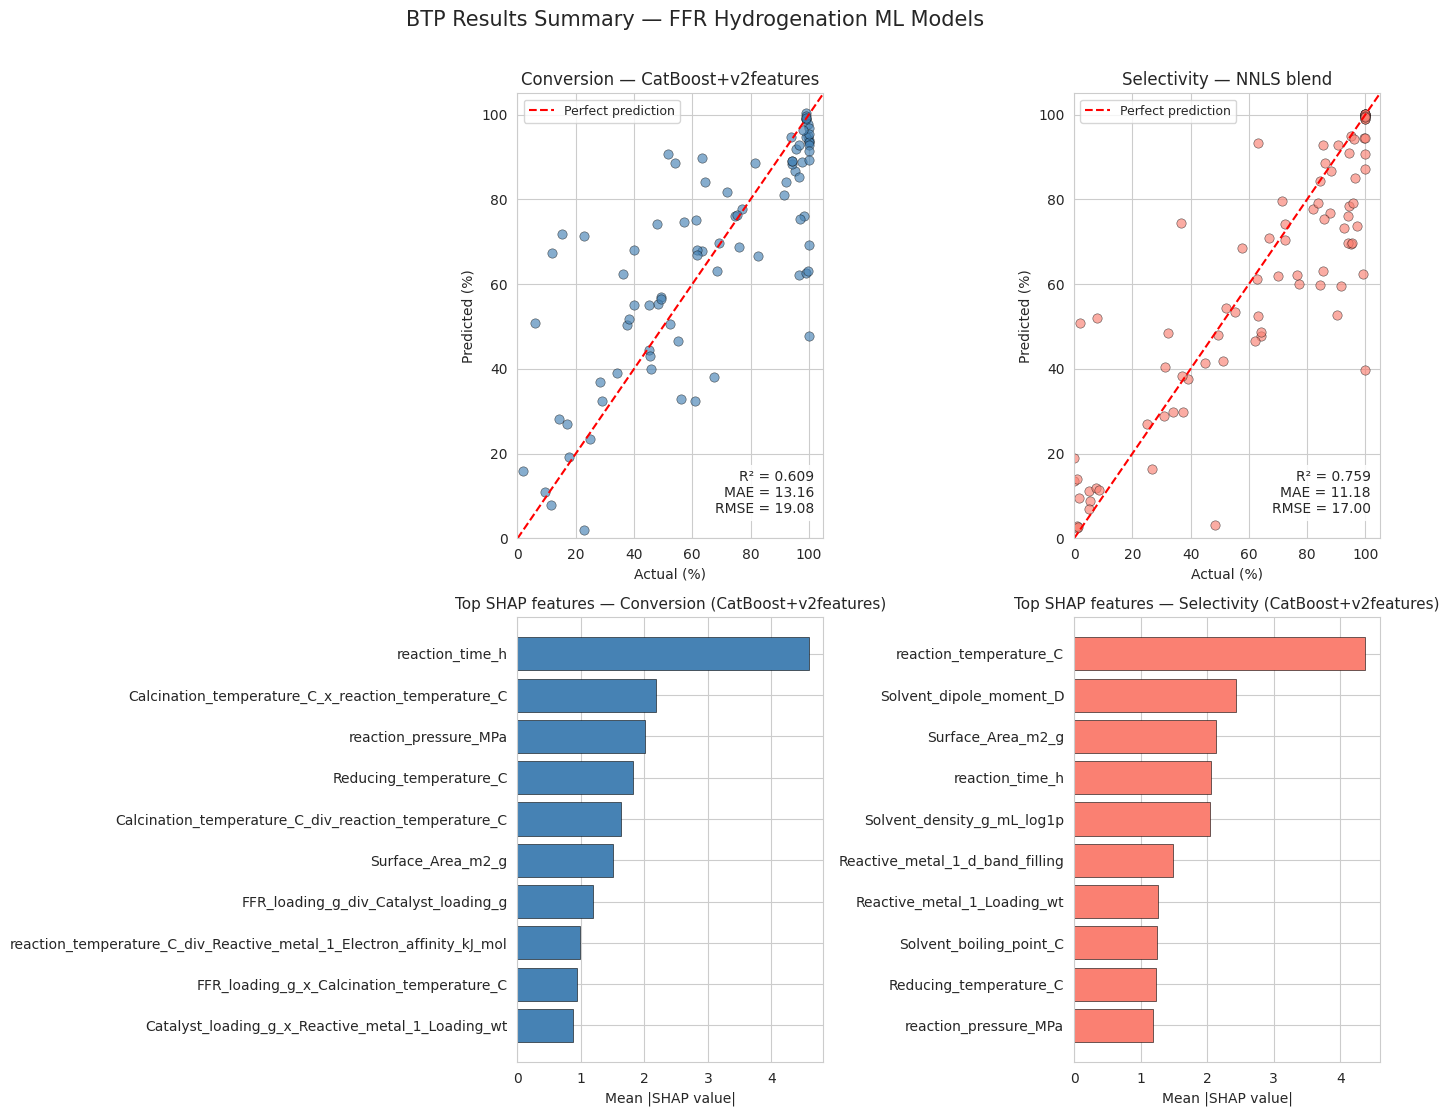

In [83]:
fig = plt.figure(figsize=(14, 11))

ax1 = fig.add_subplot(2, 2, 1)
parity_plot(y_conv_final, preds_conv_final, f"Conversion — {name_conv_final}", 'steelblue', ax1)

ax2 = fig.add_subplot(2, 2, 2)
parity_plot(y_sel_final, preds_sel_final, f"Selectivity — {name_sel_final}", 'salmon', ax2)

ax3 = fig.add_subplot(2, 2, 3)
conv_imp = pd.Series(np.abs(sv_conv.values).mean(axis=0), index=X_test_shap_conv.columns).sort_values(ascending=False).head(10)
ax3.barh(conv_imp.index[::-1], conv_imp.values[::-1], color='steelblue', edgecolor='k', linewidth=0.4)
ax3.set_title(f'Top SHAP features — Conversion ({shap_conv_name})', fontsize=11)
ax3.set_xlabel('Mean |SHAP value|')

ax4 = fig.add_subplot(2, 2, 4)
sel_imp = pd.Series(np.abs(sv_sel.values).mean(axis=0), index=X_test_shap_sel.columns).sort_values(ascending=False).head(10)
ax4.barh(sel_imp.index[::-1], sel_imp.values[::-1], color='salmon', edgecolor='k', linewidth=0.4)
ax4.set_title(f'Top SHAP features — Selectivity ({shap_sel_name})', fontsize=11)
ax4.set_xlabel('Mean |SHAP value|')

fig.suptitle('BTP Results Summary — FFR Hydrogenation ML Models', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "results_summary_hero.png"), dpi=220, bbox_inches='tight')
plt.show()


## 55.5 Save everything & auto-download for the panel


In [84]:
import glob

saved_figs = sorted(glob.glob(os.path.join(FIGURE_DIR, "*.png")))
print(f"{len(saved_figs)} figures saved to {FIGURE_DIR}:")
for f in saved_figs:
    print(" -", os.path.basename(f))

try:
    from google.colab import files
    for fpath in saved_figs:
        files.download(fpath)
    print(f"\nTriggered browser download for {len(saved_figs)} figures.")
except ImportError:
    print("\nNot running in Colab — skipping auto-download. Figures are saved in", FIGURE_DIR)


24 figures saved to /content/drive/MyDrive/BTP_Sem_7/saved_models/figures:
 - final_parity_plots.png
 - model_comparison_conversion.png
 - model_comparison_selectivity.png
 - moo_crosscheck.png
 - moo_pareto_and_convergence.png
 - moo_pareto_decision_heatmap.png
 - moo_shap_pareto_and_convergence.png
 - moo_shap_pareto_decision_heatmap.png
 - moo_shap_selected_features.png
 - residuals_conversion.png
 - residuals_selectivity.png
 - results_summary_hero.png
 - shap_bar_conversion.png
 - shap_bar_selectivity.png
 - shap_beeswarm_conversion.png
 - shap_beeswarm_selectivity.png
 - shap_dependence_conversion.png
 - shap_dependence_selectivity.png
 - shap_heatmap_conversion.png
 - shap_heatmap_selectivity.png
 - shap_waterfall_conversion_best.png
 - shap_waterfall_conversion_worst.png
 - shap_waterfall_selectivity_best.png
 - shap_waterfall_selectivity_worst.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (40 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Triggered browser download for 24 figures.


---
# 56. SHAP heatmap plots

One more SHAP view, added after everything above (nothing else changed): the heatmap shows
every test-set row along the x-axis and every feature along the y-axis, colored by that
feature's SHAP value for that row, with the model's output plotted along the top. It's a
good complement to the beeswarm in section 54.1 — the beeswarm shows the overall
distribution of effects per feature, this shows row-by-row patterns (e.g. whether a cluster
of test rows all get pushed the same direction by the same features).

Uses the same SHAP explanation objects (`sv_conv`, `sv_sel`) already computed in section 54,
so this must be run after section 54.


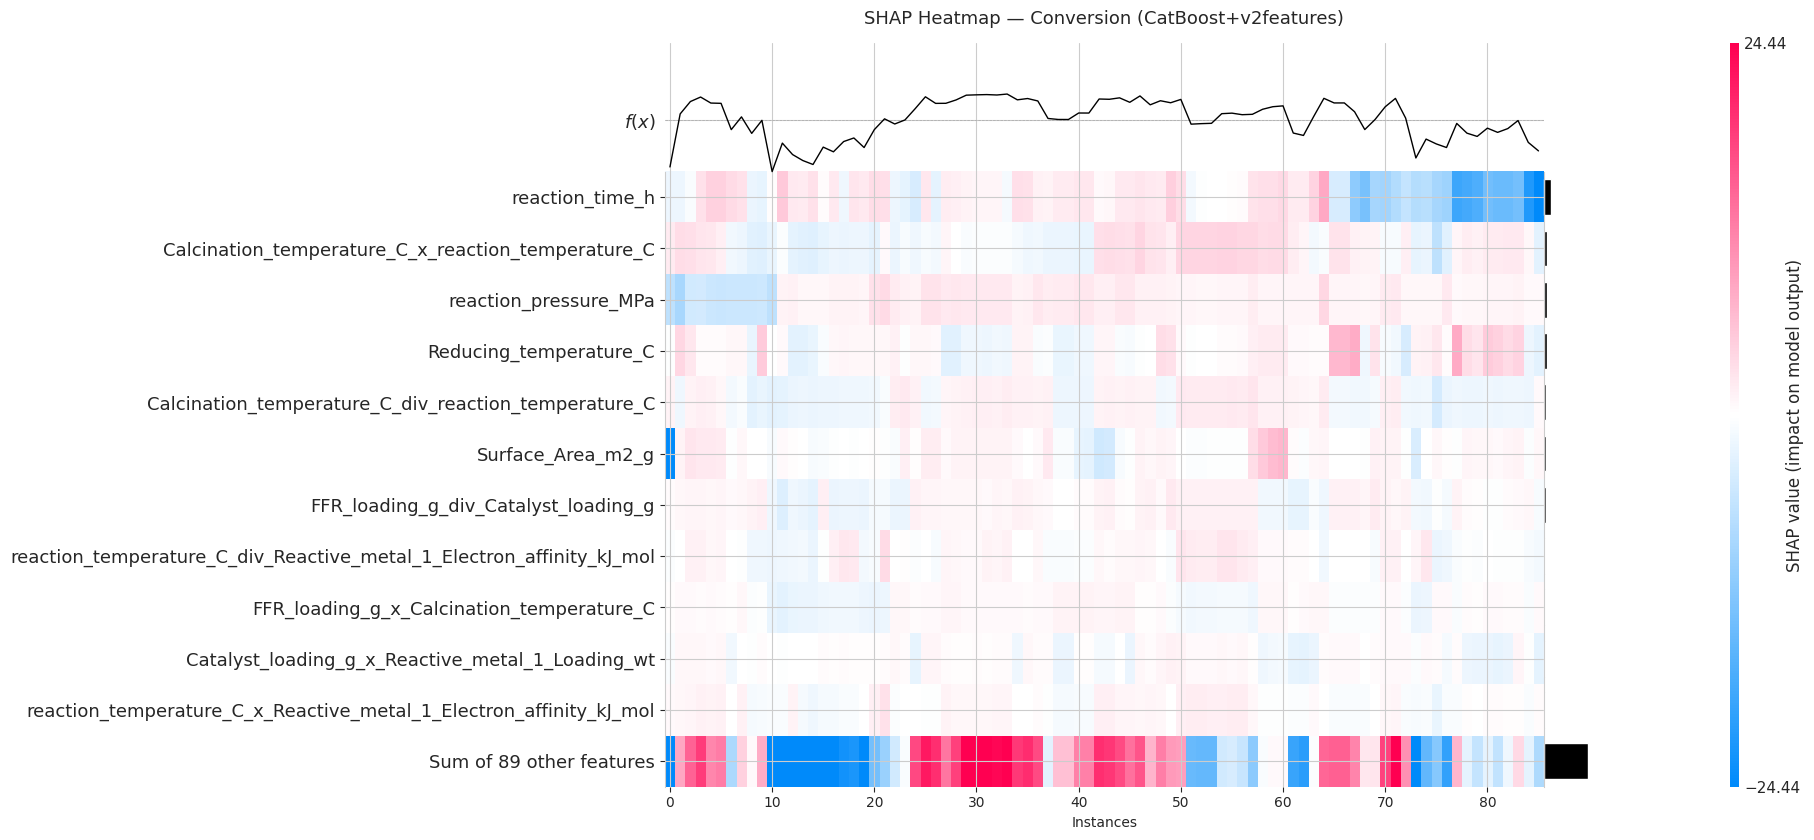

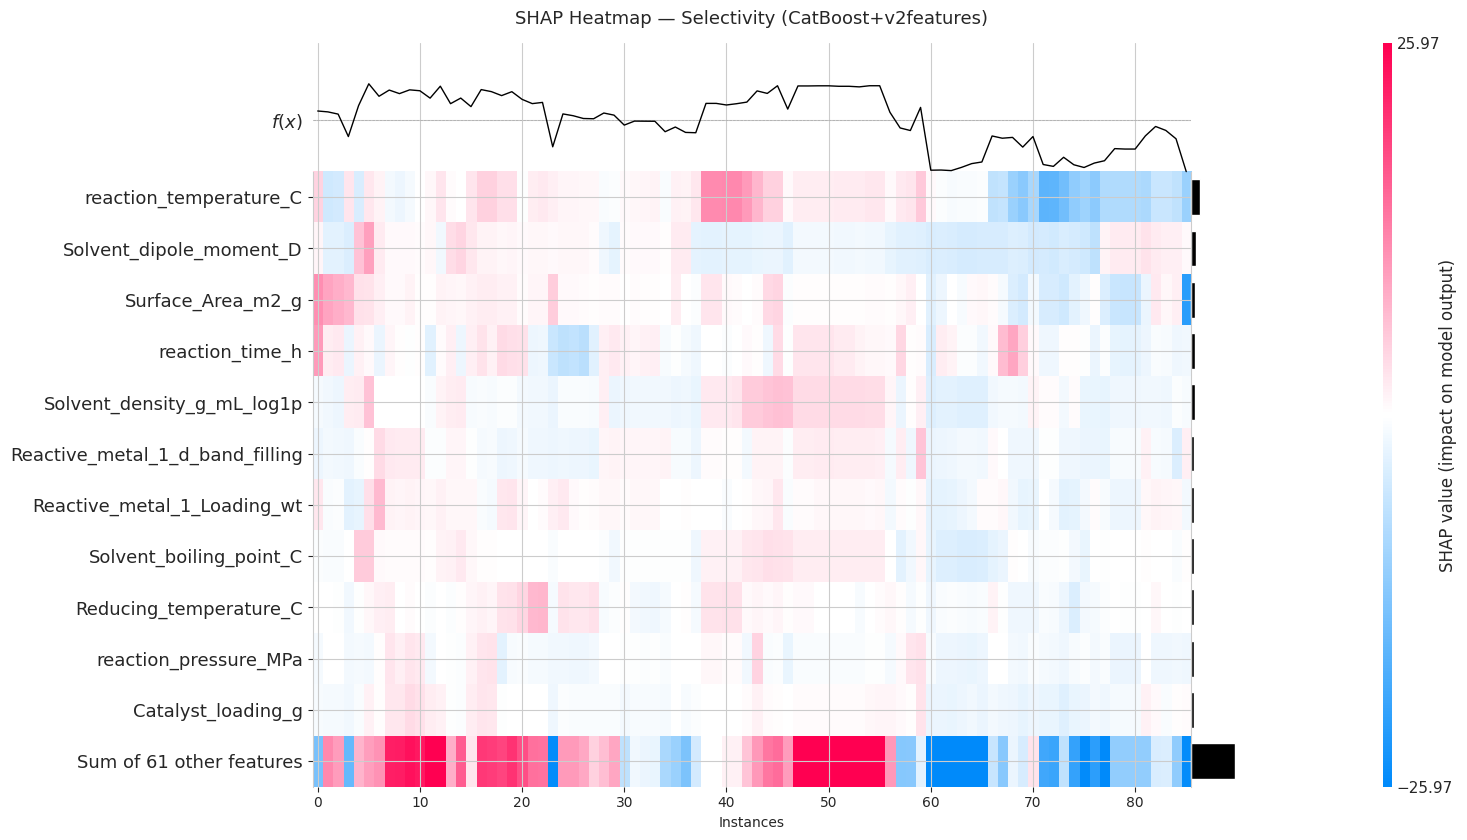

In [85]:
plt.figure(figsize=(14, 8))
shap.plots.heatmap(sv_conv, max_display=12, plot_width=20, show=False)
plt.title(f"SHAP Heatmap — Conversion ({shap_conv_name})", fontsize=13, pad=14)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "shap_heatmap_conversion.png"), dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(14, 8))
shap.plots.heatmap(sv_sel, max_display=12, plot_width=20, show=False)
plt.title(f"SHAP Heatmap — Selectivity ({shap_sel_name})", fontsize=13, pad=14)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "shap_heatmap_selectivity.png"), dpi=200, bbox_inches='tight')
plt.show()

## 56.1 Re-download figures (now including the two heatmaps)


In [86]:
import glob as _glob

saved_figs_v2 = sorted(_glob.glob(os.path.join(FIGURE_DIR, "*.png")))
print(f"{len(saved_figs_v2)} figures now saved to {FIGURE_DIR}:")
for f in saved_figs_v2:
    print(" -", os.path.basename(f))

try:
    from google.colab import files
    for fpath in saved_figs_v2:
        files.download(fpath)
    print(f"\nTriggered browser download for {len(saved_figs_v2)} figures.")
except ImportError:
    print("\nNot running in Colab — skipping auto-download. Figures are saved in", FIGURE_DIR)


24 figures now saved to /content/drive/MyDrive/BTP_Sem_7/saved_models/figures:
 - final_parity_plots.png
 - model_comparison_conversion.png
 - model_comparison_selectivity.png
 - moo_crosscheck.png
 - moo_pareto_and_convergence.png
 - moo_pareto_decision_heatmap.png
 - moo_shap_pareto_and_convergence.png
 - moo_shap_pareto_decision_heatmap.png
 - moo_shap_selected_features.png
 - residuals_conversion.png
 - residuals_selectivity.png
 - results_summary_hero.png
 - shap_bar_conversion.png
 - shap_bar_selectivity.png
 - shap_beeswarm_conversion.png
 - shap_beeswarm_selectivity.png
 - shap_dependence_conversion.png
 - shap_dependence_selectivity.png
 - shap_heatmap_conversion.png
 - shap_heatmap_selectivity.png
 - shap_waterfall_conversion_best.png
 - shap_waterfall_conversion_worst.png
 - shap_waterfall_selectivity_best.png
 - shap_waterfall_selectivity_worst.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (40 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Triggered browser download for 24 figures.


---
# 57. Multi-objective optimisation — NSGA-II vs SPEA2

Everything above this point is untouched. Sections 1-56 built, tuned, compared and explained the
surrogate models that predict **FFR Conversion (%)** and **Selectivity (%)**. This section uses
those trained models as a fast "virtual experiment" and asks the *inverse* question:

> **Which reaction conditions + catalyst/solvent systems give the best possible trade-off between
> Conversion and Selectivity?**

Because the two targets usually compete (pushing conversion up tends to cost selectivity), there is
no single best answer — there is a **Pareto front** of non-dominated solutions. Two classic
evolutionary multi-objective algorithms are run and compared:

| | **NSGA-II** | **SPEA2** |
|---|---|---|
| Fitness idea | Non-dominated sorting into fronts, then **crowding distance** to keep solutions spread out | **Strength** (how many solutions each one dominates) + **k-th nearest-neighbour density** |
| Elitism | Parents + offspring merged, best N survive | Separate fixed-size **external archive** of non-dominated solutions |
| Diversity | Crowding distance | Nearest-neighbour density + archive truncation |

**Design choices (so the optimiser can only propose chemically sensible catalysts):**
- **Continuous decision variables** — reaction temperature, pressure, time, FFR loading, catalyst
  loading, solvent volume, metal-1 loading, metal-2 loading — each bounded to the range actually
  seen in your dataset (1st-99th percentile), so the surrogate is never asked to extrapolate wildly.
- **Two categorical choices** — *catalyst system* (metals + support + preparation temperatures +
  surface area, taken as an intact bundle from a real catalyst in the dataset) and *reaction medium*
  (solvent properties + H2 source, again as a real bundle). The optimiser picks *which real system*
  to use rather than inventing physically impossible descriptor combinations (e.g. a made-up metal).
- **Objectives** — maximise Conversion and maximise Selectivity (pymoo minimises, so they enter as
  `-Conversion`, `-Selectivity`). An optional third objective (minimise temperature or catalyst
  loading) can be switched on in the config cell.
- Each algorithm is run over several random seeds, because a single run of a stochastic optimiser
  is not a fair basis for declaring a winner.

Needs the objects from earlier sections (`X_train_reduced`, `X_full_reduced`, `model_registry_conv/sel`,
`grand_summary_v4_sorted`, `scaler_nn`, `df_clean`, `FIGURE_DIR`) — run those first.

## 57.1 Install, imports & configuration

In [87]:
!pip install -q pymoo

import re, time
from pymoo.core.problem import Problem
from pymoo.core.callback import Callback
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.spea2 import SPEA2
from pymoo.optimize import minimize
from pymoo.indicators.hv import HV
from pymoo.indicators.igd_plus import IGDPlus
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
from sklearn.neighbors import NearestNeighbors

# ----------------------------- configuration -----------------------------
MOO_POP_SIZE   = 100     # population size (NSGA-II) / archive+population size (SPEA2)
MOO_N_GEN      = 200     # generations per run
MOO_N_SEEDS    = 5       # independent runs per algorithm (different random seeds)
MOO_BASE_SEED  = 42
BOUND_PCT      = (1, 99) # decision-variable bounds = these percentiles of the observed data

# Optional 3rd objective (both are MINIMISED):  None | 'temperature' | 'catalyst_loading'
EXTRA_OBJECTIVE = None
EXTRA_OBJ_COLUMN = {'temperature': 'reaction_temperature_C',
                    'catalyst_loading': 'Catalyst_loading_g'}

# Continuous process variables the optimiser is allowed to tune (names must match X_train_reduced)
CONT_VARS = ['reaction_temperature_C', 'reaction_pressure_MPa', 'reaction_time_h',
             'FFR_loading_g', 'Catalyst_loading_g', 'Solvent_volume_ml',
             'Reactive_metal_1_Loading_wt', 'Reactive_metal_2_Loading_wt']
CONT_VARS = [c for c in CONT_VARS if c in X_train_reduced.columns]

print("Continuous decision variables:", CONT_VARS)
print("Extra objective:", EXTRA_OBJECTIVE)

Continuous decision variables: ['reaction_temperature_C', 'reaction_pressure_MPa', 'reaction_time_h', 'FFR_loading_g', 'Catalyst_loading_g', 'Solvent_volume_ml', 'Reactive_metal_1_Loading_wt', 'Reactive_metal_2_Loading_wt']
Extra objective: None


## 57.2 Choose the surrogate models (reuses your already-trained models)
No retraining happens here. For each target the best-scoring model **that predicts from the
`X_train_reduced` feature space** is taken from the section 53.6 grand comparison (the NNLS blend,
PCA models, engineered-feature models and neural nets use other feature spaces, so they are skipped —
they can't be fed a raw decoded candidate directly). A second, different model is also picked per
target and used later as an independent cross-check on the optimiser's claims.

In [88]:
REDUCED_SPACE_MODELS = {'RF (grid)', 'XGB (grid)', 'GB (grid)', 'Stacked', 'CatBoost', 'ExtraTrees',
                        'XGB-Optuna', 'LGB-Optuna', 'CAT-Optuna', 'Mega Stacked',
                        'XGB (outliers removed)', 'FLAML AutoML'}

def pick_surrogate(target, exclude=None):
    # Best-Test-R2 model for 'conv'/'sel' that works directly on X_train_reduced columns.
    tname = 'Conversion' if target == 'conv' else 'Selectivity'
    registry = model_registry_conv if target == 'conv' else model_registry_sel
    rows = grand_summary_v4_sorted[grand_summary_v4_sorted['Target'] == tname]
    for _, row in rows.iterrows():
        name = row['Model']
        if name in REDUCED_SPACE_MODELS and name in registry and name != exclude:
            return name, registry[name], float(row['Test_R2'])
    raise RuntimeError(f"No reduced-feature-space surrogate found for {tname}")

surr_conv_name, surr_conv, surr_conv_r2 = pick_surrogate('conv')
surr_sel_name,  surr_sel,  surr_sel_r2  = pick_surrogate('sel')
alt_conv_name, alt_conv, alt_conv_r2 = pick_surrogate('conv', exclude=surr_conv_name)
alt_sel_name,  alt_sel,  alt_sel_r2  = pick_surrogate('sel',  exclude=surr_sel_name)

print(f"Primary surrogate  - Conversion : {surr_conv_name} (Test R2 = {surr_conv_r2:.3f})")
print(f"Primary surrogate  - Selectivity: {surr_sel_name} (Test R2 = {surr_sel_r2:.3f})")
print(f"Cross-check model  - Conversion : {alt_conv_name} (Test R2 = {alt_conv_r2:.3f})")
print(f"Cross-check model  - Selectivity: {alt_sel_name} (Test R2 = {alt_sel_r2:.3f})")

Primary surrogate  - Conversion : CatBoost (Test R2 = 0.603)
Primary surrogate  - Selectivity: Mega Stacked (Test R2 = 0.745)
Cross-check model  - Conversion : CAT-Optuna (Test R2 = 0.577)
Cross-check model  - Selectivity: CatBoost (Test R2 = 0.745)


## 57.3 Build the search space: continuous variables + catalogs of real catalyst / medium systems
The remaining feature columns are split into two *bundles* that always travel together:
- **catalyst system** — metal descriptors, support descriptors, surface area, reduction/calcination temperature
- **reaction medium** — solvent descriptors, H-bond flags and the H2-source one-hot columns

Every unique bundle that appears in the dataset becomes a catalog entry; the optimiser chooses an
entry by index. Readable names are pulled from `df_clean` (the pre-encoding table) for reporting.

In [89]:
feature_cols = list(X_train_reduced.columns)

medium_cols   = [c for c in feature_cols if (c.startswith('Solvent_') and c != 'Solvent_volume_ml')
                 or c.startswith('H2_source_')]
catalyst_cols = [c for c in feature_cols if c not in CONT_VARS and c not in medium_cols]
assert set(CONT_VARS) | set(medium_cols) | set(catalyst_cols) == set(feature_cols)
assert not (set(CONT_VARS) & set(medium_cols)) and not (set(CONT_VARS) & set(catalyst_cols))
print(f"{len(CONT_VARS)} continuous vars | {len(catalyst_cols)} catalyst-bundle cols | {len(medium_cols)} medium-bundle cols")

M2_LOAD = 'Reactive_metal_2_Loading_wt'

def build_catalog(cols, sort_candidates):
    # Unique bundles of `cols` seen in the data, in first-appearance order, with row count + first row index.
    cat = X_full_reduced[cols].drop_duplicates().reset_index(drop=True)
    keys = [X_full_reduced[c] for c in cols]
    first_idx = X_full_reduced.index.to_series().groupby(keys, sort=False, dropna=False).first().values
    n_rows = X_full_reduced.index.to_series().groupby(keys, sort=False, dropna=False).size().values
    assert len(cat) == len(first_idx), "catalog/group mismatch"
    cat['first_idx'], cat['n_rows'] = first_idx, n_rows
    if M2_LOAD in X_full_reduced.columns:
        cat['max_m2_loading'] = X_full_reduced[M2_LOAD].groupby(keys, sort=False, dropna=False).max().values
    sk = [c for c in sort_candidates if c in cat.columns]
    return cat.sort_values(sk).reset_index(drop=True) if sk else cat

def _label(df_src, idx, cols, fmt):
    try:
        row = df_src.loc[idx]
        return fmt.format(*[row[c] for c in cols])
    except Exception:
        return f"system@row{idx}"

# ---- unique catalyst systems seen in the data (neighbours in index ~ similar chemistry) ----
cat_catalog = build_catalog(catalyst_cols, ['Reactive_metal_1_Electronegativity_Pauling',
                                            'Reactive_metal_2_Electronegativity_Pauling'])
cat_catalog['is_mono'] = (cat_catalog['max_m2_loading'] == 0) if 'max_m2_loading' in cat_catalog else False
cat_catalog['label'] = [_label(df_clean, i, ['Catalyst type'], "{}") for i in cat_catalog['first_idx']]

# ---- unique reaction media (solvent bundle + H2 source) ----
med_catalog = build_catalog(medium_cols, ['Solvent_relative_polarity_0_1_scale', 'Solvent_boiling_point_C'])
med_catalog['label'] = [_label(df_clean, i, ['Solvent type', 'H2 source'], "{} | H2 source: {}")
                        for i in med_catalog['first_idx']]

N_CAT, N_MED = len(cat_catalog), len(med_catalog)
print(f"Catalog: {N_CAT} unique catalyst systems, {N_MED} unique reaction media")

# ---- bounds for the continuous variables (from observed data, ignoring zeros for loadings) ----
lo_hi = {}
for c in CONT_VARS:
    col = X_full_reduced[c].astype(float)
    if 'Loading_wt' in c:
        col = col[col > 0]
    lo, hi = np.percentile(col, BOUND_PCT[0]), np.percentile(col, BOUND_PCT[1])
    if hi <= lo:                       # constant-ish column -> tiny window so pymoo doesn't choke
        hi = lo + 1e-6
    lo_hi[c] = (float(lo), float(hi))
bounds_df = pd.DataFrame(lo_hi, index=['lower', 'upper']).T
bounds_df

8 continuous vars | 13 catalyst-bundle cols | 14 medium-bundle cols
Catalog: 132 unique catalyst systems, 22 unique reaction media


,lower,upper
reaction_temperature_C,30.000000,187.5000
reaction_pressure_MPa,0.100000,6.0000
reaction_time_h,0.333333,12.0000
FFR_loading_g,0.005896,29.0000
Catalyst_loading_g,0.010000,1.2000
Solvent_volume_ml,5.000000,175.0000
Reactive_metal_1_Loading_wt,0.190000,50.3900
Reactive_metal_2_Loading_wt,0.137200,35.9716


## 57.4 Decoder + the optimisation problem
`decode_population` turns a row of decision variables `[8 continuous values, catalyst index, medium index]`
into a full feature row with exactly the columns/dtypes the surrogates were trained on. Catalog indices
are real numbers in `[0, N)` that are floored to an integer — a standard way to let real-coded
crossover/mutation handle a categorical choice. Monometallic catalysts automatically get metal-2
loading = 0.

In [90]:
_feature_dtypes = X_train_reduced.dtypes.to_dict()
_cat_vals = cat_catalog[catalyst_cols].to_numpy(dtype=float)
_med_vals = med_catalog[medium_cols].to_numpy(dtype=float)
_cat_is_mono = cat_catalog['is_mono'].to_numpy()

def decode_indices(X):
    X = np.atleast_2d(X)
    ci = np.clip(np.floor(X[:, len(CONT_VARS)]).astype(int), 0, N_CAT - 1)
    mi = np.clip(np.floor(X[:, len(CONT_VARS) + 1]).astype(int), 0, N_MED - 1)
    return ci, mi

def decode_population(X):
    # Decision vectors -> DataFrame with X_train_reduced's exact columns & dtypes.
    X = np.atleast_2d(X)
    n = X.shape[0]
    ci, mi = decode_indices(X)
    df = pd.DataFrame(index=range(n), columns=feature_cols, dtype=float)
    df[catalyst_cols] = _cat_vals[ci]
    df[medium_cols]   = _med_vals[mi]
    for j, c in enumerate(CONT_VARS):
        df[c] = X[:, j]
    if M2_LOAD in df.columns:
        df.loc[_cat_is_mono[ci], M2_LOAD] = 0.0
    return df.astype(_feature_dtypes)

class FFRMOOProblem(Problem):
    # Minimise [-Conversion, -Selectivity (, extra objective)] using the trained surrogates.
    def __init__(self):
        n_obj = 2 + (EXTRA_OBJECTIVE is not None)
        xl = np.array([lo_hi[c][0] for c in CONT_VARS] + [0.0, 0.0])
        xu = np.array([lo_hi[c][1] for c in CONT_VARS] + [N_CAT - 1e-6, N_MED - 1e-6])
        super().__init__(n_var=len(CONT_VARS) + 2, n_obj=n_obj, xl=xl, xu=xu)

    def _evaluate(self, X, out, *args, **kwargs):
        df = decode_population(X)
        conv = np.clip(np.asarray(surr_conv.predict(df)).ravel(), 0, 100)   # % can't leave [0, 100]
        sel  = np.clip(np.asarray(surr_sel.predict(df)).ravel(),  0, 100)
        cols = [-conv, -sel]
        if EXTRA_OBJECTIVE is not None:
            cols.append(df[EXTRA_OBJ_COLUMN[EXTRA_OBJECTIVE]].to_numpy(dtype=float))
        out["F"] = np.column_stack(cols)

problem = FFRMOOProblem()
print(f"Problem: {problem.n_var} decision variables, {problem.n_obj} objectives")

# Reference point for hypervolume: 0% conversion & 0% selectivity (worst possible), and the
# upper bound of the extra objective if one is used. Same point for every run => fair comparison.
HV_REF = np.array([0.0, 0.0] + ([lo_hi[EXTRA_OBJ_COLUMN[EXTRA_OBJECTIVE]][1]] if EXTRA_OBJECTIVE else []))

# quick smoke test: evaluate 5 random candidates
_demo = problem.xl + np.random.default_rng(0).random((5, problem.n_var)) * (problem.xu - problem.xl)
_out = {}
problem._evaluate(_demo, _out)
print("Smoke test, [-conv, -sel] for 5 random candidates:\n", np.round(_out['F'], 1))

Problem: 10 decision variables, 2 objectives
Smoke test, [-conv, -sel] for 5 random candidates:
 [[-56.5 -59.8]
 [-58.4 -48.5]
 [-64.  -54.5]
 [-31.5 -26.9]
 [-53.8 -32.2]]


## 57.5 Run NSGA-II and SPEA2 (multiple seeds, results cached to Drive)
Same persistence pattern as the rest of the notebook: if a cached result file for this exact
configuration + surrogate pair exists it is loaded instantly; set `FORCE_RETRAIN = True` to rerun.
Hypervolume is tracked every generation so convergence can be plotted.

In [91]:
class HVCallback(Callback):
    # Records the hypervolume of the current non-dominated set after every generation.
    def __init__(self, ref_point):
        super().__init__()
        self.hv = HV(ref_point=ref_point)
        self.data["hv"] = []
    def notify(self, algorithm):
        self.data["hv"].append(float(self.hv(algorithm.opt.get("F"))))

def make_algorithm(name):
    if name == 'NSGA-II':
        return NSGA2(pop_size=MOO_POP_SIZE)
    if name == 'SPEA2':
        return SPEA2(pop_size=MOO_POP_SIZE)
    raise ValueError(name)

def run_moo(algo_name, seed):
    cb = HVCallback(HV_REF)
    t0 = time.time()
    res = minimize(FFRMOOProblem(), make_algorithm(algo_name), ('n_gen', MOO_N_GEN),
                   seed=seed, callback=cb, verbose=False)
    return {'X': np.atleast_2d(res.X), 'F': np.atleast_2d(res.F),
            'hv_hist': cb.data['hv'], 'time': time.time() - t0}

_safe = lambda s: re.sub(r'[^A-Za-z0-9]+', '', s)
moo_file = (f"moo_results_{_safe(surr_conv_name)}_{_safe(surr_sel_name)}_"
            f"{EXTRA_OBJECTIVE}_p{MOO_POP_SIZE}_g{MOO_N_GEN}_s{MOO_N_SEEDS}.pkl")

moo_results = load_object(moo_file) if not FORCE_RETRAIN else None
if moo_results is not None:
    print(f"Loaded cached MOO results: {moo_file}")
else:
    moo_results = {}
    for algo_name in ['NSGA-II', 'SPEA2']:
        moo_results[algo_name] = []
        for k in range(MOO_N_SEEDS):
            r = run_moo(algo_name, MOO_BASE_SEED + k)
            moo_results[algo_name].append(r)
            print(f"{algo_name:8s} seed {MOO_BASE_SEED + k}: {len(r['F']):3d} Pareto solutions | "
                  f"final HV = {r['hv_hist'][-1]:.1f} | {r['time']:.1f}s")
    save_object(moo_results, moo_file)
    print(f"Saved MOO results to {os.path.join(MODEL_DIR, moo_file)}")

Loaded cached MOO results: moo_results_CatBoost_MegaStacked_None_p100_g200_s5.pkl


## 57.6 Quantitative comparison — hypervolume, IGD+, front size, runtime
- **Hypervolume (HV)** — area/volume of objective space dominated by the front, relative to the worst-case
  reference point. *Higher is better;* it rewards both closeness to the ideal and spread.
- **IGD+** — average distance from a *reference front* (non-dominated union of every run of both algorithms)
  to each algorithm's front, computed on min-max normalised objectives. *Lower is better.*
- **# Pareto solutions** and **runtime** for context.

Mean ± std across seeds is shown; with only a handful of seeds, treat small gaps as ties.

In [92]:
all_F = np.vstack([r['F'] for a in moo_results for r in moo_results[a]])
ref_front = all_F[NonDominatedSorting().do(all_F, only_non_dominated_front=True)]
f_min, f_max = ref_front.min(axis=0), ref_front.max(axis=0)
_norm = lambda F: (F - f_min) / np.where((f_max - f_min) == 0, 1, (f_max - f_min))
igd_plus = IGDPlus(_norm(ref_front))
hv_ind = HV(ref_point=HV_REF)

rows = []
for a in moo_results:
    hvs  = [float(hv_ind(r['F'])) for r in moo_results[a]]
    igds = [float(igd_plus(_norm(r['F']))) for r in moo_results[a]]
    rows.append({'Algorithm': a,
                 'HV mean': np.mean(hvs), 'HV std': np.std(hvs), 'HV best': np.max(hvs),
                 'IGD+ mean': np.mean(igds), 'IGD+ std': np.std(igds),
                 '# Pareto (mean)': np.mean([len(r['F']) for r in moo_results[a]]),
                 'Runtime s (mean)': np.mean([r['time'] for r in moo_results[a]])})
moo_metrics = pd.DataFrame(rows).set_index('Algorithm')
display(moo_metrics.round(4))

best_hv_algo  = moo_metrics['HV mean'].idxmax()
best_igd_algo = moo_metrics['IGD+ mean'].idxmin()
print(f"Higher mean hypervolume : {best_hv_algo}")
print(f"Lower mean IGD+         : {best_igd_algo}")
hv_gap = abs(moo_metrics['HV mean'].diff().dropna().iloc[0])
hv_sd  = moo_metrics['HV std'].max()
if hv_gap < hv_sd:
    print("-> HV gap is smaller than the seed-to-seed std: the two algorithms are statistically indistinguishable here.")

,HV mean,HV std,HV best,IGD+ mean,IGD+ std,# Pareto (mean),Runtime s (mean)
Algorithm,,,,,,,
NSGA-II,9990.6672,7.8275,10000.0,1.7354,1.4231,100.0,31.8557
SPEA2,9989.5835,8.5146,10000.0,1.8080,1.4762,100.0,35.3247


Higher mean hypervolume : NSGA-II
Lower mean IGD+         : NSGA-II
-> HV gap is smaller than the seed-to-seed std: the two algorithms are statistically indistinguishable here.


## 57.7 Pareto-front plots
**Left:** final fronts of the best-hypervolume run of each algorithm (conversion vs selectivity), over the
real experiments from the dataset; the black-ringed experiments are the dataset's *own* Pareto set, so you can
see whether the optimiser claims to beat what has already been measured. **Right:** hypervolume vs generation
(mean ± std over seeds) — shows how fast each algorithm converges.

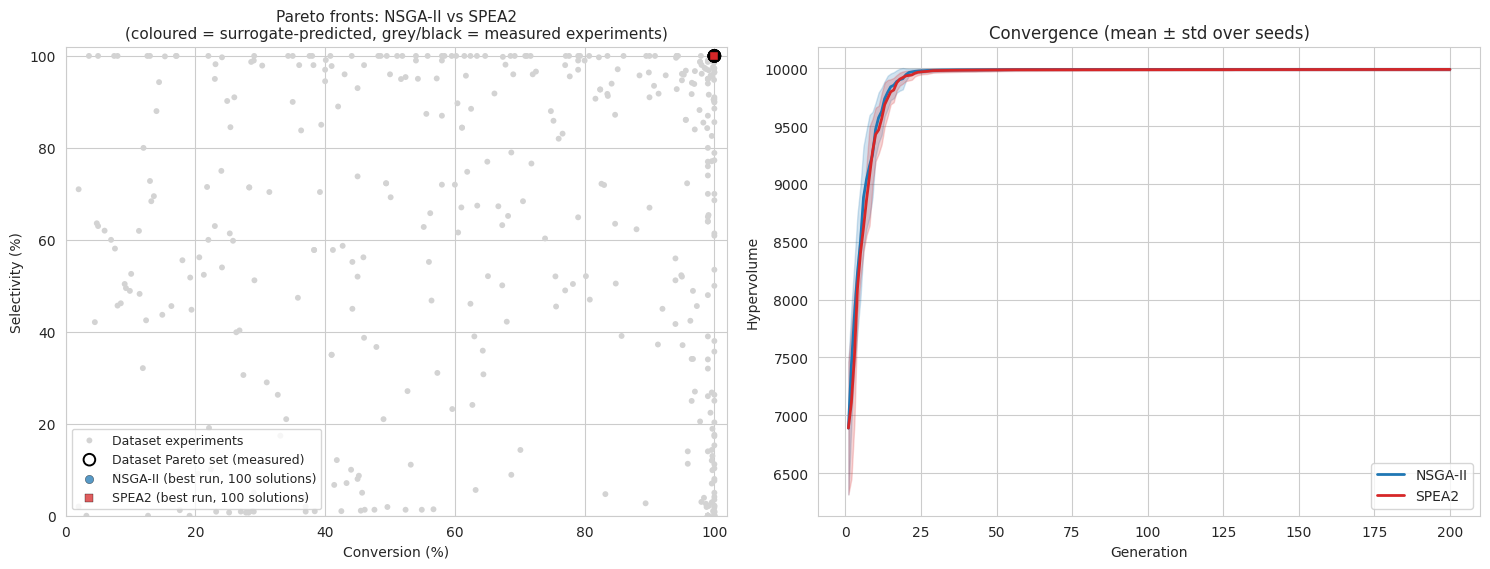

In [93]:
algo_colors = {'NSGA-II': 'tab:blue', 'SPEA2': 'tab:red'}
algo_marker = {'NSGA-II': 'o', 'SPEA2': 's'}

# the dataset's own experimental Pareto set (maximise both)
exp_pts = np.column_stack([y_conv_full.values, y_sel_full.values])
exp_nd = NonDominatedSorting().do(-exp_pts, only_non_dominated_front=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
ax = axes[0]
ax.scatter(exp_pts[:, 0], exp_pts[:, 1], s=18, c='lightgray', edgecolor='none', label='Dataset experiments')
ax.scatter(exp_pts[exp_nd, 0], exp_pts[exp_nd, 1], s=70, facecolor='none', edgecolor='k', linewidth=1.4,
           label='Dataset Pareto set (measured)')
for a in moo_results:
    best_run = max(moo_results[a], key=lambda r: hv_ind(r['F']))
    F = best_run['F']
    ax.scatter(-F[:, 0], -F[:, 1], s=36, marker=algo_marker[a], alpha=0.75, color=algo_colors[a],
               edgecolor='k', linewidth=0.3, label=f'{a} (best run, {len(F)} solutions)')
ax.set_xlabel('Conversion (%)'); ax.set_ylabel('Selectivity (%)')
ax.set_title('Pareto fronts: NSGA-II vs SPEA2\n(coloured = surrogate-predicted, grey/black = measured experiments)', fontsize=11)
ax.set_xlim(0, 102); ax.set_ylim(0, 102); ax.legend(loc='lower left', fontsize=9)

ax = axes[1]
for a in moo_results:
    H = np.array([r['hv_hist'] for r in moo_results[a]])
    g = np.arange(1, H.shape[1] + 1)
    ax.plot(g, H.mean(axis=0), color=algo_colors[a], label=a, lw=2)
    ax.fill_between(g, H.mean(axis=0) - H.std(axis=0), H.mean(axis=0) + H.std(axis=0), color=algo_colors[a], alpha=0.2)
ax.set_xlabel('Generation'); ax.set_ylabel('Hypervolume'); ax.set_title('Convergence (mean ± std over seeds)')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "moo_pareto_and_convergence.png"), dpi=200, bbox_inches='tight')
plt.show()

if EXTRA_OBJECTIVE is not None:
    print(f"Note: 3-objective run (extra objective = minimise {EXTRA_OBJECTIVE}); the left plot is the "
          "Conversion/Selectivity projection of the 3-D front, so points can look 'dominated' there.")

## 57.8 The Pareto-optimal conditions — decoded into real, readable experiments
Fronts from every run of both algorithms are pooled, de-duplicated and re-filtered to a single non-dominated
set. Each solution is decoded back into the catalyst name, reaction medium and process conditions. Also marked:
- **Max-Conversion**, **Max-Selectivity** extremes, and the **Compromise (knee)** solution — the point closest
  to the ideal corner after min-max normalising the objectives.

In [94]:
X_pool = np.vstack([r['X'] for a in moo_results for r in moo_results[a]])
F_pool = np.vstack([r['F'] for a in moo_results for r in moo_results[a]])

# de-duplicate on the *decoded* design (catalog index is floored, so near-identical genomes collapse)
ci_pool, mi_pool = decode_indices(X_pool)
key = np.column_stack([np.round(X_pool[:, :len(CONT_VARS)], 4), ci_pool, mi_pool])
_, uniq = np.unique(key, axis=0, return_index=True)
X_pool, F_pool = X_pool[np.sort(uniq)], F_pool[np.sort(uniq)]

nd = NonDominatedSorting().do(F_pool, only_non_dominated_front=True)
X_pf, F_pf = X_pool[nd], F_pool[nd]

pf_df = decode_population(X_pf)
ci_pf, mi_pf = decode_indices(X_pf)

pareto_table = pd.DataFrame({
    '_src': np.arange(len(X_pf)),                      # temp link back to pf_df / X_pf rows
    'Catalyst system':  cat_catalog['label'].to_numpy()[ci_pf],
    'Reaction medium':  med_catalog['label'].to_numpy()[mi_pf],
})
for c in CONT_VARS:
    pareto_table[c] = pf_df[c].to_numpy()
pareto_table['Pred_Conversion'] = -F_pf[:, 0]
pareto_table['Pred_Selectivity'] = -F_pf[:, 1]
if EXTRA_OBJECTIVE is not None:
    pareto_table[f'Obj_{EXTRA_OBJECTIVE}'] = F_pf[:, 2]
pareto_table = pareto_table.sort_values('Pred_Conversion', ascending=False).reset_index(drop=True)

# --- extremes + knee (compromise) solution ---
Fp = np.column_stack([-pareto_table['Pred_Conversion'], -pareto_table['Pred_Selectivity']] +
                     ([pareto_table[f'Obj_{EXTRA_OBJECTIVE}']] if EXTRA_OBJECTIVE else []))
Fn = (Fp - Fp.min(axis=0)) / np.where((Fp.max(axis=0) - Fp.min(axis=0)) == 0, 1, (Fp.max(axis=0) - Fp.min(axis=0)))
knee_i = int(np.argmin(np.linalg.norm(Fn, axis=1)))
pareto_table['Role'] = ''
pareto_table.loc[pareto_table['Pred_Conversion'].idxmax(),  'Role'] += 'Max-Conversion '
pareto_table.loc[pareto_table['Pred_Selectivity'].idxmax(), 'Role'] += 'Max-Selectivity '
pareto_table.loc[knee_i, 'Role'] += 'Compromise(knee)'

pareto_src_order = pareto_table['_src'].to_numpy()          # table row i  <->  pf_df / X_pf row pareto_src_order[i]
pareto_table = pareto_table.drop(columns='_src')

print(f"Final pooled Pareto set: {len(pareto_table)} distinct non-dominated solutions\n")
pd.set_option('display.width', 250)
display(pareto_table.round(3).head(25))

Final pooled Pareto set: 400 distinct non-dominated solutions



,Catalyst system,Reaction medium,reaction_temperature_C,reaction_pressure_MPa,reaction_time_h,FFR_loading_g,Catalyst_loading_g,Solvent_volume_ml,Reactive_metal_1_Loading_wt,Reactive_metal_2_Loading_wt,Pred_Conversion,Pred_Selectivity,Role
0,CuNi/MgAlO,methanol | H2 source: H2,150,5.184,3.126,0.026,0.065,26.792,46.643,29.119,100.0,100.0,Max-Conversion Max-Selectivity Compromise(knee)
1,CuNi/MgAlO,methanol | H2 source: H2,149,4.944,3.136,0.462,0.046,40.330,47.043,24.994,100.0,100.0,
2,CuNi/MgAlO,methanol | H2 source: H2,152,4.767,2.961,0.121,0.048,24.821,46.660,25.616,100.0,100.0,
3,CuNi/MgAlO,methanol | H2 source: H2,152,4.717,3.188,0.403,0.047,41.390,46.236,26.420,100.0,100.0,
4,CuNi/MgAlO,methanol | H2 source: H2,150,4.860,3.184,0.026,0.047,25.972,43.156,29.501,100.0,100.0,
5,CuNi/MgAlO,methanol | H2 source: H2,154,4.778,3.085,0.141,0.045,45.414,46.693,27.535,100.0,100.0,
6,CuNi/MgAlO,methanol | H2 source: H2,152,4.925,3.130,0.026,0.065,31.965,43.198,29.192,100.0,100.0,
7,CuNi/MgAlO,methanol | H2 source: H2,150,4.946,3.133,0.324,0.050,24.905,43.270,29.484,100.0,100.0,
8,CuNi/MgAlO,methanol | H2 source: H2,152,5.386,3.130,0.022,0.048,41.416,45.908,29.639,100.0,100.0,
9,CuNi/MgAlO,methanol | H2 source: H2,152,4.705,3.030,0.403,0.047,41.766,43.796,30.824,100.0,100.0,


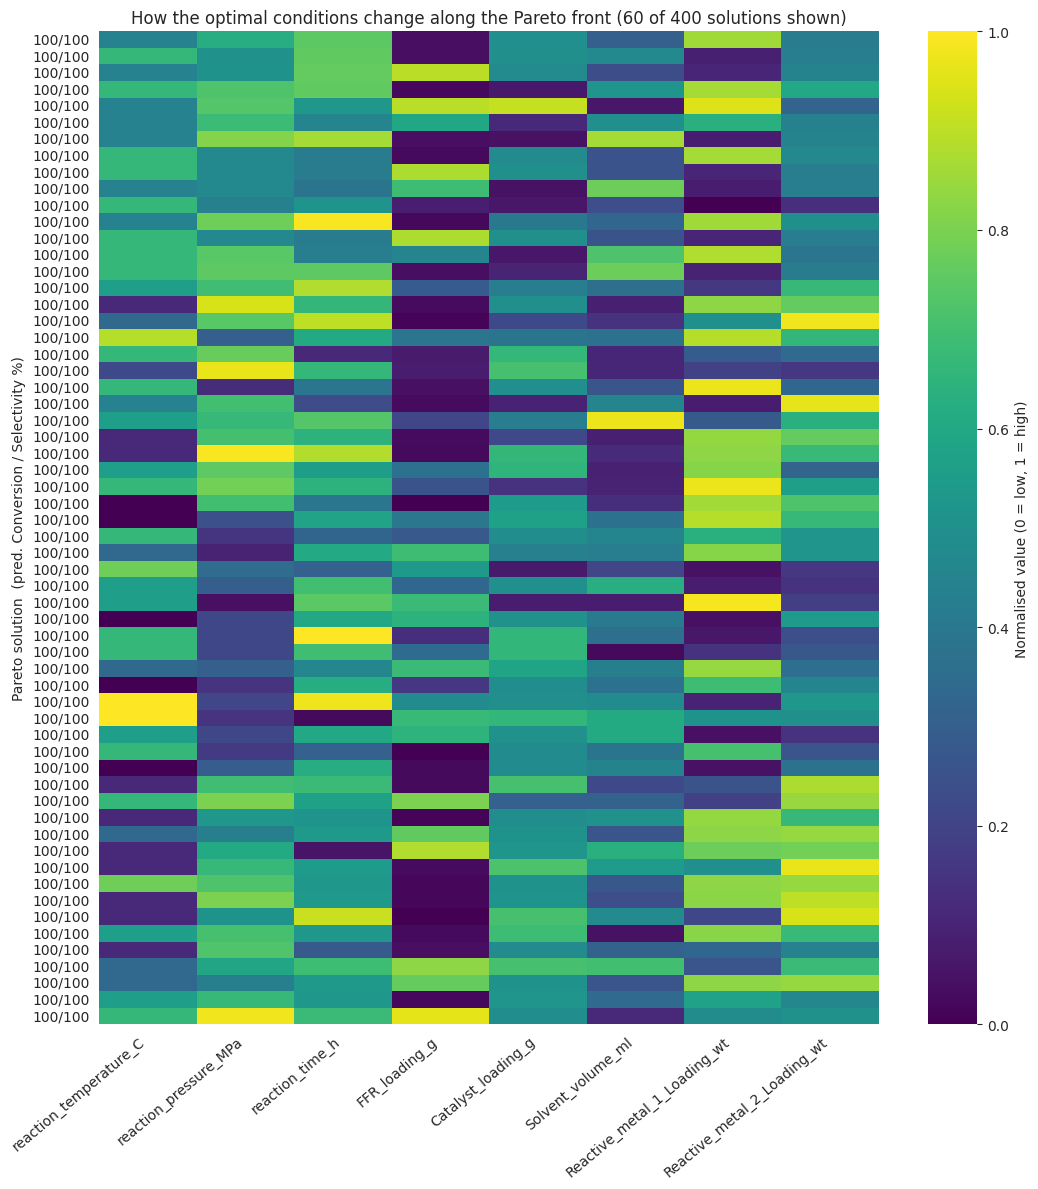

Catalyst systems appearing on the Pareto front:
Catalyst system
CuNi/MgAlO    400

Reaction media appearing on the Pareto front:
Reaction medium
methanol | H2 source: H2    400


In [95]:
# Decision-variable heatmap along the front (rows sorted from max-conversion -> max-selectivity).
# If the front is large, show ~60 evenly spaced solutions so the figure stays readable.
show_idx = np.arange(len(pareto_table)) if len(pareto_table) <= 60 else np.linspace(0, len(pareto_table) - 1, 60).astype(int)
dv = pareto_table.loc[show_idx, CONT_VARS]
dv_norm = (dv - pareto_table[CONT_VARS].min()) / (pareto_table[CONT_VARS].max() - pareto_table[CONT_VARS].min()).replace(0, 1)
fig, ax = plt.subplots(figsize=(11, min(12, max(4, 0.22 * len(dv_norm) + 2))))
sns.heatmap(dv_norm.values, cmap='viridis', ax=ax, cbar_kws={'label': 'Normalised value (0 = low, 1 = high)'},
            xticklabels=CONT_VARS,
            yticklabels=[f"{c:.0f}/{s:.0f}" for c, s in zip(pareto_table.loc[show_idx, 'Pred_Conversion'],
                                                          pareto_table.loc[show_idx, 'Pred_Selectivity'])])
ax.set_ylabel('Pareto solution  (pred. Conversion / Selectivity %)')
ax.set_title(f'How the optimal conditions change along the Pareto front ({len(show_idx)} of {len(pareto_table)} solutions shown)')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "moo_pareto_decision_heatmap.png"), dpi=200, bbox_inches='tight')
plt.show()

# Which catalyst systems / media does the optimiser keep choosing?
print("Catalyst systems appearing on the Pareto front:")
print(pareto_table['Catalyst system'].value_counts().head(10).to_string())
print("\nReaction media appearing on the Pareto front:")
print(pareto_table['Reaction medium'].value_counts().head(10).to_string())

## 57.9 How much should the optimiser be trusted? Two honesty checks
An optimiser is *very* good at finding the spots where a surrogate model happens to be wrong
(it "exploits" model error), and the surrogates here have R2 of roughly 0.55-0.75. So before quoting
any predicted optimum, check it two ways:

1. **Independent-model cross-check** — re-predict every Pareto solution with a *different* trained model.
   If two decent models disagree strongly about a solution, that solution is not credible.
2. **Applicability domain** — how far is each solution from the nearest real training experiment (standardised
   feature space)? Solutions farther than 95 % of real experiments are from each other are flagged as extrapolation.

Treat the Pareto set as a **shortlist of hypotheses to test in the lab**, not as confirmed results.

Primary (CatBoost/Mega Stacked) vs cross-check (CAT-Optuna/CatBoost):
  mean |Δ Conversion|  = 0.68 points   (max 2.57)
  mean |Δ Selectivity| = 1.34 points   (max 11.65)
Applicability domain: 0% of Pareto solutions lie farther from the nearest real experiment than 95% of real experiments do (threshold = 3.39).

Shortlist passing both checks: 399 of 400 solutions


,Catalyst system,Reaction medium,reaction_temperature_C,reaction_pressure_MPa,reaction_time_h,FFR_loading_g,Catalyst_loading_g,Solvent_volume_ml,Reactive_metal_1_Loading_wt,Reactive_metal_2_Loading_wt,Pred_Conversion,Pred_Selectivity,Role,Alt_Conversion,Alt_Selectivity,|Δ Conversion|,|Δ Selectivity|,NN_distance,Extrapolating
0,CuNi/MgAlO,methanol | H2 source: H2,150,5.184,3.126,0.026,0.065,26.792,46.643,29.119,100.0,100.0,Max-Conversion Max-Selectivity Compromise(knee),99.222,98.056,0.778,1.944,2.176,False
1,CuNi/MgAlO,methanol | H2 source: H2,149,4.944,3.136,0.462,0.046,40.330,47.043,24.994,100.0,100.0,,100.000,100.000,0.000,0.000,2.066,False
2,CuNi/MgAlO,methanol | H2 source: H2,152,4.767,2.961,0.121,0.048,24.821,46.660,25.616,100.0,100.0,,99.818,98.462,0.182,1.538,1.960,False
3,CuNi/MgAlO,methanol | H2 source: H2,152,4.717,3.188,0.403,0.047,41.390,46.236,26.420,100.0,100.0,,100.000,100.000,0.000,0.000,1.974,False
4,CuNi/MgAlO,methanol | H2 source: H2,150,4.860,3.184,0.026,0.047,25.972,43.156,29.501,100.0,100.0,,99.190,97.744,0.810,2.256,1.832,False
5,CuNi/MgAlO,methanol | H2 source: H2,154,4.778,3.085,0.141,0.045,45.414,46.693,27.535,100.0,100.0,,100.000,99.600,0.000,0.400,2.075,False
6,CuNi/MgAlO,methanol | H2 source: H2,152,4.925,3.130,0.026,0.065,31.965,43.198,29.192,100.0,100.0,,99.222,98.056,0.778,1.944,1.849,False
7,CuNi/MgAlO,methanol | H2 source: H2,150,4.946,3.133,0.324,0.050,24.905,43.270,29.484,100.0,100.0,,100.000,100.000,0.000,0.000,1.861,False
8,CuNi/MgAlO,methanol | H2 source: H2,152,5.386,3.130,0.022,0.048,41.416,45.908,29.639,100.0,100.0,,99.796,97.759,0.204,2.241,2.247,False
9,CuNi/MgAlO,methanol | H2 source: H2,152,4.705,3.030,0.403,0.047,41.766,43.796,30.824,100.0,100.0,,100.000,100.000,0.000,0.000,1.970,False


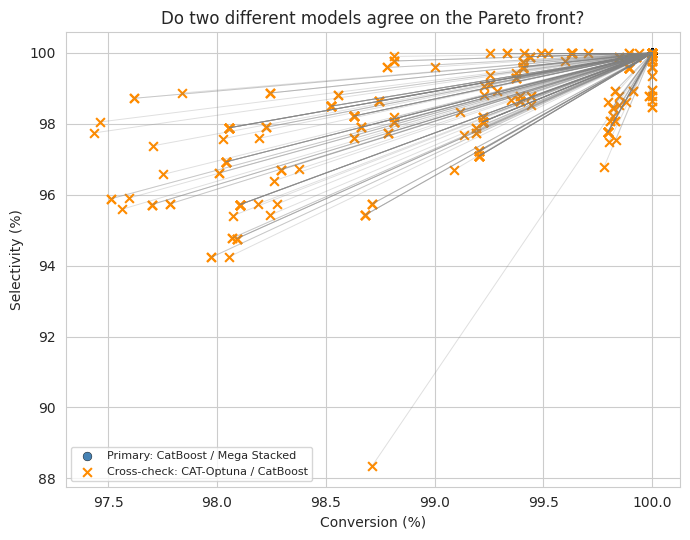

In [96]:
# 1) independent cross-check
alt_c = np.clip(np.asarray(alt_conv.predict(pf_df)).ravel(), 0, 100)
alt_s = np.clip(np.asarray(alt_sel.predict(pf_df)).ravel(),  0, 100)
sorted_idx = pareto_src_order                               # row order of the (sorted) table -> rows of pf_df
alt_c_sorted, alt_s_sorted = alt_c[sorted_idx], alt_s[sorted_idx]
pareto_table['Alt_Conversion'] = alt_c_sorted
pareto_table['Alt_Selectivity'] = alt_s_sorted
pareto_table['|Δ Conversion|'] = (pareto_table['Pred_Conversion'] - pareto_table['Alt_Conversion']).abs()
pareto_table['|Δ Selectivity|'] = (pareto_table['Pred_Selectivity'] - pareto_table['Alt_Selectivity']).abs()

# 2) applicability domain (distance to nearest real experiment)
Xs_full = scaler_nn.transform(X_full_reduced)
nn = NearestNeighbors(n_neighbors=2).fit(Xs_full)
self_d = nn.kneighbors(Xs_full)[0][:, 1]                    # distance to nearest *other* real experiment
ad_threshold = np.percentile(self_d, 95)
pf_scaled = scaler_nn.transform(pf_df.iloc[sorted_idx].reset_index(drop=True))
pareto_table['NN_distance'] = nn.kneighbors(pf_scaled, n_neighbors=1)[0].ravel()
pareto_table['Extrapolating'] = pareto_table['NN_distance'] > ad_threshold

print(f"Primary ({surr_conv_name}/{surr_sel_name}) vs cross-check ({alt_conv_name}/{alt_sel_name}):")
print(f"  mean |Δ Conversion|  = {pareto_table['|Δ Conversion|'].mean():.2f} points   (max {pareto_table['|Δ Conversion|'].max():.2f})")
print(f"  mean |Δ Selectivity| = {pareto_table['|Δ Selectivity|'].mean():.2f} points   (max {pareto_table['|Δ Selectivity|'].max():.2f})")
print(f"Applicability domain: {pareto_table['Extrapolating'].mean()*100:.0f}% of Pareto solutions lie farther from the nearest "
      f"real experiment than 95% of real experiments do (threshold = {ad_threshold:.2f}).")

# "More trustworthy" shortlist: models agree within 10 points on both targets AND not extrapolating
trusted = pareto_table[(pareto_table['|Δ Conversion|'] < 10) & (pareto_table['|Δ Selectivity|'] < 10) & (~pareto_table['Extrapolating'])]
print(f"\nShortlist passing both checks: {len(trusted)} of {len(pareto_table)} solutions")
display(trusted.round(3).head(15))

# plot: primary vs cross-check predictions on the front
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(pareto_table['Pred_Conversion'], pareto_table['Pred_Selectivity'], s=40, color='steelblue', edgecolor='k',
           linewidth=0.3, label=f'Primary: {surr_conv_name} / {surr_sel_name}')
ax.scatter(pareto_table['Alt_Conversion'], pareto_table['Alt_Selectivity'], s=40, marker='x', color='darkorange',
           label=f'Cross-check: {alt_conv_name} / {alt_sel_name}')
for i in range(len(pareto_table)):
    ax.plot([pareto_table['Pred_Conversion'][i], pareto_table['Alt_Conversion'][i]],
            [pareto_table['Pred_Selectivity'][i], pareto_table['Alt_Selectivity'][i]], color='gray', alpha=0.25, lw=0.7)
ax.set_xlabel('Conversion (%)'); ax.set_ylabel('Selectivity (%)')
ax.set_title('Do two different models agree on the Pareto front?'); ax.legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "moo_crosscheck.png"), dpi=200, bbox_inches='tight')
plt.show()

## 57.10 Optimiser vs the best real experiment in the dataset
A reality check on the headline claim: how do the optimiser's extreme and compromise solutions compare with the
best conversion / selectivity actually measured?

In [97]:
best_exp_conv_i = int(np.argmax(exp_pts[:, 0]))
best_exp_sel_i  = int(np.argmax(exp_pts[:, 1]))
best_exp_sum_i  = int(np.argmax(exp_pts.sum(axis=1)))
knee_row = pareto_table[pareto_table['Role'].str.contains('Compromise')].iloc[0]

compare = pd.DataFrame([
    {'Source': 'Dataset: highest Conversion',   'Conversion': exp_pts[best_exp_conv_i, 0], 'Selectivity': exp_pts[best_exp_conv_i, 1]},
    {'Source': 'Dataset: highest Selectivity',   'Conversion': exp_pts[best_exp_sel_i, 0],  'Selectivity': exp_pts[best_exp_sel_i, 1]},
    {'Source': 'Dataset: best Conv + Sel (sum)', 'Conversion': exp_pts[best_exp_sum_i, 0],  'Selectivity': exp_pts[best_exp_sum_i, 1]},
    {'Source': 'MOO (predicted): max Conversion',   'Conversion': pareto_table['Pred_Conversion'].max(),  'Selectivity': pareto_table.loc[pareto_table['Pred_Conversion'].idxmax(), 'Pred_Selectivity']},
    {'Source': 'MOO (predicted): max Selectivity',  'Conversion': pareto_table.loc[pareto_table['Pred_Selectivity'].idxmax(), 'Pred_Conversion'], 'Selectivity': pareto_table['Pred_Selectivity'].max()},
    {'Source': 'MOO (predicted): compromise knee',  'Conversion': knee_row['Pred_Conversion'], 'Selectivity': knee_row['Pred_Selectivity']},
]).round(2)
display(compare)

print("\nCompromise (knee) solution in detail:")
display(knee_row.drop(labels=['Role']).to_frame('value'))

,Source,Conversion,Selectivity
0,Dataset: highest Conversion,100.0,26.3
1,Dataset: highest Selectivity,77.6,100.0
2,Dataset: best Conv + Sel (sum),100.0,100.0
3,MOO (predicted): max Conversion,100.0,100.0
4,MOO (predicted): max Selectivity,100.0,100.0
5,MOO (predicted): compromise knee,100.0,100.0



Compromise (knee) solution in detail:


,value
Catalyst system,CuNi/MgAlO
Reaction medium,methanol | H2 source: H2
reaction_temperature_C,150
reaction_pressure_MPa,5.183982
reaction_time_h,3.125831
FFR_loading_g,0.025984
Catalyst_loading_g,0.064544
Solvent_volume_ml,26.791765
Reactive_metal_1_Loading_wt,46.643021
Reactive_metal_2_Loading_wt,29.119414


## 57.11 Save results & auto-download

In [98]:
pareto_path_xlsx = os.path.join(MODEL_DIR, "moo_pareto_solutions.xlsx")
pareto_path_csv  = os.path.join(MODEL_DIR, "moo_pareto_solutions.csv")
with pd.ExcelWriter(pareto_path_xlsx) as writer:
    pareto_table.to_excel(writer, sheet_name='Pareto solutions', index=False)
    trusted.to_excel(writer, sheet_name='Passed both checks', index=False)
    moo_metrics.to_excel(writer, sheet_name='Algorithm comparison')
    compare.to_excel(writer, sheet_name='vs dataset best', index=False)
    bounds_df.to_excel(writer, sheet_name='Variable bounds')
pareto_table.to_csv(pareto_path_csv, index=False)
moo_metrics.to_csv(os.path.join(MODEL_DIR, "moo_algorithm_comparison.csv"))
print("Saved:", pareto_path_xlsx)

try:
    from google.colab import files
    to_download = [pareto_path_xlsx, pareto_path_csv, os.path.join(MODEL_DIR, "moo_algorithm_comparison.csv")] + \
                  [os.path.join(FIGURE_DIR, f) for f in
                   ["moo_pareto_and_convergence.png", "moo_pareto_decision_heatmap.png", "moo_crosscheck.png"]]
    for fpath in to_download:
        if os.path.exists(fpath):
            files.download(fpath)
    print(f"Triggered browser download for {len(to_download)} files.")
except ImportError:
    print("Not running in Colab — skipping auto-download. Files are saved in", MODEL_DIR, "and", FIGURE_DIR)

Saved: /content/drive/MyDrive/BTP_Sem_7/saved_models/moo_pareto_solutions.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggered browser download for 6 files.


---
# 58. Multi-objective optimisation on the SHAP-selected features (mean |SHAP| > 1)

Sections 1-57 are untouched. Section 57 optimised over a hand-picked set of process variables. This section lets
**the SHAP analysis (section 54) decide what the optimiser is allowed to tune**:

1. **Select** every feature whose mean |SHAP value| is **greater than 1** (in target units, i.e. more than one
   percentage point of average influence on the prediction) for Conversion *and* for Selectivity.
2. **Map engineered features back to real variables.** The SHAP model (`CatBoost+v2features`) also uses derived columns such as
   `Calcination_temperature_C_x_reaction_temperature_C` (product), `FFR_loading_g_div_Catalyst_loading_g` (ratio) or
   `Solvent_density_g_mL_log1p`. The optimiser can only *set* real variables, so each derived feature is traced back to the
   raw variable(s) it was built from, and those become the decision variables. The derived columns are then **re-computed
   automatically** for every candidate, exactly the way they were built for training.
3. **Optimise the very model SHAP explained** (same trained model, same feature space), so "important in SHAP" and
   "optimised by NSGA-II / SPEA2" refer to the same thing.
4. **Everything not selected by SHAP is held fixed** at the values of one real reference experiment (default: the best
   measured experiment), so the optimiser searches only the dimensions that actually move the predictions.

**Objectives (all handled by NSGA-II and SPEA2 as before):** maximise Conversion, maximise Selectivity and — by default —
**minimise reaction temperature** (an energy/safety cost). Why a third objective? In section 57 the surrogate said
100 % conversion *and* 100 % selectivity are reachable together (and the dataset itself contains such an experiment), so the
two objectives did not conflict and the "front" collapsed to one point. Adding a genuine cost objective restores a real
trade-off: *how much performance do we give up for a milder process?* Set `SHAP_EXTRA_OBJECTIVE = None` to go back to two objectives.

> **Interpretation caveat.** SHAP-selected descriptors such as solvent dipole moment or metal d-band filling are treated as
> continuous "virtual material properties". The results table therefore also shows the **nearest real experiment** for each
> optimum, so you can say which real catalyst / solvent it resembles.

## 58.1 Imports & configuration

In [99]:
!pip install -q pymoo

import re, time, zlib
from pymoo.core.problem import Problem
from pymoo.core.callback import Callback
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.spea2 import SPEA2
from pymoo.optimize import minimize
from pymoo.indicators.hv import HV
from pymoo.indicators.igd_plus import IGDPlus
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# ----------------------------- configuration -----------------------------
SHAP_THRESHOLD   = 1.0          # keep features with mean |SHAP| strictly greater than this
SHAP_POP         = 100          # population size
SHAP_GEN         = 200          # generations per run
SHAP_SEEDS       = 5            # independent runs per algorithm
SHAP_BASE_SEED   = 42
SHAP_BOUND_PCT   = (1, 99)      # variable bounds = these percentiles of the observed data
SHAP_BOUND_OVERRIDES = {}       # e.g. {'Reactive_metal_1_Loading_wt': (0.5, 20)}  -> cap unrealistic loadings
SHAP_EXCLUDE     = []           # SHAP-selected variables you still want to freeze at the reference value

# 3rd objective (MINIMISED):  None | 'temperature' | 'catalyst_loading' | 'metal_loading'
SHAP_EXTRA_OBJECTIVE = 'temperature'
_EXTRA_COLUMN = {'temperature': 'reaction_temperature_C',
                 'catalyst_loading': 'Catalyst_loading_g',
                 'metal_loading': 'Reactive_metal_1_Loading_wt'}

# Reference experiment that all NON-selected features are frozen at:
#   'best_experiment' = measured experiment with highest Conversion + Selectivity | 'medoid' = most "typical" experiment
SHAP_CONTEXT_MODE = 'best_experiment'
SHAP_CONTEXT_ROW  = None        # or an index label of X_full_reduced to force a specific experiment

print(f"SHAP threshold: mean|SHAP| > {SHAP_THRESHOLD} | extra objective: {SHAP_EXTRA_OBJECTIVE} | context: {SHAP_CONTEXT_MODE}")

SHAP threshold: mean|SHAP| > 1.0 | extra objective: temperature | context: best_experiment


## 58.2 Pull out every SHAP feature with mean |SHAP| > 1 and trace it back to real variables
Mean |SHAP| is computed from the same SHAP values used for the bar charts in section 54.2
(`sv_conv`, `sv_sel`, test set). Derived features are traced back with their naming pattern:
`A_x_B` (product), `A_div_B` (ratio), `A_sq` (square), `A_log1p` (log transform) → raw variable(s) `A` (and `B`).

In [100]:
base_cols = list(X_train_reduced.columns)

def base_of(feat):
    # Raw variable(s) a (possibly engineered) SHAP feature was built from.
    if feat in base_cols:
        return [feat]
    for suf in ('_log1p', '_sq'):
        if feat.endswith(suf) and feat[:-len(suf)] in base_cols:
            return [feat[:-len(suf)]]
    for sep in ('_x_', '_div_'):
        if sep in feat:
            for a in base_cols:
                if feat.startswith(a + sep) and feat[len(a) + len(sep):] in base_cols:
                    return [a, feat[len(a) + len(sep):]]
    return []

def feat_type(f):
    if f in base_cols: return 'raw'
    if f.endswith('_log1p'): return 'log1p'
    if f.endswith('_sq'): return 'square'
    if '_x_' in f: return 'product'
    if '_div_' in f: return 'ratio'
    return 'other'

def mean_abs_shap(sv, X_df):
    return pd.Series(np.abs(sv.values).mean(axis=0), index=X_df.columns).sort_values(ascending=False)

ma_conv = mean_abs_shap(sv_conv, X_test_shap_conv)
ma_sel  = mean_abs_shap(sv_sel,  X_test_shap_sel)

rows, base_score = [], {}
for tname, ser in [('Conversion', ma_conv), ('Selectivity', ma_sel)]:
    for f, v in ser[ser > SHAP_THRESHOLD].items():
        b = base_of(f)
        if not b:
            print(f"  [warning] could not trace '{f}' back to raw variables - skipped")
            continue
        rows.append({'Target': tname, 'SHAP feature': f, 'mean|SHAP|': round(float(v), 3),
                     'Type': feat_type(f), 'Raw variable(s)': ' , '.join(b)})
        for bv in b:
            base_score[bv] = max(base_score.get(bv, 0.0), float(v))

shap_feature_table = pd.DataFrame(rows)
print(f"Features with mean|SHAP| > {SHAP_THRESHOLD}:  Conversion = {(ma_conv > SHAP_THRESHOLD).sum()}   Selectivity = {(ma_sel > SHAP_THRESHOLD).sum()}")
display(shap_feature_table)

# decision variables = the raw variables behind those features (binary/one-hot ones cannot be tuned continuously)
S_VARS, frozen_binary = [], []
for bv in sorted(base_score, key=base_score.get, reverse=True):
    if bv in SHAP_EXCLUDE:
        continue
    if X_full_reduced[bv].nunique() <= 2:
        frozen_binary.append(bv); continue
    S_VARS.append(bv)
assert len(S_VARS) > 0, "No SHAP feature exceeded the threshold - lower SHAP_THRESHOLD."
if frozen_binary:
    print("\nSHAP-selected but categorical (0/1) -> held fixed at the reference experiment:", frozen_binary)
print(f"\n{len(S_VARS)} decision variables for the optimiser (ordered by SHAP importance):")
for v in S_VARS:
    print(f"  {v:45s} max mean|SHAP| of a feature built from it = {base_score[v]:.2f}")

Features with mean|SHAP| > 1.0:  Conversion = 7   Selectivity = 13


,Target,SHAP feature,mean|SHAP|,Type,Raw variable(s)
0,Conversion,reaction_time_h,4.592,raw,reaction_time_h
1,Conversion,Calcination_temperature_C_x_reaction_temperatu...,2.187,product,"Calcination_temperature_C , reaction_temperatu..."
2,Conversion,reaction_pressure_MPa,2.010,raw,reaction_pressure_MPa
3,Conversion,Reducing_temperature_C,1.827,raw,Reducing_temperature_C
4,Conversion,Calcination_temperature_C_div_reaction_tempera...,1.625,ratio,"Calcination_temperature_C , reaction_temperatu..."
5,Conversion,Surface_Area_m2_g,1.499,raw,Surface_Area_m2_g
6,Conversion,FFR_loading_g_div_Catalyst_loading_g,1.198,ratio,"FFR_loading_g , Catalyst_loading_g"
7,Selectivity,reaction_temperature_C,4.376,raw,reaction_temperature_C
8,Selectivity,Solvent_dipole_moment_D,2.437,raw,Solvent_dipole_moment_D
9,Selectivity,Surface_Area_m2_g,2.129,raw,Surface_Area_m2_g



14 decision variables for the optimiser (ordered by SHAP importance):
  reaction_time_h                               max mean|SHAP| of a feature built from it = 4.59
  reaction_temperature_C                        max mean|SHAP| of a feature built from it = 4.38
  Solvent_dipole_moment_D                       max mean|SHAP| of a feature built from it = 2.44
  Calcination_temperature_C                     max mean|SHAP| of a feature built from it = 2.19
  Surface_Area_m2_g                             max mean|SHAP| of a feature built from it = 2.13
  Solvent_density_g_mL                          max mean|SHAP| of a feature built from it = 2.05
  reaction_pressure_MPa                         max mean|SHAP| of a feature built from it = 2.01
  Reducing_temperature_C                        max mean|SHAP| of a feature built from it = 1.83
  Reactive_metal_1_d_band_filling               max mean|SHAP| of a feature built from it = 1.49
  Reactive_metal_1_Loading_wt                   max mean

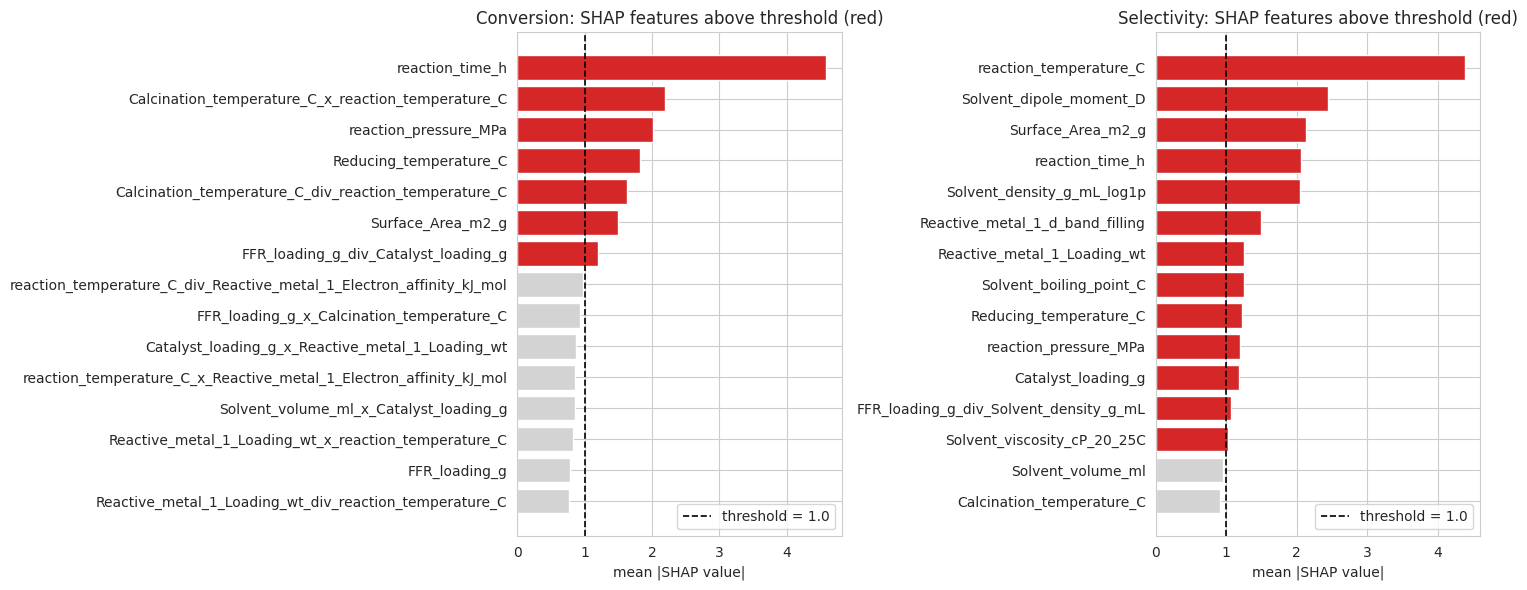

In [101]:
# Visual: which features cleared the threshold
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, ser, tname in [(axes[0], ma_conv, 'Conversion'), (axes[1], ma_sel, 'Selectivity')]:
    top = ser.head(15)[::-1]
    ax.barh(top.index, top.values, color=['tab:red' if v > SHAP_THRESHOLD else 'lightgray' for v in top.values])
    ax.axvline(SHAP_THRESHOLD, color='k', ls='--', lw=1.2, label=f'threshold = {SHAP_THRESHOLD}')
    ax.set_xlabel('mean |SHAP value|'); ax.set_title(f'{tname}: SHAP features above threshold (red)')
    ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "moo_shap_selected_features.png"), dpi=200, bbox_inches='tight')
plt.show()

## 58.3 Search space: bounds for the SHAP variables + the frozen reference experiment
Bounds are the 1st-99th percentile of each variable in the dataset (override any of them with `SHAP_BOUND_OVERRIDES`,
e.g. to cap a metal loading at a realistic value). Every other feature is copied from one real **reference experiment**.

In [102]:
lo_hi_s = {}
for c in S_VARS:
    col = X_full_reduced[c].astype(float)
    if 'Loading_wt' in c:
        col = col[col > 0]
    lo, hi = np.percentile(col, SHAP_BOUND_PCT)
    if c in SHAP_BOUND_OVERRIDES:
        lo, hi = SHAP_BOUND_OVERRIDES[c]
    if hi <= lo:
        hi = lo + 1e-6
    lo_hi_s[c] = (float(lo), float(hi))
bounds_s = pd.DataFrame(lo_hi_s, index=['lower', 'upper']).T

# ---- reference experiment (everything NOT chosen by SHAP is frozen at its values) ----
Z_full = scaler_nn.transform(X_full_reduced)
if SHAP_CONTEXT_ROW is not None:
    ctx_idx = SHAP_CONTEXT_ROW
elif SHAP_CONTEXT_MODE == 'medoid':
    ctx_idx = X_full_reduced.index[int(np.argmin(np.linalg.norm(Z_full - np.median(Z_full, axis=0), axis=1)))]
else:
    ctx_idx = (y_conv_full.reindex(X_full_reduced.index) + y_sel_full.reindex(X_full_reduced.index)).idxmax()
context_row = X_full_reduced.loc[ctx_idx]

def exp_label(idx):
    try:
        r = df_clean.loc[idx]
        return f"{r['Catalyst type']} | {r['Solvent type']} | H2 source: {r['H2 source']}"
    except Exception:
        return f"experiment@row{idx}"

print(f"Reference experiment (index {ctx_idx}): {exp_label(ctx_idx)}")
print(f"  measured Conversion = {y_conv_full.loc[ctx_idx]:.1f} %, Selectivity = {y_sel_full.loc[ctx_idx]:.1f} %")
print(f"  -> {len(base_cols) - len(S_VARS)} of {len(base_cols)} features are frozen at this experiment's values\n")
display(bounds_s.assign(reference_value=[float(context_row[c]) for c in S_VARS]))

Reference experiment (index 204): Ni/AC | isopropanol | H2 source: H2
  measured Conversion = 100.0 %, Selectivity = 100.0 %
  -> 21 of 35 features are frozen at this experiment's values



,lower,upper,reference_value
reaction_time_h,0.333333,12.0000,8.000000
reaction_temperature_C,30.000000,187.5000,60.000000
Solvent_dipole_moment_D,0.000000,1.8500,1.660000
Calcination_temperature_C,0.000000,600.0000,0.000000
Surface_Area_m2_g,7.000000,1340.0000,519.000000
Solvent_density_g_mL,0.667000,1.0330,0.785000
reaction_pressure_MPa,0.100000,6.0000,4.000000
Reducing_temperature_C,0.000000,675.0000,0.000000
Reactive_metal_1_d_band_filling,0.700000,1.0000,0.800000
Reactive_metal_1_Loading_wt,0.190000,50.3900,14.780000


## 58.4 Bridge from decision variables to the SHAP model's feature space
`to_shap_space` rebuilds the engineered columns (products, ratios, squares, log1p) with the **same functions used in
sections 53-54** (`add_interactions`, `add_engineered_v2`), so a candidate described only by raw variables can be fed to
`CatBoost+v2features`. A built-in test confirms the rebuilt columns reproduce the SHAP test matrices exactly.

In [103]:
_REDUCED_NAMES = {'RF (grid)', 'XGB (grid)', 'GB (grid)', 'CatBoost', 'ExtraTrees',
                  'XGB-Optuna', 'LGB-Optuna', 'CAT-Optuna', 'XGB (outliers removed)'}

def to_shap_space(df_red, model_name, target):
    # Raw (X_train_reduced-style) candidate frame -> the exact feature matrix the SHAP model was trained on.
    if model_name in _REDUCED_NAMES:
        return df_red
    if model_name == 'CatBoost+v2features':
        if target == 'conv':
            f1, f2, lg, cols = top_conv_feats, top_conv_feats_v2, log1p_feats_conv, list(X_train_fe2_conv.columns)
        else:
            f1, f2, lg, cols = top_sel_feats,  top_sel_feats_v2,  log1p_feats_sel,  list(X_train_fe2_sel.columns)
        return add_engineered_v2(add_interactions(df_red, f1), f2, lg)[cols]
    raise NotImplementedError(f"SHAP model '{model_name}' needs a custom bridge - add a branch in to_shap_space().")

# --- self-test: rebuilt matrix must equal the SHAP test matrix, and predictions must match ---
for tgt, nm, mdl, Xte_s in [('conv', shap_conv_name, shap_conv_model, X_test_shap_conv),
                            ('sel',  shap_sel_name,  shap_sel_model,  X_test_shap_sel)]:
    rebuilt = to_shap_space(X_test_reduced, nm, tgt)
    same_cols = list(rebuilt.columns) == list(Xte_s.columns)
    max_diff = float(np.abs(rebuilt.to_numpy(dtype=float) - Xte_s.to_numpy(dtype=float)).max())
    pred_diff = float(np.abs(np.asarray(mdl.predict(rebuilt)) - np.asarray(mdl.predict(Xte_s))).max())
    print(f"[{tgt}] {nm}: columns match = {same_cols} | max feature diff = {max_diff:.2e} | max prediction diff = {pred_diff:.2e}")
    assert same_cols and max_diff < 1e-6, "Feature rebuild does not match the SHAP matrix - stop and check."
print("Feature-space bridge verified.")

[conv] CatBoost+v2features: columns match = True | max feature diff = 0.00e+00 | max prediction diff = 0.00e+00
[sel] CatBoost+v2features: columns match = True | max feature diff = 0.00e+00 | max prediction diff = 0.00e+00
Feature-space bridge verified.


## 58.5 The optimisation problem
Decision vector = the SHAP-selected raw variables. Objectives (minimised): `-Conversion`, `-Selectivity` and, if enabled, the
extra cost objective. Predictions come from the same models SHAP explained and are clipped to [0, 100] %.

In [104]:
_dtypes_s = X_train_reduced.dtypes.to_dict()
_ctx_vec = context_row.to_numpy(dtype=float)

S_EXTRA = SHAP_EXTRA_OBJECTIVE
if S_EXTRA is not None and _EXTRA_COLUMN[S_EXTRA] not in S_VARS:
    print(f"[warning] '{_EXTRA_COLUMN[S_EXTRA]}' is not among the SHAP-selected variables -> extra objective disabled")
    S_EXTRA = None
S_EXTRA_COL = _EXTRA_COLUMN[S_EXTRA] if S_EXTRA else None

def decode_shap(X):
    # Decision vectors -> full feature rows (reference experiment with the SHAP variables overwritten).
    X = np.atleast_2d(X)
    df = pd.DataFrame(np.tile(_ctx_vec, (X.shape[0], 1)), columns=base_cols)
    for j, c in enumerate(S_VARS):
        df[c] = X[:, j]
    return df.astype(_dtypes_s)

def predict_targets(df_red):
    conv = np.clip(np.asarray(shap_conv_model.predict(to_shap_space(df_red, shap_conv_name, 'conv'))).ravel(), 0, 100)
    sel  = np.clip(np.asarray(shap_sel_model.predict(to_shap_space(df_red,  shap_sel_name,  'sel'))).ravel(),  0, 100)
    return conv, sel

class ShapFFRProblem(Problem):
    def __init__(self):
        xl = np.array([lo_hi_s[c][0] for c in S_VARS]); xu = np.array([lo_hi_s[c][1] for c in S_VARS])
        super().__init__(n_var=len(S_VARS), n_obj=2 + (S_EXTRA is not None), xl=xl, xu=xu)
    def _evaluate(self, X, out, *args, **kwargs):
        df = decode_shap(X)
        conv, sel = predict_targets(df)
        cols = [-conv, -sel]
        if S_EXTRA is not None:
            cols.append(df[S_EXTRA_COL].to_numpy(dtype=float))
        out["F"] = np.column_stack(cols)

# Hypervolume reference = worst case (0 % conv, 0 % sel, highest allowed extra objective).
# "Ideal" volume = 100 x 100 (x range of the extra objective) -> lets us report HV as % of the best possible.
S_HV_REF = np.array([0.0, 0.0] + ([lo_hi_s[S_EXTRA_COL][1]] if S_EXTRA else []))
S_HV_IDEAL = 100.0 * 100.0 * ((lo_hi_s[S_EXTRA_COL][1] - lo_hi_s[S_EXTRA_COL][0]) if S_EXTRA else 1.0)

_p = ShapFFRProblem()
print(f"Problem: {_p.n_var} decision variables, {_p.n_obj} objectives "
      f"({'Conversion, Selectivity' + (', min ' + S_EXTRA_COL if S_EXTRA else '')})")
_demo = _p.xl + np.random.default_rng(0).random((5, _p.n_var)) * (_p.xu - _p.xl)
_o = {}; _p._evaluate(_demo, _o)
print("Smoke test, F for 5 random candidates:\n", np.round(_o['F'], 1))

Problem: 14 decision variables, 3 objectives (Conversion, Selectivity, min reaction_temperature_C)
Smoke test, F for 5 random candidates:
 [[-72.  -59.6  72. ]
 [-45.7 -67.7  57. ]
 [-65.3 -67.2 132. ]
 [-51.8 -74.7  83. ]
 [-48.7 -47.2 155. ]]


## 58.6 Run NSGA-II and SPEA2 (several seeds, cached to Drive)
Same persistence pattern as before: a cached result for the identical configuration (threshold, variable set, objectives,
population, generations, seeds, models) is reloaded instantly; set `FORCE_RETRAIN = True` to rerun.

In [105]:
class S_HVCallback(Callback):
    def __init__(self, ref_point):
        super().__init__()
        self.hv = HV(ref_point=ref_point)
        self.data["hv"] = []
    def notify(self, algorithm):
        self.data["hv"].append(float(self.hv(algorithm.opt.get("F"))))

def make_algorithm_s(name):
    return NSGA2(pop_size=SHAP_POP) if name == 'NSGA-II' else SPEA2(pop_size=SHAP_POP)

def run_shap_moo(algo_name, seed):
    cb = S_HVCallback(S_HV_REF); t0 = time.time()
    res = minimize(ShapFFRProblem(), make_algorithm_s(algo_name), ('n_gen', SHAP_GEN), seed=seed, callback=cb, verbose=False)
    return {'X': np.atleast_2d(res.X), 'F': np.atleast_2d(res.F), 'hv_hist': cb.data['hv'], 'time': time.time() - t0}

_safe = lambda s: re.sub(r'[^A-Za-z0-9]+', '', s)
_vars_hash = zlib.crc32(','.join(S_VARS).encode()) & 0xffffffff
shap_moo_file = (f"moo_shap_results_{_safe(shap_conv_name)}_{_safe(shap_sel_name)}_thr{SHAP_THRESHOLD}_v{_vars_hash:08x}_"
                 f"{S_EXTRA}_ctx{ctx_idx}_p{SHAP_POP}_g{SHAP_GEN}_s{SHAP_SEEDS}.pkl")

shap_moo_results = load_object(shap_moo_file) if not FORCE_RETRAIN else None
if shap_moo_results is not None:
    print(f"Loaded cached results: {shap_moo_file}")
else:
    shap_moo_results = {}
    for algo_name in ['NSGA-II', 'SPEA2']:
        shap_moo_results[algo_name] = []
        for k in range(SHAP_SEEDS):
            r = run_shap_moo(algo_name, SHAP_BASE_SEED + k)
            shap_moo_results[algo_name].append(r)
            print(f"{algo_name:8s} seed {SHAP_BASE_SEED + k}: {len(r['F']):3d} Pareto solutions | "
                  f"final HV = {r['hv_hist'][-1]:.1f} ({100 * r['hv_hist'][-1] / S_HV_IDEAL:.1f}% of ideal) | {r['time']:.1f}s")
    save_object(shap_moo_results, shap_moo_file)
    print(f"Saved to {os.path.join(MODEL_DIR, shap_moo_file)}")

Loaded cached results: moo_shap_results_CatBoostv2features_CatBoostv2features_thr1.0_v8d517720_temperature_ctx204_p100_g200_s5.pkl


## 58.7 Quantitative comparison — hypervolume, IGD+, front size, runtime
Hypervolume is reported both raw and as **% of the ideal volume** (100 % conversion, 100 % selectivity, lowest allowed
value of the cost objective). IGD+ is measured against the best front found by any run of either algorithm
(lower = closer). Differences smaller than the seed-to-seed spread should be read as ties.

In [106]:
S_all_F = np.vstack([r['F'] for a in shap_moo_results for r in shap_moo_results[a]])
S_ref_front = S_all_F[NonDominatedSorting().do(S_all_F, only_non_dominated_front=True)]
_fmin, _fmax = S_ref_front.min(axis=0), S_ref_front.max(axis=0)
_normS = lambda F: (F - _fmin) / np.where((_fmax - _fmin) == 0, 1, (_fmax - _fmin))
_igdS = IGDPlus(_normS(S_ref_front)); _hvS = HV(ref_point=S_HV_REF)

rows = []
for a in shap_moo_results:
    hvs  = [float(_hvS(r['F'])) for r in shap_moo_results[a]]
    igds = [float(_igdS(_normS(r['F']))) for r in shap_moo_results[a]]
    rows.append({'Algorithm': a, 'HV mean': np.mean(hvs), 'HV std': np.std(hvs),
                 'HV % of ideal': 100 * np.mean(hvs) / S_HV_IDEAL,
                 'IGD+ mean': np.mean(igds), 'IGD+ std': np.std(igds),
                 '# Pareto (mean)': np.mean([len(r['F']) for r in shap_moo_results[a]]),
                 'Runtime s (mean)': np.mean([r['time'] for r in shap_moo_results[a]])})
shap_moo_metrics = pd.DataFrame(rows).set_index('Algorithm')
display(shap_moo_metrics.round(4))

print("Higher mean hypervolume :", shap_moo_metrics['HV mean'].idxmax())
print("Lower mean IGD+         :", shap_moo_metrics['IGD+ mean'].idxmin())
if abs(shap_moo_metrics['HV mean'].diff().dropna().iloc[0]) < shap_moo_metrics['HV std'].max():
    print("-> The HV gap is smaller than the seed-to-seed std: the two algorithms perform comparably here.")

,HV mean,HV std,HV % of ideal,IGD+ mean,IGD+ std,# Pareto (mean),Runtime s (mean)
Algorithm,,,,,,,
NSGA-II,1.560358e+06,22896.0133,99.0704,0.1049,0.0711,100.0,19.7952
SPEA2,1.569841e+06,3460.7864,99.6724,0.0579,0.0361,100.0,14.8638


Higher mean hypervolume : SPEA2
Lower mean IGD+         : SPEA2
-> The HV gap is smaller than the seed-to-seed std: the two algorithms perform comparably here.


## 58.8 Pareto-front plots
Left: Conversion vs Selectivity of the best-hypervolume run of each algorithm (colour = the cost objective, grey = real
experiments). Middle (if a cost objective is on): the actual trade-off — average of Conversion and Selectivity against
the cost objective. Right: convergence (% of ideal hypervolume, mean ± std over seeds).

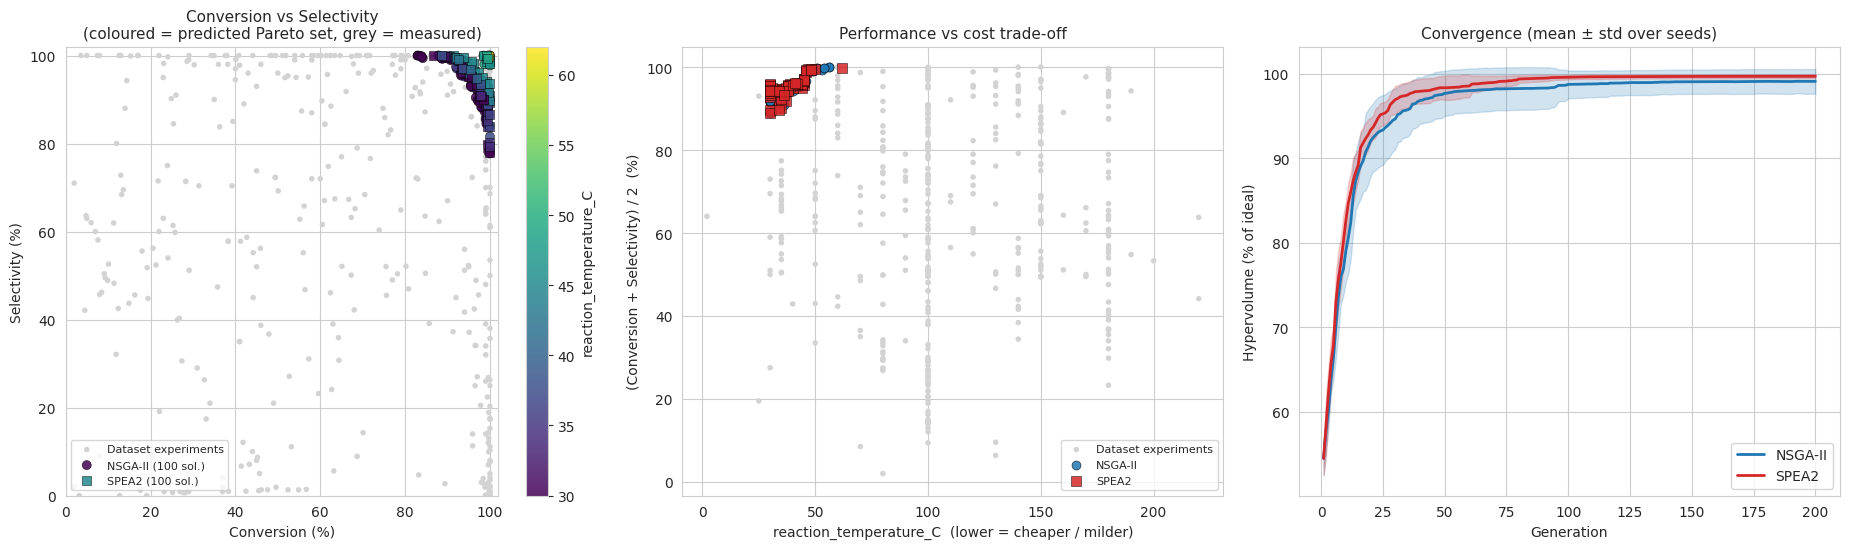

In [107]:
_col = {'NSGA-II': 'tab:blue', 'SPEA2': 'tab:red'}; _mk = {'NSGA-II': 'o', 'SPEA2': 's'}
exp_pts_s = np.column_stack([y_conv_full.values, y_sel_full.values])
exp_extra = X_full_reduced[S_EXTRA_COL].to_numpy(dtype=float) if S_EXTRA else None
n_pan = 3 if S_EXTRA else 2
fig, axes = plt.subplots(1, n_pan, figsize=(6.2 * n_pan, 5.6))

ax = axes[0]
ax.scatter(exp_pts_s[:, 0], exp_pts_s[:, 1], s=16, c='lightgray', edgecolor='none', label='Dataset experiments')
sc_last = None
for a in shap_moo_results:
    best = max(shap_moo_results[a], key=lambda r: _hvS(r['F'])); F = best['F']
    if S_EXTRA:
        sc_last = ax.scatter(-F[:, 0], -F[:, 1], c=F[:, 2], cmap='viridis', marker=_mk[a], s=42, edgecolor='k',
                             linewidth=0.4, alpha=0.85, label=f'{a} ({len(F)} sol.)')
    else:
        ax.scatter(-F[:, 0], -F[:, 1], marker=_mk[a], s=40, color=_col[a], edgecolor='k', linewidth=0.3, alpha=0.8,
                   label=f'{a} ({len(F)} sol.)')
if sc_last is not None:
    plt.colorbar(sc_last, ax=ax, label=S_EXTRA_COL)
ax.set_xlabel('Conversion (%)'); ax.set_ylabel('Selectivity (%)')
ax.set_title('Conversion vs Selectivity\n(coloured = predicted Pareto set, grey = measured)', fontsize=11)
ax.set_xlim(0, 102); ax.set_ylim(0, 102); ax.legend(loc='lower left', fontsize=8)

if S_EXTRA:
    ax = axes[1]
    ax.scatter(exp_extra, exp_pts_s.mean(axis=1), s=16, c='lightgray', edgecolor='none', label='Dataset experiments')
    for a in shap_moo_results:
        best = max(shap_moo_results[a], key=lambda r: _hvS(r['F'])); F = best['F']
        ax.scatter(F[:, 2], (-F[:, 0] - F[:, 1]) / 2, marker=_mk[a], s=42, color=_col[a], edgecolor='k',
                   linewidth=0.4, alpha=0.85, label=a)
    ax.set_xlabel(S_EXTRA_COL + '  (lower = cheaper / milder)'); ax.set_ylabel('(Conversion + Selectivity) / 2  (%)')
    ax.set_title('Performance vs cost trade-off', fontsize=11); ax.legend(fontsize=8, loc='lower right')

ax = axes[-1]
for a in shap_moo_results:
    H = 100 * np.array([r['hv_hist'] for r in shap_moo_results[a]]) / S_HV_IDEAL; g_ = np.arange(1, H.shape[1] + 1)
    ax.plot(g_, H.mean(axis=0), color=_col[a], lw=2, label=a)
    ax.fill_between(g_, H.mean(axis=0) - H.std(axis=0), H.mean(axis=0) + H.std(axis=0), color=_col[a], alpha=0.2)
ax.set_xlabel('Generation'); ax.set_ylabel('Hypervolume (% of ideal)'); ax.set_title('Convergence (mean ± std over seeds)', fontsize=11)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "moo_shap_pareto_and_convergence.png"), dpi=200, bbox_inches='tight')
plt.show()

## 58.9 The Pareto-optimal conditions, decoded
Runs of both algorithms are pooled, de-duplicated and re-filtered to one non-dominated set. Each solution lists the
SHAP-variable settings, the predicted Conversion / Selectivity, and its **nearest real experiment** (distance measured on
the SHAP variables) with that experiment's measured results. Marked solutions: **Max-Conversion**, **Max-Selectivity**,
**Compromise (knee)** (closest to the ideal corner after normalising the objectives) and, if a cost objective is on, the
**cheapest solution that still gives ≥ 95 % Conversion and ≥ 95 % Selectivity**.

In [108]:
Xp = np.vstack([r['X'] for a in shap_moo_results for r in shap_moo_results[a]])
Fp_ = np.vstack([r['F'] for a in shap_moo_results for r in shap_moo_results[a]])
_, u = np.unique(np.round(Xp, 4), axis=0, return_index=True)
Xp, Fp_ = Xp[np.sort(u)], Fp_[np.sort(u)]
nd = NonDominatedSorting().do(Fp_, only_non_dominated_front=True)
X_spf, F_spf = Xp[nd], Fp_[nd]
spf_df = decode_shap(X_spf)                                   # full feature rows (reduced space)

shap_pareto = pd.DataFrame(X_spf, columns=S_VARS)
shap_pareto['Pred_Conversion']  = -F_spf[:, 0]
shap_pareto['Pred_Selectivity'] = -F_spf[:, 1]
shap_pareto['_src'] = np.arange(len(X_spf))

# nearest real experiment, measured on the SHAP variables only
_sc_s = StandardScaler().fit(X_full_reduced[S_VARS])
_nn_s = NearestNeighbors(n_neighbors=1).fit(_sc_s.transform(X_full_reduced[S_VARS]))
_d, _i = _nn_s.kneighbors(_sc_s.transform(shap_pareto[S_VARS]))
_nn_idx = X_full_reduced.index[_i.ravel()]
shap_pareto['Nearest real experiment'] = [exp_label(i) for i in _nn_idx]
shap_pareto['NN meas. Conv'] = y_conv_full.loc[_nn_idx].to_numpy()
shap_pareto['NN meas. Sel']  = y_sel_full.loc[_nn_idx].to_numpy()
shap_pareto['NN distance (SHAP vars)'] = _d.ravel()

shap_pareto = shap_pareto.sort_values(['Pred_Conversion', 'Pred_Selectivity'], ascending=False).reset_index(drop=True)

# degeneracy check
conv_rng = shap_pareto['Pred_Conversion'].max() - shap_pareto['Pred_Conversion'].min()
sel_rng  = shap_pareto['Pred_Selectivity'].max() - shap_pareto['Pred_Selectivity'].min()
print(f"Pooled Pareto set: {len(shap_pareto)} distinct non-dominated solutions")
print(f"Range across the set: Conversion {conv_rng:.2f} points, Selectivity {sel_rng:.2f} points")
if conv_rng < 1 and sel_rng < 1 and not S_EXTRA:
    print("-> WARNING: Conversion and Selectivity barely differ across the 'front' - the two objectives are not in conflict "
          "in this search space (a single ideal point exists). Turn on SHAP_EXTRA_OBJECTIVE to expose a real trade-off.")

# roles
shap_pareto['Role'] = ''
shap_pareto.loc[shap_pareto['Pred_Conversion'].idxmax(),  'Role'] += 'Max-Conversion '
shap_pareto.loc[shap_pareto['Pred_Selectivity'].idxmax(), 'Role'] += 'Max-Selectivity '
_objs = np.column_stack([-shap_pareto['Pred_Conversion'], -shap_pareto['Pred_Selectivity']] + ([shap_pareto[S_EXTRA_COL]] if S_EXTRA else []))
_rng = _objs.max(axis=0) - _objs.min(axis=0)
_knee = int(np.argmin(np.linalg.norm((_objs - _objs.min(axis=0)) / np.where(_rng == 0, 1, _rng), axis=1)))
shap_pareto.loc[_knee, 'Role'] += 'Compromise(knee) '
if S_EXTRA:
    ok = shap_pareto[(shap_pareto['Pred_Conversion'] >= 95) & (shap_pareto['Pred_Selectivity'] >= 95)]
    if len(ok):
        shap_pareto.loc[ok[S_EXTRA_COL].idxmin(), 'Role'] += f'Cheapest(>=95/95, min {S_EXTRA_COL})'
    else:
        print("No Pareto solution reaches >=95 % on both targets.")

shap_pareto_view = shap_pareto.drop(columns='_src')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
display(shap_pareto_view.round(3).head(20))
print("\nRole-tagged solutions:")
display(shap_pareto_view[shap_pareto_view['Role'] != ''].round(3).T)

Pooled Pareto set: 166 distinct non-dominated solutions
Range across the set: Conversion 13.38 points, Selectivity 21.95 points


,reaction_time_h,reaction_temperature_C,Solvent_dipole_moment_D,Calcination_temperature_C,Surface_Area_m2_g,Solvent_density_g_mL,reaction_pressure_MPa,Reducing_temperature_C,Reactive_metal_1_d_band_filling,Reactive_metal_1_Loading_wt,Solvent_boiling_point_C,FFR_loading_g,Catalyst_loading_g,Solvent_viscosity_cP_20_25C,Pred_Conversion,Pred_Selectivity,Nearest real experiment,NN meas. Conv,NN meas. Sel,NN distance (SHAP vars),Role
0,8.771,56.048,1.242,0.093,580.792,0.766,4.379,16.159,0.842,20.173,95.851,0.097,0.076,2.122,100.000,100.000,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,2.008,Max-Conversion Max-Selectivity
1,10.819,56.223,1.319,0.066,580.775,0.778,3.725,16.159,0.842,20.201,89.230,0.110,0.076,1.966,100.000,100.000,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,1.795,
2,10.265,56.421,1.079,0.011,655.191,0.763,4.713,0.018,0.795,18.740,90.128,0.097,0.077,2.287,100.000,100.000,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,2.370,
3,8.649,54.013,1.172,0.733,576.065,0.768,4.104,16.889,0.762,20.161,86.573,0.101,0.076,2.191,100.000,99.595,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,1.820,
4,8.649,54.013,1.172,0.733,569.549,0.768,4.104,79.764,0.758,20.161,86.573,0.101,0.076,2.214,100.000,99.595,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,1.902,
5,8.355,50.229,1.339,0.291,515.688,0.764,3.295,61.476,0.804,14.669,80.554,0.109,0.076,2.231,100.000,98.951,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,1.331,
6,8.800,47.982,1.301,0.148,527.545,0.779,3.305,73.747,0.825,14.639,81.482,0.109,0.078,2.065,100.000,98.903,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,1.464,
7,8.764,46.389,1.446,0.152,524.751,0.778,3.640,55.735,0.814,14.683,81.381,0.101,0.077,1.915,100.000,98.259,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,0.986,
8,10.478,45.620,1.090,0.314,515.644,0.775,3.496,32.296,0.827,14.676,81.095,0.074,0.086,2.313,100.000,93.565,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,2.210,
9,9.464,44.043,0.471,0.045,515.535,0.756,4.621,7.377,0.811,14.890,96.317,0.099,0.273,2.179,100.000,91.424,Ni/AC | isopropanol | H2 source: H2,100.0,100.0,4.263,



Role-tagged solutions:


,0,98,101
reaction_time_h,8.771,10.366,9.271
reaction_temperature_C,56.048,30.499,30.243
Solvent_dipole_moment_D,1.242,1.158,1.029
Calcination_temperature_C,0.093,0.284,0.567
Surface_Area_m2_g,580.792,514.325,517.007
Solvent_density_g_mL,0.766,0.779,0.779
reaction_pressure_MPa,4.379,4.737,4.364
Reducing_temperature_C,16.159,59.774,62.48
Reactive_metal_1_d_band_filling,0.842,0.823,0.825
Reactive_metal_1_Loading_wt,20.173,9.619,9.639


## 58.10 Credibility checks
1. **Independent-model cross-check.** Re-predict every solution with a *different* trained model (best model in the plain
   reduced feature space, not the SHAP model). Large disagreement = the optimiser is exploiting one model's error.
2. **Applicability domain.** Distance of each full candidate (all features) to the nearest real experiment, compared with how
   far real experiments are from each other.
3. **Bound hits.** Which variables the optimiser pushes to the edge of their allowed range. A variable pinned at its
   upper bound means "the model wants even more than the data contains" — treat that as extrapolation, not a finding.

In [109]:
# ---- 1) cross-check with an independent model in the reduced feature space ----
_RED = {'RF (grid)', 'XGB (grid)', 'GB (grid)', 'Stacked', 'CatBoost', 'ExtraTrees', 'XGB-Optuna', 'LGB-Optuna',
        'CAT-Optuna', 'Mega Stacked', 'XGB (outliers removed)', 'FLAML AutoML'}
def pick_alt_model(target):
    tname = 'Conversion' if target == 'conv' else 'Selectivity'
    reg = model_registry_conv if target == 'conv' else model_registry_sel
    for _, row in grand_summary_v4_sorted[grand_summary_v4_sorted['Target'] == tname].iterrows():
        if row['Model'] in _RED and row['Model'] in reg:
            return row['Model'], reg[row['Model']]
    return None, None
alt_c_name, alt_c_model = pick_alt_model('conv'); alt_s_name, alt_s_model = pick_alt_model('sel')

src = shap_pareto['_src'].to_numpy()
cand = spf_df.iloc[src].reset_index(drop=True)                 # candidates in table order
if alt_c_model is not None and alt_s_model is not None:
    shap_pareto['Alt_Conversion']  = np.clip(np.asarray(alt_c_model.predict(cand)).ravel(), 0, 100)
    shap_pareto['Alt_Selectivity'] = np.clip(np.asarray(alt_s_model.predict(cand)).ravel(), 0, 100)
    shap_pareto['|Δ Conv|'] = (shap_pareto['Pred_Conversion'] - shap_pareto['Alt_Conversion']).abs()
    shap_pareto['|Δ Sel|']  = (shap_pareto['Pred_Selectivity'] - shap_pareto['Alt_Selectivity']).abs()
    print(f"Cross-check models: Conversion = {alt_c_name}, Selectivity = {alt_s_name}")
    print(f"  mean |Δ Conversion|  = {shap_pareto['|Δ Conv|'].mean():.2f} pts (max {shap_pareto['|Δ Conv|'].max():.2f})")
    print(f"  mean |Δ Selectivity| = {shap_pareto['|Δ Sel|'].mean():.2f} pts (max {shap_pareto['|Δ Sel|'].max():.2f})")
else:
    print("No reduced-space model available for the cross-check - skipped.")

# ---- 2) applicability domain on the FULL feature vector ----
_Zs = scaler_nn.transform(X_full_reduced)
_nn_full = NearestNeighbors(n_neighbors=2).fit(_Zs)
_thr = np.percentile(_nn_full.kneighbors(_Zs)[0][:, 1], 95)
shap_pareto['NN_distance_full'] = _nn_full.kneighbors(scaler_nn.transform(cand), n_neighbors=1)[0].ravel()
shap_pareto['Extrapolating'] = shap_pareto['NN_distance_full'] > _thr
print(f"Applicability domain: {shap_pareto['Extrapolating'].mean() * 100:.0f}% of solutions are farther from any real experiment "
      f"than 95% of real experiments are from each other (threshold {_thr:.2f}).")

# ---- 3) bound hits ----
hits = []
for c in S_VARS:
    lo, hi = lo_hi_s[c]; w = hi - lo
    hits.append({'Variable': c, 'lower': lo, 'upper': hi,
                 '% at lower bound': 100 * (shap_pareto[c] <= lo + 0.02 * w).mean(),
                 '% at upper bound': 100 * (shap_pareto[c] >= hi - 0.02 * w).mean(),
                 'min on front': shap_pareto[c].min(), 'max on front': shap_pareto[c].max()})
bound_hits = pd.DataFrame(hits).set_index('Variable')
display(bound_hits.round(3))
pinned = bound_hits[(bound_hits['% at lower bound'] > 50) | (bound_hits['% at upper bound'] > 50)]
if len(pinned):
    print("Variables pinned at a bound for >50% of the front (check whether that is physically sensible):", list(pinned.index))

shap_pareto_view = shap_pareto.drop(columns='_src')
shap_trusted = shap_pareto_view[(shap_pareto_view.get('|Δ Conv|', 0) < 10) & (shap_pareto_view.get('|Δ Sel|', 0) < 10)
                                & (~shap_pareto_view['Extrapolating'])]
print(f"\nSolutions passing cross-check (<10 pts) and applicability domain: {len(shap_trusted)} of {len(shap_pareto_view)}")

Cross-check models: Conversion = CatBoost, Selectivity = Mega Stacked
  mean |Δ Conversion|  = 6.95 pts (max 22.46)
  mean |Δ Selectivity| = 6.41 pts (max 14.89)
Applicability domain: 19% of solutions are farther from any real experiment than 95% of real experiments are from each other (threshold 3.39).


,lower,upper,% at lower bound,% at upper bound,min on front,max on front
Variable,,,,,,
reaction_time_h,0.333,12.000,0.000,0.000,7.487,10.886
reaction_temperature_C,30.000,187.500,21.084,0.000,30.006,56.421
Solvent_dipole_moment_D,0.000,1.850,0.000,0.000,0.390,1.448
Calcination_temperature_C,0.000,600.000,100.000,0.000,0.000,0.899
Surface_Area_m2_g,7.000,1340.000,0.000,0.000,129.898,741.673
Solvent_density_g_mL,0.667,1.033,0.000,0.000,0.743,0.789
reaction_pressure_MPa,0.100,6.000,0.000,0.000,3.208,5.365
Reducing_temperature_C,0.000,675.000,10.843,0.000,0.018,212.657
Reactive_metal_1_d_band_filling,0.700,1.000,0.000,0.000,0.753,0.952


Variables pinned at a bound for >50% of the front (check whether that is physically sensible): ['Calcination_temperature_C', 'FFR_loading_g']

Solutions passing cross-check (<10 pts) and applicability domain: 116 of 166


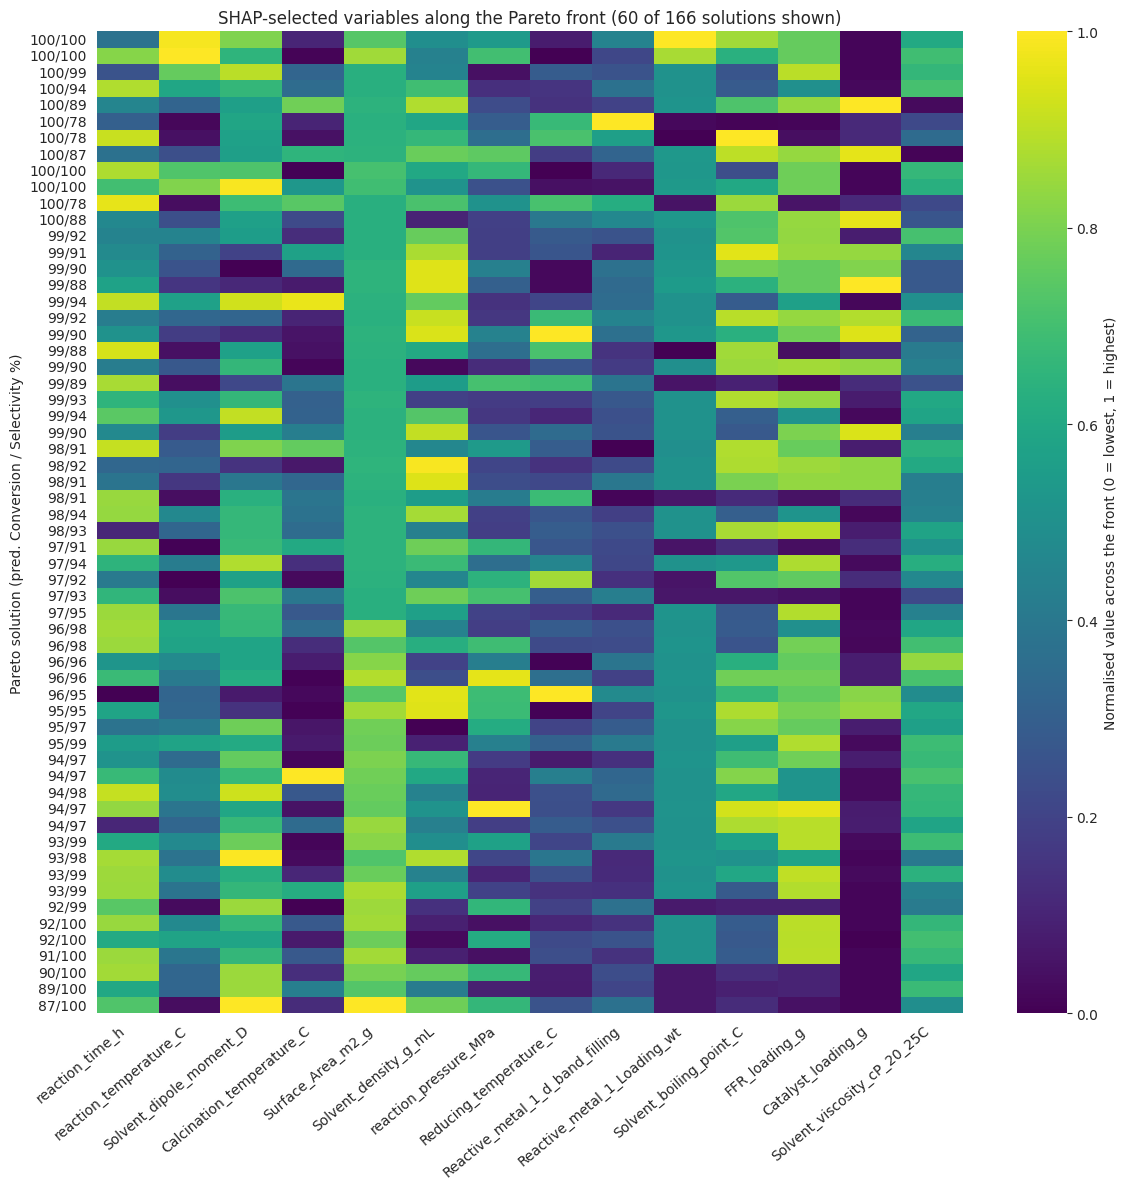

In [110]:
# Heatmap of the decision variables along the front (<= 60 evenly spaced solutions shown)
show = np.arange(len(shap_pareto)) if len(shap_pareto) <= 60 else np.linspace(0, len(shap_pareto) - 1, 60).astype(int)
_dv = shap_pareto.loc[show, S_VARS]
_rngv = (shap_pareto[S_VARS].max() - shap_pareto[S_VARS].min()).replace(0, 1)
_dvn = (_dv - shap_pareto[S_VARS].min()) / _rngv
fig, ax = plt.subplots(figsize=(12, min(12, max(4, 0.22 * len(_dvn) + 2))))
sns.heatmap(_dvn.values, cmap='viridis', ax=ax, xticklabels=S_VARS,
            yticklabels=[f"{c:.0f}/{s:.0f}" for c, s in zip(shap_pareto.loc[show, 'Pred_Conversion'], shap_pareto.loc[show, 'Pred_Selectivity'])],
            cbar_kws={'label': 'Normalised value across the front (0 = lowest, 1 = highest)'})
ax.set_ylabel('Pareto solution (pred. Conversion / Selectivity %)')
ax.set_title(f'SHAP-selected variables along the Pareto front ({len(show)} of {len(shap_pareto)} solutions shown)')
plt.xticks(rotation=40, ha='right'); plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "moo_shap_pareto_decision_heatmap.png"), dpi=200, bbox_inches='tight')
plt.show()

## 58.11 Optimiser vs the best real experiments
How do the optimiser's solutions compare with what has actually been measured? If a cost objective is on, the table also shows
the **mildest real experiment that already reaches ≥ 90 % on both targets**, which is the fair baseline for the cost objective.

In [111]:
_ec = exp_pts_s
def _row(src, conv, sel, extra=None):
    d = {'Source': src, 'Conv': conv, 'Sel': sel}
    if S_EXTRA:
        d[S_EXTRA_COL] = extra
    return d
rows = []
for lbl, j in [('Dataset: highest Conversion', int(np.argmax(_ec[:, 0]))),
               ('Dataset: highest Selectivity', int(np.argmax(_ec[:, 1]))),
               ('Dataset: best Conv + Sel', int(np.argmax(_ec.sum(1))))]:
    rows.append(_row(lbl, _ec[j, 0], _ec[j, 1], exp_extra[j] if S_EXTRA else None))
if S_EXTRA:
    good = np.where((_ec[:, 0] >= 90) & (_ec[:, 1] >= 90))[0]
    if len(good):
        j = good[np.argmin(exp_extra[good])]
        rows.append(_row(f'Dataset: lowest {S_EXTRA_COL} with both >=90%', _ec[j, 0], _ec[j, 1], exp_extra[j]))
for lbl, i in [('MOO: max Conversion', shap_pareto['Pred_Conversion'].idxmax()),
               ('MOO: max Selectivity', shap_pareto['Pred_Selectivity'].idxmax())]:
    r = shap_pareto.loc[i]
    rows.append(_row(lbl, r['Pred_Conversion'], r['Pred_Selectivity'], r[S_EXTRA_COL] if S_EXTRA else None))
for _, r in shap_pareto[shap_pareto['Role'].str.contains('knee|Cheapest')].iterrows():
    rows.append(_row('MOO: ' + r['Role'].strip(), r['Pred_Conversion'], r['Pred_Selectivity'], r[S_EXTRA_COL] if S_EXTRA else None))
shap_compare = pd.DataFrame(rows).round(2)
display(shap_compare)

,Source,Conv,Sel,reaction_temperature_C
0,Dataset: highest Conversion,100.00,26.30,100.00
1,Dataset: highest Selectivity,77.60,100.00,100.00
2,Dataset: best Conv + Sel,100.00,100.00,60.00
3,Dataset: lowest reaction_temperature_C with bo...,90.70,93.50,50.00
4,MOO: max Conversion,100.00,100.00,56.05
5,MOO: max Selectivity,100.00,100.00,56.05
6,MOO: Compromise(knee),96.66,94.84,30.50
7,"MOO: Cheapest(>=95/95, min reaction_temperatur...",96.07,95.04,30.24


## 58.12 Save results & auto-download

In [112]:
x_path = os.path.join(MODEL_DIR, "moo_shap_pareto_solutions.xlsx")
with pd.ExcelWriter(x_path) as writer:
    shap_pareto.drop(columns='_src').to_excel(writer, sheet_name='Pareto solutions', index=False)
    shap_trusted.to_excel(writer, sheet_name='Passed checks', index=False)
    shap_feature_table.to_excel(writer, sheet_name='SHAP features >threshold', index=False)
    shap_moo_metrics.to_excel(writer, sheet_name='Algorithm comparison')
    shap_compare.to_excel(writer, sheet_name='vs dataset best', index=False)
    bounds_s.to_excel(writer, sheet_name='Variable bounds')
    bound_hits.to_excel(writer, sheet_name='Bound hits')
    context_row.to_frame('reference_experiment_value').to_excel(writer, sheet_name='Frozen reference experiment')
shap_pareto.drop(columns='_src').to_csv(os.path.join(MODEL_DIR, "moo_shap_pareto_solutions.csv"), index=False)
print("Saved:", x_path)

try:
    from google.colab import files
    to_dl = [x_path, os.path.join(MODEL_DIR, "moo_shap_pareto_solutions.csv")] + \
            [os.path.join(FIGURE_DIR, f) for f in ["moo_shap_selected_features.png", "moo_shap_pareto_and_convergence.png",
                                                    "moo_shap_pareto_decision_heatmap.png"]]
    for fp in to_dl:
        if os.path.exists(fp):
            files.download(fp)
    print(f"Triggered browser download for {len(to_dl)} files.")
except ImportError:
    print("Not running in Colab - files saved in", MODEL_DIR, "and", FIGURE_DIR)

Saved: /content/drive/MyDrive/BTP_Sem_7/saved_models/moo_shap_pareto_solutions.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggered browser download for 5 files.


---
# 59. Full catalyst + reaction feature set for every MOO Pareto solution

Sections 1-58 are untouched. The Section 58 results table only lists the handful of SHAP-selected variables the optimiser
tuned. This section rebuilds the **complete feature row for every Pareto solution, with every column the dataset has**
(and the original dataset column names), so each optimum can be read as a full experiment:

- all 35 model features (metal-1 / metal-2 descriptors, support descriptors, surface area, reduction / calcination
  temperature, solvent descriptors, H2 source, H-bond flags, loadings, T, P, time, ...)
- the 5 features that were dropped earlier as collinear (d-electron counts, ionisation energies, dielectric constant)
- the one-hot columns decoded back to readable categories (H2 source, solvent H-bond donor / acceptor)
- the identity of the **closest real experiment** (catalyst type, metals, support, solvent) and its measured results
- a **provenance sheet** saying, for every column, whether the optimiser *searched* it or it was *held fixed*

> **How to read it.** Only the SHAP-selected variables (`S_VARS`) are actually searched by NSGA-II / SPEA2. Every other
> column is held at the reference experiment's value (Section 58.3), so it is *part of the solution*, but it was not
> *discovered* by the optimiser. The provenance sheet and the coloured Excel headers make that explicit.

In [113]:
# ---------------------------------------------------------------------------------------------
# 59.1  Rebuild the complete feature row for every Pareto solution
# ---------------------------------------------------------------------------------------------
CAT_ORIG_COLS = ['Catalyst type', 'Reactive metal 1', 'Reactive metal 2', 'Support', 'Solvent type']
ONEHOT_ORIG   = ['H2 source', 'Solvent H-bond donor', 'Solvent H-bond acceptor']

src = shap_pareto['_src'].to_numpy()
cand_full = spf_df.iloc[src].reset_index(drop=True)            # all 35 model features, same order as shap_pareto
assert list(cand_full.columns) == list(X_train_reduced.columns), "feature columns differ from the training space"
n_sol = len(cand_full)

# ---- closest real experiment in the FULL 35-feature space (identity + the 5 collinear features dropped earlier) ----
_Zall = scaler_nn.transform(X_full_reduced)
_nn_all = NearestNeighbors(n_neighbors=1).fit(_Zall)
_dist_all, _pos_all = _nn_all.kneighbors(scaler_nn.transform(cand_full))
nn_all_idx = X_full_reduced.index[_pos_all.ravel()]

dropped_feats = [c for c in X.columns if c not in X_train_reduced.columns]      # the 5 collinear features
dropped_df = X.loc[nn_all_idx, dropped_feats].reset_index(drop=True)

identity = df_clean.loc[nn_all_idx, CAT_ORIG_COLS].reset_index(drop=True)
identity.columns = [f'Closest real exp: {c}' for c in CAT_ORIG_COLS]
identity['Closest real exp: measured Conversion (%)']  = y_conv_full.loc[nn_all_idx].to_numpy()
identity['Closest real exp: measured Selectivity (%)'] = y_sel_full.loc[nn_all_idx].to_numpy()
identity['Distance to closest real exp (standardised, all features)'] = _dist_all.ravel()

# ---- decode the one-hot columns back to readable categories ----
def decode_onehot(df_feat, orig_col):
    cats = sorted(df_clean[orig_col].dropna().unique(), key=str)       # pd.get_dummies(drop_first=True) drops cats[0]
    col_to_cat = {clean_col_name(f"{orig_col}_{c}"): c for c in cats}
    present = [c for c in df_feat.columns if c in col_to_cat]
    out = []
    for _, r in df_feat[present].iterrows():
        on = [col_to_cat[c] for c in present if float(r[c]) > 0.5]
        out.append(on[0] if on else cats[0])
    return out

# sanity check on REAL data: decoding must reproduce the real categories
for oc in ONEHOT_ORIG:
    _dec = np.array(decode_onehot(X_full_reduced, oc), dtype=str)
    _true = df_clean.loc[X_full_reduced.index, oc].astype(str).to_numpy()
    print(f"one-hot decode check on real experiments - {oc:25s}: {100 * np.mean(_dec == _true):.1f}% match")

decoded = pd.DataFrame({f'{oc} (decoded)': decode_onehot(cand_full, oc) for oc in ONEHOT_ORIG})

# ---- all features together, in the ORIGINAL dataset column order + original names ----
clean_to_orig = {clean_col_name(c): c for c in df_clean.columns}
all_feats = pd.concat([cand_full, dropped_df], axis=1)
ordered = [clean_col_name(c) for c in df_clean.columns if clean_col_name(c) in all_feats.columns]
ordered += [c for c in all_feats.columns if c not in ordered]                    # one-hot dummies go last
all_feats = all_feats[ordered].rename(columns=clean_to_orig)

full_table = pd.concat([
    shap_pareto[['Role', 'Pred_Conversion', 'Pred_Selectivity']].reset_index(drop=True),
    identity, decoded, all_feats
], axis=1)
if 'Alt_Conversion' in shap_pareto.columns:
    full_table['Alt model Conversion']  = shap_pareto['Alt_Conversion'].to_numpy()
    full_table['Alt model Selectivity'] = shap_pareto['Alt_Selectivity'].to_numpy()
    full_table['Extrapolating'] = shap_pareto['Extrapolating'].to_numpy()
full_table.insert(0, 'Solution #', np.arange(1, n_sol + 1))
full_table = full_table.loc[:, ~full_table.columns.duplicated()]

# ---- provenance: searched vs fixed, for every feature column ----
def _prov(clean_name):
    if clean_name in S_VARS:
        return 'SEARCHED by NSGA-II / SPEA2 (SHAP-selected)'
    if clean_name in dropped_feats:
        return 'Not modelled (collinear, dropped in Sec. 11) - copied from closest real experiment'
    if clean_name in frozen_binary:
        return 'SHAP-selected but categorical (0/1) - held fixed at reference experiment'
    return 'Held fixed at reference experiment'
prov = pd.DataFrame({'Column (original name)': [clean_to_orig.get(c, c) for c in ordered],
                     'Column (model name)': ordered,
                     'Status': [_prov(c) for c in ordered],
                     'Reference-experiment value': [float(X.loc[ctx_idx, c]) if c in X.columns else np.nan for c in ordered],
                     'Min on Pareto set': [float(all_feats[clean_to_orig.get(c, c)].min()) for c in ordered],
                     'Max on Pareto set': [float(all_feats[clean_to_orig.get(c, c)].max()) for c in ordered]})
n_s = (prov['Status'].str.startswith('SEARCHED')).sum()
print(f"\n{n_sol} Pareto solutions x {all_feats.shape[1]} dataset features "
      f"({n_s} searched by the optimiser, {all_feats.shape[1] - n_s} held fixed / copied).")
print("Reference experiment used for the fixed features:", exp_label(ctx_idx))
display(prov)

one-hot decode check on real experiments - H2 source                : 100.0% match
one-hot decode check on real experiments - Solvent H-bond donor     : 100.0% match
one-hot decode check on real experiments - Solvent H-bond acceptor  : 100.0% match

166 Pareto solutions x 40 dataset features (14 searched by the optimiser, 26 held fixed / copied).
Reference experiment used for the fixed features: Ni/AC | isopropanol | H2 source: H2


,Column (original name),Column (model name),Status,Reference-experiment value,Min on Pareto set,Max on Pareto set
0,Surface Area (m2/g),Surface_Area_m2_g,SEARCHED by NSGA-II / SPEA2 (SHAP-selected),519.000000,129.897793,741.672918
1,Reactive metal 1 Loading (wt.%),Reactive_metal_1_Loading_wt,SEARCHED by NSGA-II / SPEA2 (SHAP-selected),14.780000,8.946396,20.201153
2,Reactive metal 2 Loading (wt.%),Reactive_metal_2_Loading_wt,Held fixed at reference experiment,0.000000,0.000000,0.000000
3,Reducing temperature (C),Reducing_temperature_C,SEARCHED by NSGA-II / SPEA2 (SHAP-selected),0.000000,0.000000,212.000000
4,Calcination temperature (C),Calcination_temperature_C,SEARCHED by NSGA-II / SPEA2 (SHAP-selected),0.000000,0.000000,0.000000
5,Solvent volume (ml),Solvent_volume_ml,Held fixed at reference experiment,5.000000,5.000000,5.000000
6,reaction temperature (C),reaction_temperature_C,SEARCHED by NSGA-II / SPEA2 (SHAP-selected),60.000000,30.000000,56.000000
7,reaction pressure (MPa),reaction_pressure_MPa,SEARCHED by NSGA-II / SPEA2 (SHAP-selected),4.000000,3.208327,5.365448
8,reaction time (h),reaction_time_h,SEARCHED by NSGA-II / SPEA2 (SHAP-selected),8.000000,7.487190,10.886153
9,FFR loading (g),FFR_loading_g,SEARCHED by NSGA-II / SPEA2 (SHAP-selected),0.076864,0.030951,0.117756


In [114]:
# ---------------------------------------------------------------------------------------------
# 59.2  Look at the tagged solutions with EVERY feature, then save + download
# ---------------------------------------------------------------------------------------------
pd.set_option('display.max_rows', 200); pd.set_option('display.max_columns', None)
tagged = full_table[full_table['Role'] != '']
print("Max-Conversion / Max-Selectivity / Compromise / Cheapest solutions - every feature:")
display(tagged.set_index('Solution #').T)

full_xlsx = os.path.join(MODEL_DIR, "moo_pareto_ALL_features.xlsx")
full_csv  = os.path.join(MODEL_DIR, "moo_pareto_ALL_features.csv")
with pd.ExcelWriter(full_xlsx, engine='openpyxl') as writer:
    full_table.to_excel(writer, sheet_name='All Pareto - all features', index=False)
    tagged.to_excel(writer, sheet_name='Tagged solutions', index=False)
    prov.to_excel(writer, sheet_name='Feature provenance', index=False)
    # colour the header of every column the optimiser actually searched
    from openpyxl.styles import PatternFill, Font
    ws = writer.sheets['All Pareto - all features']
    searched = {clean_to_orig.get(c, c) for c in S_VARS}
    for cell in ws[1]:
        cell.font = Font(bold=True)
        if cell.value in searched:
            cell.fill = PatternFill('solid', start_color='FFC000')       # orange = searched by MOO
        elif cell.value in set(all_feats.columns):
            cell.fill = PatternFill('solid', start_color='D9E1F2')       # light blue = fixed / copied
full_table.to_csv(full_csv, index=False)
print("Saved:", full_xlsx, "\n       ", full_csv)
print("Excel header colours: orange = searched by the optimiser | light blue = held fixed / copied")

try:
    from google.colab import files
    for fp in [full_xlsx, full_csv]:
        files.download(fp)
except ImportError:
    print("Not running in Colab - files saved in", MODEL_DIR)

Max-Conversion / Max-Selectivity / Compromise / Cheapest solutions - every feature:


Solution #,1,99,102
Role,Max-Conversion Max-Selectivity,Compromise(knee),"Cheapest(>=95/95, min reaction_temperature_C)"
Pred_Conversion,100.0,96.658103,96.06959
Pred_Selectivity,100.0,94.838717,95.043138
Closest real exp: Catalyst type,Ni/AC,Ni/AC,Ni/AC
Closest real exp: Reactive metal 1,Ni,Ni,Ni
Closest real exp: Reactive metal 2,0,0,0
Closest real exp: Support,AC,AC,AC
Closest real exp: Solvent type,isopropanol,isopropanol,isopropanol
Closest real exp: measured Conversion (%),100.0,100.0,100.0
Closest real exp: measured Selectivity (%),100.0,100.0,100.0


Saved: /content/drive/MyDrive/BTP_Sem_7/saved_models/moo_pareto_ALL_features.xlsx 
        /content/drive/MyDrive/BTP_Sem_7/saved_models/moo_pareto_ALL_features.csv
Excel header colours: orange = searched by the optimiser | light blue = held fixed / copied


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# 60. FINAL - best solution from the better of NSGA-II / SPEA2, with every feature
One table per MOO section (58 and, if run, 57). **Better algorithm** = higher mean hypervolume over all seeds (if the gap is within the seed-to-seed spread, lower IGD+ decides). **Best solution** = highest (Conversion + Selectivity)/2 on that algorithm's pooled Pareto front, ties broken by the lowest reaction temperature. The last column says whether each feature was *searched* by the optimiser, *fixed*, or *copied/labelled* from a real experiment.

In [115]:
# =====================================================================================================
# FINAL RESULT - the single best solution found by the BETTER of NSGA-II / SPEA2, with EVERY feature
#   * better algorithm = higher mean hypervolume over all seeds (if the gap is smaller than the seed-to-seed std -> lower IGD+)
#   * best solution    = highest (Conversion + Selectivity)/2 on that algorithm's pooled Pareto front;
#                        ties (within 0.05 pt) are broken by the lowest reaction temperature
# Run AFTER section 58 (and 57 if you want that one too).
# =====================================================================================================
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
from sklearn.neighbors import NearestNeighbors

CAT_ORIG_COLS = ['Catalyst type', 'Reactive metal 1', 'Reactive metal 2', 'Support', 'Solvent type']
ONEHOT_ORIG   = ['H2 source', 'Solvent H-bond donor', 'Solvent H-bond acceptor']
dropped_feats = [c for c in X.columns if c not in X_train_reduced.columns]        # 5 collinear features removed in sec. 11

def pick_better_algorithm(metrics):
    top = metrics['HV mean'].idxmax()
    other = [a for a in metrics.index if a != top][0]
    gap, sd = metrics.loc[top, 'HV mean'] - metrics.loc[other, 'HV mean'], metrics['HV std'].max()
    if gap < sd:                                   # statistical tie on hypervolume -> decide on IGD+
        top = metrics['IGD+ mean'].idxmin()
        why = f"HV gap {gap:.1f} < seed std {sd:.1f} (tie) -> lower IGD+ decides"
    else:
        why = f"higher mean hypervolume (gap {gap:.1f} > seed std {sd:.1f})"
    return top, why

def pooled_front(run_list):
    Xp = np.vstack([r['X'] for r in run_list]); Fp = np.vstack([r['F'] for r in run_list])
    nd = NonDominatedSorting().do(Fp, only_non_dominated_front=True)
    return Xp[nd], Fp[nd]

def pick_best(Fp, temperature):
    score = -(Fp[:, 0] + Fp[:, 1]) / 2
    ok = np.where(score >= score.max() - 0.05)[0]
    return int(ok[np.argmin(np.asarray(temperature)[ok])])

def decode_onehot_1(row_df, oc):
    levels = sorted(df_clean[oc].dropna().unique(), key=str)                      # get_dummies(drop_first=True) dropped levels[0]
    for lv in levels[1:]:
        cn = clean_col_name(f"{oc}_{lv}")
        if cn in row_df.columns and float(row_df[cn].iloc[0]) > 0.5:
            return lv
    return levels[0]

def build_full_table(feat_row, labels, dropped_vals, pred_conv, pred_sel, status_of):
    # feat_row: 1-row frame (35 model features) | labels: dict of the 5 text columns | dropped_vals: dict of 5 collinear features
    allf = feat_row.copy()
    for d in dropped_feats:
        allf[d] = dropped_vals[d]
    rows = []
    for oc in df_clean.columns:
        cc = clean_col_name(oc)
        if oc in CAT_ORIG_COLS:    val, st = labels[oc], status_of('label', cc)
        elif oc in ONEHOT_ORIG:    val, st = decode_onehot_1(feat_row, oc), status_of('onehot', cc)
        elif cc == 'FFR_Conversion_Rate': val, st = pred_conv, 'PREDICTED by the surrogate model'
        elif cc == 'Selectivity':         val, st = pred_sel,  'PREDICTED by the surrogate model'
        elif cc in allf.columns:   val, st = float(allf[cc].iloc[0]), status_of('num', cc)
        else: continue
        rows.append({'Feature': oc, 'Value': val, 'How it was obtained': st})
    return pd.DataFrame(rows)

final_tables = {}

# ------------------------------------ Section 58 (SHAP-variable MOO) ------------------------------------
try:
    algo58, why58 = pick_better_algorithm(shap_moo_metrics)
    print("SECTION 58 -", shap_moo_metrics[['HV mean', 'HV std', 'IGD+ mean']].round(3).to_string())
    print(f"-> Better algorithm: {algo58}  ({why58})")
    Xp, Fp = pooled_front(shap_moo_results[algo58])
    cand_all = decode_shap(Xp)
    i = pick_best(Fp, cand_all['reaction_temperature_C'].to_numpy(dtype=float))
    cand = cand_all.iloc[[i]].reset_index(drop=True)
    pc, ps = float(-Fp[i, 0]), float(-Fp[i, 1])

    nn = NearestNeighbors(n_neighbors=1).fit(scaler_nn.transform(X_full_reduced))
    dist, pos = nn.kneighbors(scaler_nn.transform(cand))
    near = X_full_reduced.index[pos.ravel()[0]]
    labels = {c: df_clean.loc[near, c] for c in CAT_ORIG_COLS}
    dvals = {d: float(X.loc[near, d]) for d in dropped_feats}

    def st58(kind, cc):
        if kind == 'label':  return 'Name of the closest real experiment (label only)'
        if cc in S_VARS:     return 'SEARCHED by ' + algo58
        if cc in dropped_feats: return 'Copied from closest real experiment (collinear, not modelled)'
        return 'Fixed at reference experiment: ' + exp_label(ctx_idx)
    t58 = build_full_table(cand, labels, dvals, pc, ps, st58)
    final_tables['Section 58 (SHAP-variable MOO)'] = t58
    print(f"\nBest solution of {algo58}: Conversion {pc:.2f} %, Selectivity {ps:.2f} %  |  closest real experiment: "
          f"{exp_label(near)} (measured {y_conv_full.loc[near]:.1f} / {y_sel_full.loc[near]:.1f} %, distance {dist.ravel()[0]:.2f})\n")
    display(t58)
except NameError as e:
    print("Section 58 objects not found (", e, ") - run section 58 first.")

# ------------------------------------ Section 57 (classic MOO) ------------------------------------
try:
    algo57, why57 = pick_better_algorithm(moo_metrics)
    print("\nSECTION 57 -", moo_metrics[['HV mean', 'HV std', 'IGD+ mean']].round(3).to_string())
    print(f"-> Better algorithm: {algo57}  ({why57})")
    Xp, Fp = pooled_front(moo_results[algo57])
    cand_all = decode_population(Xp)
    i = pick_best(Fp, cand_all['reaction_temperature_C'].to_numpy(dtype=float))
    cand = cand_all.iloc[[i]].reset_index(drop=True)
    pc, ps = float(-Fp[i, 0]), float(-Fp[i, 1])

    ci, mi = decode_indices(Xp[[i]])
    cat_first, med_first = cat_catalog['first_idx'].to_numpy()[ci[0]], med_catalog['first_idx'].to_numpy()[mi[0]]
    labels = {c: df_clean.loc[cat_first, c] for c in ['Catalyst type', 'Reactive metal 1', 'Reactive metal 2', 'Support']}
    labels['Solvent type'] = df_clean.loc[med_first, 'Solvent type']
    dvals = {d: float(X.loc[med_first if d.startswith('Solvent') else cat_first, d]) for d in dropped_feats}

    def st57(kind, cc):
        if kind == 'label': return 'Real catalyst system / medium chosen by ' + algo57
        if cc in CONT_VARS: return 'SEARCHED by ' + algo57
        return 'Taken with the chosen real catalyst system / medium'
    t57 = build_full_table(cand, labels, dvals, pc, ps, st57)
    final_tables['Section 57 (classic MOO)'] = t57
    print(f"\nBest solution of {algo57}: Conversion {pc:.2f} %, Selectivity {ps:.2f} %\n")
    display(t57)
except NameError as e:
    print("Section 57 objects not found (", e, ") - skipped.")

# ------------------------------------ save ------------------------------------
if final_tables:
    out_x = os.path.join(MODEL_DIR, "BEST_solution_all_features.xlsx")
    with pd.ExcelWriter(out_x) as w:
        for nm, t in final_tables.items():
            t.to_excel(w, sheet_name=nm[:31], index=False)
    print("\nSaved:", out_x)
    try:
        from google.colab import files
        files.download(out_x)
    except ImportError:
        pass


SECTION 58 -                HV mean     HV std  IGD+ mean
Algorithm                                   
NSGA-II    1560358.132  22896.013      0.105
SPEA2      1569840.982   3460.786      0.058
-> Better algorithm: SPEA2  (HV gap 9482.8 < seed std 22896.0 (tie) -> lower IGD+ decides)

Best solution of SPEA2: Conversion 100.00 %, Selectivity 100.00 %  |  closest real experiment: Ni/AC | isopropanol | H2 source: H2 (measured 100.0 / 100.0 %, distance 2.26)



,Feature,Value,How it was obtained
0,Catalyst type,Ni/AC,Name of the closest real experiment (label only)
1,Surface Area (m2/g),655.190717,SEARCHED by SPEA2
2,Reactive metal 1,Ni,Name of the closest real experiment (label only)
3,Reactive metal 2,0,Name of the closest real experiment (label only)
4,Reactive metal 1 Loading (wt.%),18.740372,SEARCHED by SPEA2
5,Reactive metal 2 Loading (wt.%),0.0,Fixed at reference experiment: Ni/AC | isoprop...
6,Support,AC,Name of the closest real experiment (label only)
7,Reducing temperature (C),0.0,SEARCHED by SPEA2
8,Calcination temperature (C),0.0,SEARCHED by SPEA2
9,H2 source,H2,Fixed at reference experiment: Ni/AC | isoprop...



SECTION 57 -             HV mean  HV std  IGD+ mean
Algorithm                             
NSGA-II    9990.667   7.828      1.735
SPEA2      9989.583   8.515      1.808
-> Better algorithm: NSGA-II  (HV gap 1.1 < seed std 8.5 (tie) -> lower IGD+ decides)

Best solution of NSGA-II: Conversion 100.00 %, Selectivity 100.00 %



,Feature,Value,How it was obtained
0,Catalyst type,CuNi/MgAlO,Real catalyst system / medium chosen by NSGA-II
1,Surface Area (m2/g),112.2,Taken with the chosen real catalyst system / m...
2,Reactive metal 1,Cu,Real catalyst system / medium chosen by NSGA-II
3,Reactive metal 2,Ni,Real catalyst system / medium chosen by NSGA-II
4,Reactive metal 1 Loading (wt.%),47.114245,SEARCHED by NSGA-II
5,Reactive metal 2 Loading (wt.%),33.047825,SEARCHED by NSGA-II
6,Support,MgAlO,Real catalyst system / medium chosen by NSGA-II
7,Reducing temperature (C),600.0,Taken with the chosen real catalyst system / m...
8,Calcination temperature (C),0.0,Taken with the chosen real catalyst system / m...
9,H2 source,H2,Taken with the chosen real catalyst system / m...



Saved: /content/drive/MyDrive/BTP_Sem_7/saved_models/BEST_solution_all_features.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>